# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 10 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de 5 min de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações por sorteio.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../content/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

### Perguntas de negócio

**1. Operação — Em quais dias da semana e horários ocorre a maior concentração de pedidos?**

- Colunas: `data_hora`, `pedido_id`.
- Objetivo: identificar os períodos de maior demanda, permitindo melhorar o planejamento operacional e a disponibilidade de entregadores.

**2. Operação — Quais fatores estão associados ao aumento do tempo de entrega?**

- Colunas: `tempo_entrega_min`, `distancia_km`, `chuva`, `cidade`, `tipo_cozinha`.
- Objetivo: identificar fatores relacionados aos atrasos e oportunidades de melhoria na logística das entregas.

**3. Clientes — Como se comportam os valores dos pedidos e as avaliações dos clientes?**

- Colunas: `valor_pedido`, `avaliacao`, `cliente_novo`, `cidade`.
- Objetivo: compreender o comportamento de consumo e identificar oportunidades de melhoria na satisfação dos clientes.

**4. Alavancas comerciais — Os pedidos realizados com cupons apresentam valores diferentes daqueles realizados sem desconto?**

- Colunas: `cupom`, `valor_pedido`.
- Objetivo: avaliar a relação entre a utilização de cupons e o valor dos pedidos, contribuindo para avaliar a estratégia de campanhas promocionais.

**5. Alavancas operacionais — A ocorrência de chuva influencia o volume de pedidos nas cidades atendidas pelo aplicativo?**

- Colunas: `chuva`, `data_hora`, `cidade`, `pedido_id`.
- Objetivo: verificar se os dias chuvosos apresentam comportamento diferente no volume de pedidos, contribuindo para o planejamento da capacidade operacional.*Sua resposta aqui*

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6 do grupo** — algo que vocês genuinamente não sabem a resposta.

## Formulação das hipóteses

### H1 — Em dias de chuva as entregas demoram mais

- **H0:** O tempo médio de entrega em dias com chuva é menor ou igual ao tempo médio de entrega em dias sem chuva.
- **H1:** O tempo médio de entrega em dias com chuva é maior do que em dias sem chuva.
- **Teste:** Teste t de Welch, unilateral.
- **Justificativa:** A variável `chuva` divide os pedidos em dois grupos independentes (com chuva e sem chuva), enquanto `tempo_entrega_min` é numérica. O teste t de Welch permite comparar as médias dos dois grupos sem exigir igualdade entre suas variâncias. Considerando o tamanho das amostras, o teste é adequado para avaliar se o tempo médio de entrega é maior nos dias chuvosos.

### H2 — Pedidos com cupom têm ticket diferente dos pedidos sem cupom

- **H0:** A distribuição do valor dos pedidos é igual entre pedidos com cupom e sem cupom.
- **H1:** A distribuição do valor dos pedidos é diferente entre pedidos com cupom e sem cupom.
- **Teste:** Mann-Whitney U.
- **Justificativa:** A variável `cupom` permite formar dois grupos independentes, enquanto `valor_pedido` é numérica. O teste permite comparar os valores dos pedidos sem exigir distribuição normal.

### H3 — Quanto mais demorada a entrega, pior a avaliação

- **H0:** Não existe correlação monotônica entre o tempo de entrega e a avaliação dos clientes (ρ = 0).
- **H1:** Existe correlação monotônica entre o tempo de entrega e a avaliação dos clientes (ρ ≠ 0), sendo esperado que essa relação seja negativa.
- **Teste:** Correlação de Spearman, bilateral.
- **Justificativa:** A variável `tempo_entrega_min` é numérica, enquanto `avaliacao` é ordinal, representada por notas de 1 a 5. A correlação de Spearman permite verificar se existe associação monotônica entre essas variáveis, sem exigir distribuição normal. O sinal do coeficiente indica a direção da associação, permitindo identificar se entregas mais demoradas estão relacionadas a avaliações menores.

### H4 — O ticket varia conforme o tipo de cozinha

- **H0:** A distribuição do valor dos pedidos é igual entre os diferentes tipos de cozinha.
- **H1:** Pelo menos um tipo de cozinha apresenta distribuição do valor dos pedidos diferente dos demais.
- **Teste:** Kruskal-Wallis.
- **Justificativa:** `tipo_cozinha` é uma variável categórica com seis grupos, enquanto `valor_pedido` é numérica. O teste permite comparar três ou mais grupos independentes sem exigir normalidade.

### H5 — A forma de pagamento depende da cidade

- **H0:** Não existe associação entre a cidade e a forma de pagamento; as variáveis são independentes.
- **H1:** Existe associação entre a cidade e a forma de pagamento; as variáveis não são independentes.
- **Teste:** Qui-quadrado de independência.
- **Justificativa:** `cidade` e `forma_pagamento` são variáveis categóricas. O teste permite verificar se existe associação entre essas duas variáveis.

### H6 — Hipótese própria: o tempo de entrega é diferente entre as cidades?

- **H0:** A distribuição dos tempos de entrega é igual nas cidades de São Paulo, Rio de Janeiro e Belo Horizonte.
- **H1:** Pelo menos uma das três cidades apresenta distribuição dos tempos de entrega diferente das demais.
- **Teste:** Kruskal-Wallis.
- **Justificativa:** A variável `cidade` é categórica, com três grupos independentes, enquanto `tempo_entrega_min` é numérica. O teste permite comparar os tempos de entrega entre as cidades sem exigir normalidade.
- **Relevância para o negócio:** Identificar possíveis diferenças no tempo de entrega entre as cidades, contribuindo para o planejamento logístico e a melhoria da eficiência operacional.*Sua resposta aqui*

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [ ]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [ ]:
# Sua solução aqui

# 1. Mostrar as cinco primeiras linhas
display(bruto.head())

# 2. Verificar os tipos das colunas e a memória utilizada
bruto.info(memory_usage='deep')

# 3. Identificar a quantidade de linhas e colunas
print(f"Quantidade de linhas: {bruto.shape[0]}")
print(f"Quantidade de colunas: {bruto.shape[1]}")

# 4. Calcular a memória ocupada em MB
memoria_mb = bruto.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Memória ocupada: {memoria_mb:.2f} MB")


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   object 
 2   cidade             8058 non-null   object 
 3   bairro             8058 non-null   object 
 4   restaurante_id     8058 non-null   object 
 5   tipo_cozinha       8058 non-null   object 
 6   plataforma         7905 non-null   object 
 7   forma_pagamento    8058 non-null   object 
 8   cupom              8058 non-null   object 
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   object 
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 

### Interpretação da inspeção inicial

A base original possui **8.058 registros e 18 colunas**, ocupando aproximadamente **5,53 MB de memória**.

Na análise dos tipos de dados, identificamos 11 colunas do tipo `object`, 2 do tipo `int64`, 3 do tipo `float64` e 2 do tipo `bool`.

Foram identificadas três colunas com valores ausentes: `plataforma`, com 153 registros; `distancia_km`, com 315 registros; e `avaliacao`, com 1.342 registros.

Também foram observadas inconsistências de tipagem nas colunas `data_hora` e `valor_pedido`, que estão classificadas como texto (`object`), embora representem, respectivamente, informações de data e hora e valores monetários.

Essas observações indicam a necessidade de tratamento dos dados antes da realização das análises estatísticas.

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [ ]:
# Sua solução aqui

# Verificar os tipos atuais das duas colunas
print("Tipo de data_hora:", bruto['data_hora'].dtype)
print("Tipo de valor_pedido:", bruto['valor_pedido'].dtype)

# Tentar converter valor_pedido para número
valor_convertido = pd.to_numeric(bruto['valor_pedido'], errors='coerce')

# Verificar quantos valores não puderam ser convertidos
nao_convertidos = valor_convertido.isna().sum()

print("\nQuantidade de valores não convertidos:", nao_convertidos)

# Mostrar alguns valores originais
print("\nExemplos de valores de valor_pedido:")
print(bruto['valor_pedido'].head())


Tipo de data_hora: object
Tipo de valor_pedido: object

Quantidade de valores não convertidos: 720

Exemplos de valores de valor_pedido:
0    R$ 44,02
1       45.54
2       92.28
3       39.09
4        74.2
Name: valor_pedido, dtype: object


*Sua resposta aqui*
### Identificação de colunas com tipos inadequados

Foram identificadas duas colunas com tipos de dados inadequados:

- **`data_hora`:** está classificada como `object`, mas deveria ser do tipo `datetime`, pois representa a data e o horário de cada pedido.
- **`valor_pedido`:** está classificada como `object`, mas deveria ser numérica (`float`), pois representa o valor monetário dos pedidos.

Na tentativa de conversão de `valor_pedido` utilizando `pd.to_numeric()`, com o parâmetro `errors='coerce'`, foram identificados **720 valores que não puderam ser convertidos**. Isso ocorreu principalmente porque esses registros apresentam o símbolo `R$` e utilizam vírgula como separador decimal, como no exemplo `R$ 44,02`.

Portanto, será necessário tratar essas duas colunas na etapa de limpeza, convertendo `data_hora` para data e hora e padronizando `valor_pedido` para formato numérico.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [ ]:
# Sua solução aqui

# 1. Calcular a quantidade de valores distintos em todas as colunas
print("Quantidade de valores distintos por coluna:")
display(bruto.nunique())

# 2. Listar os valores encontrados na coluna cidade
print("\nValores distintos da coluna cidade:")
print(bruto['cidade'].unique())

# 3. Listar os valores encontrados na coluna forma_pagamento
print("\nValores distintos da coluna forma_pagamento:")
print(bruto['forma_pagamento'].unique())

Quantidade de valores distintos por coluna:


,0
pedido_id,8058
data_hora,7913
cidade,13
bairro,15
restaurante_id,101
tipo_cozinha,6
plataforma,3
forma_pagamento,8
cupom,2
cliente_novo,2



Valores distintos da coluna cidade:
['São Paulo' 'Rio' 'Rio de Janeiro' 'Belo Horizonte' 'BH' 'SÃO PAULO'
 'sao paulo' 'rio de janeiro' 'SP' 'São Paulo ' 'B. Horizonte'
 'belo horizonte' 'RJ']

Valores distintos da coluna forma_pagamento:
['Pix' 'cartao credito' 'Cartão de crédito' 'Vale-refeição' 'Dinheiro'
 'dinheiro' 'PIX' 'VR']


*Sua resposta aqui*
### Tarefa 2.3 — Análise dos valores distintos

A análise dos valores distintos, utilizando `nunique()` e `unique()`, identificou inconsistências de padronização nas colunas `cidade` e `forma_pagamento`.

Na coluna `cidade`, foram encontrados **13 valores distintos**, embora representem apenas **3 cidades: São Paulo, Rio de Janeiro e Belo Horizonte**. As diferenças decorrem do uso de abreviações, letras maiúsculas e minúsculas, ausência de acentuação e espaços adicionais.

Na coluna `forma_pagamento`, foram identificados **8 valores distintos**, que representam apenas **4 modalidades: Pix, cartão de crédito, vale-refeição e dinheiro**. As inconsistências estão relacionadas principalmente a diferenças de grafia, abreviações e capitalização.

Também foi observado que `pedido_id` possui 8.058 valores únicos, correspondentes à quantidade total de registros, enquanto `pais` e `moeda` apresentam apenas um valor distinto cada, sendo consideradas colunas constantes.

**Conclusão:** será necessário padronizar as categorias de `cidade` e `forma_pagamento` durante a etapa de limpeza, garantindo que valores equivalentes sejam agrupados corretamente e evitando distorções nas análises estatísticas e nos gráficos.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [ ]:
# Sua solução aqui

# 1. Contar os valores ausentes em cada coluna
quantidade_faltantes = bruto.isna().sum()

# 2. Calcular o percentual de valores ausentes
percentual_faltantes = bruto.isna().mean() * 100

# 3. Criar uma tabela com os dois resultados
tabela_faltantes = pd.DataFrame({
    'Quantidade': quantidade_faltantes,
    'Percentual (%)': percentual_faltantes
})

# 4. Manter somente as colunas que possuem valores ausentes
tabela_faltantes = tabela_faltantes[tabela_faltantes['Quantidade'] > 0]

# 5. Ordenar da maior para a menor quantidade
tabela_faltantes = tabela_faltantes.sort_values(
    by='Quantidade', ascending=False
)

# 6. Mostrar a tabela com duas casas decimais
display(tabela_faltantes.round(2))


,Quantidade,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


### Resposta da Tarefa 2.4

A análise de valores ausentes, realizada com `isna()`, identificou três colunas com informações faltantes no conjunto de 8.058 pedidos.

A coluna `avaliacao` apresentou a maior quantidade de valores ausentes, com **1.342 registros (16,65%)**. Esse resultado merece atenção, pois a variável será utilizada na análise da relação entre tempo de entrega e satisfação do cliente (H3). A ausência de avaliações pode limitar a representatividade dos resultados.

A coluna `distancia_km` apresentou **315 valores ausentes (3,91%)**, o que poderá afetar análises relacionadas à distância percorrida nas entregas.

Já a coluna `plataforma` apresentou **153 valores ausentes (1,90%)**, podendo limitar comparações entre os canais de realização dos pedidos.

**Conclusão:** a coluna `avaliacao` exige maior atenção devido ao percentual de ausência. Na etapa de limpeza, será necessário definir o tratamento adequado para cada variável, considerando sua finalidade e evitando exclusões ou preenchimentos que possam distorcer os resultados. Nesta etapa, nenhum registro foi alterado ou excluído.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [ ]:
# Sua solução aqui

# 1. Estatísticas descritivas das colunas numéricas
display(bruto.describe())

# 2. Contar tempos de entrega negativos ou iguais a zero
print("Tempos de entrega <= 0:",
      (bruto['tempo_entrega_min'] <= 0).sum())

# 3. Contar tempos de entrega iguais a 999 minutos
print("Tempos de entrega iguais a 999:",
      (bruto['tempo_entrega_min'] == 999).sum())

# 4. Contar distâncias negativas ou iguais a zero
print("Distâncias <= 0:",
      (bruto['distancia_km'] <= 0).sum())

# 5. Contar distâncias superiores a 100 km
print("Distâncias acima de 100 km:",
      (bruto['distancia_km'] > 100).sum())

# 6. Contar taxas de entrega negativas
print("Taxas de entrega negativas:",
      (bruto['taxa_entrega'] < 0).sum())

# 7. Contar avaliações fora da escala de 1 a 5
print("Avaliações fora de 1 a 5:",
      ((bruto['avaliacao'] < 1) |
       (bruto['avaliacao'] > 5)).sum())


,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868
std,2326.288568,9.409026,54.728561,3.285336,0.685299
min,500000.000000,0.080000,-33.000000,0.000000,1.000000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000
max,508057.000000,399.650000,999.000000,26.940000,5.000000


Tempos de entrega <= 0: 8
Tempos de entrega iguais a 999: 25
Distâncias <= 0: 0
Distâncias acima de 100 km: 7
Taxas de entrega negativas: 0
Avaliações fora de 1 a 5: 0


*Sua resposta aqui*


A análise das estatísticas descritivas, utilizando `describe()`, permitiu identificar valores impossíveis e extremos suspeitos nas variáveis numéricas do conjunto de dados.

Na coluna `tempo_entrega_min`, foram identificados **8 registros com valores menores ou iguais a zero**, sendo o mínimo de **−33 minutos**, o que é incompatível com a duração de uma entrega concluída. Também foram encontrados **25 registros com tempo igual a 999 minutos**, valor extremamente elevado em comparação com a mediana de 35 minutos.

Na coluna `distancia_km`, não foram identificados valores negativos ou iguais a zero. Entretanto, foram encontrados **7 registros com distâncias superiores a 100 km**, sendo a distância máxima de **399,65 km**, muito acima da mediana de 3,03 km.

A coluna `taxa_entrega` não apresentou valores negativos, e a coluna `avaliacao` não apresentou notas fora da escala de 1 a 5.

**Conclusão:** foram identificados valores impossíveis em `tempo_entrega_min` e valores extremos suspeitos em `tempo_entrega_min` e `distancia_km`. Esses registros deverão ser investigados e tratados na etapa de limpeza, com critérios documentados para evitar distorções nas análises estatísticas. Nesta etapa, nenhum dado foi alterado ou excluído.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [ ]:
# Sua solução aqui

# 1. Contar linhas completamente duplicadas
linhas_duplicadas = bruto.duplicated().sum()

# 2. Contar registros com pedido_id repetido
ids_repetidos = bruto['pedido_id'].duplicated().sum()

# 3. Exibir os resultados
print("Quantidade de linhas duplicadas:", linhas_duplicadas)
print("Quantidade de pedido_id repetidos:", ids_repetidos)

# 4. Mostrar os registros com pedido_id duplicado, se existirem
print("\nRegistros com pedido_id repetido:")
display(bruto[bruto['pedido_id'].duplicated(keep=False)])


Quantidade de linhas duplicadas: 0
Quantidade de pedido_id repetidos: 0

Registros com pedido_id repetido:


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda


*Sua resposta aqui*

A verificação de duplicidades foi realizada utilizando o método `duplicated()` do Pandas, considerando tanto as linhas completas quanto a coluna `pedido_id`.

Os resultados demonstraram que:

- **Linhas completamente duplicadas:** 0 registros.
- **Identificadores `pedido_id` repetidos:** 0 registros.

Portanto, os **8.058 pedidos apresentam identificadores únicos**, e não foram encontradas linhas completamente duplicadas no conjunto de dados.

**Conclusão:** não será necessário remover registros por duplicidade na etapa de limpeza, pois a base não apresentou esse tipo de inconsistência.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

*Sua resposta aqui*


Com base na inspeção inicial dos 8.058 registros, foi elaborado o seguinte plano para orientar as etapas de limpeza e preparação dos dados.

| Problema identificado | Coluna | Linhas afetadas | Decisão planejada |
|---|---|---:|---|
| Data e hora armazenadas como texto (`object`) | `data_hora` | 8.058 registros com tipo inadequado | Converter para `datetime`, verificando possíveis falhas de conversão. |
| Valores monetários armazenados como texto, com formatos diferentes | `valor_pedido` | 720 valores não convertidos diretamente | Remover o símbolo `R$`, padronizar os separadores decimais e converter para `float`. |
| Nomes de cidades com abreviações, grafias e capitalizações diferentes | `cidade` | 13 categorias identificadas; quantidade de linhas a apurar | Padronizar os nomes para São Paulo, Rio de Janeiro e Belo Horizonte. |
| Formas de pagamento com abreviações e grafias diferentes | `forma_pagamento` | 8 categorias identificadas; quantidade de linhas a apurar | Padronizar para Pix, Cartão de crédito, Vale-refeição e Dinheiro. |
| Valores ausentes | `avaliacao` | 1.342 (16,65%) | Preservar os valores ausentes e utilizar apenas avaliações válidas nas análises que dependem dessa variável; investigar possíveis padrões de ausência. |
| Valores ausentes | `distancia_km` | 315 (3,91%) | Manter como ausentes inicialmente e avaliar o tratamento conforme a análise realizada, sem substituir automaticamente por zero. |
| Valores ausentes | `plataforma` | 153 (1,90%) | Criar uma categoria identificada como "Não informada" para preservar os registros nas análises por plataforma. |
| Tempos de entrega menores ou iguais a zero | `tempo_entrega_min` | 8 | Tratar como valores inválidos, preservando os pedidos e marcando o tempo como ausente na base limpa. |
| Tempos de entrega iguais a 999 minutos | `tempo_entrega_min` | 25 | Investigar como possíveis erros ou valores sentinela e, se confirmada a inconsistência, marcar como ausentes. |
| Distâncias superiores a 100 km | `distancia_km` | 7 | Investigar como valores extremos suspeitos antes de decidir pelo tratamento. |
| Colunas com apenas um valor distinto | `pais`, `moeda` | 8.058 registros em cada coluna | Remover da base analítica, pois não apresentam variação e não contribuem para as comparações propostas. |
| Linhas completamente duplicadas | Todas as colunas | 0 | Nenhuma exclusão necessária. |
| Identificadores repetidos | `pedido_id` | 0 | Manter os identificadores, pois todos são únicos. |

**Conclusão:** a inspeção identificou problemas de tipagem, padronização de categorias, valores ausentes e valores numéricos inconsistentes. O plano prioriza a correção desses problemas sem excluir pedidos desnecessariamente, preservando a integridade da base e documentando as decisões tomadas nas Etapas 3 e 4.

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [ ]:
# Sua solução aqui

# 1. Identificar automaticamente as colunas constantes
colunas_constantes = bruto.columns[bruto.nunique(dropna=False) == 1]

# 2. Mostrar quais colunas foram identificadas
print("Colunas constantes identificadas:")
print(colunas_constantes.tolist())

# 3. Criar uma cópia sem as colunas constantes
df = bruto.drop(columns=colunas_constantes).copy()

# 4. Conferir o tamanho da base original e da base limpa
print("\nDimensão de bruto:", bruto.shape)
print("Dimensão de df:", df.shape)

# 5. Mostrar as colunas restantes
print("\nColunas de df:")
print(df.columns.tolist())


Colunas constantes identificadas:
['pais', 'moeda']

Dimensão de bruto: (8058, 18)
Dimensão de df: (8058, 16)

Colunas de df:
['pedido_id', 'data_hora', 'cidade', 'bairro', 'restaurante_id', 'tipo_cozinha', 'plataforma', 'forma_pagamento', 'cupom', 'cliente_novo', 'chuva', 'distancia_km', 'tempo_entrega_min', 'valor_pedido', 'taxa_entrega', 'avaliacao']




A identificação das colunas constantes foi realizada automaticamente por meio do método `nunique(dropna=False)`, selecionando as variáveis que apresentavam apenas um valor distinto.

Foram identificadas duas colunas constantes: `pais` e `moeda`.

Em seguida, foi criado o DataFrame `df`, a partir de uma cópia de `bruto`, com a remoção dessas duas colunas.

A base original permaneceu com **8.058 linhas e 18 colunas**, enquanto a base de trabalho passou a apresentar **8.058 linhas e 16 colunas**.

**Conclusão:** a remoção das colunas constantes foi realizada com sucesso, sem perda de registros. O DataFrame `bruto` foi preservado para futuras comparações, e as próximas operações de limpeza serão realizadas exclusivamente em `df`.

### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [ ]:
# Sua solução aqui

# 1. Converter a coluna data_hora para datetime
df['data_hora'] = pd.to_datetime(df['data_hora'], errors='coerce')

# 2. Criar as colunas solicitadas
df['data'] = df['data_hora'].dt.date
df['mes'] = df['data_hora'].dt.month
df['hora'] = df['data_hora'].dt.hour

# 3. Definir a ordem dos dias da semana
ordem_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

# 4. Criar a coluna dia_semana
df['dia_semana'] = df['data_hora'].dt.dayofweek.map({
    0: 'Seg',
    1: 'Ter',
    2: 'Qua',
    3: 'Qui',
    4: 'Sex',
    5: 'Sáb',
    6: 'Dom'
})

# 5. Transformar dia_semana em categoria ordenada
df['dia_semana'] = pd.Categorical(
    df['dia_semana'],
    categories=ordem_dias,
    ordered=True
)

# 6. Verificar o período coberto
print("Data inicial:", df['data_hora'].min())
print("Data final:", df['data_hora'].max())

# 7. Verificar possíveis falhas de conversão
print("Datas não convertidas:", df['data_hora'].isna().sum())

# 8. Conferir as novas colunas
display(df[['data_hora', 'data', 'mes', 'hora', 'dia_semana']].head())

# 9. Conferir o tipo da coluna dia_semana
print("\nTipo de dia_semana:", df['dia_semana'].dtype)

Data inicial: 2024-01-01 11:11:00
Data final: 2024-12-31 23:38:00
Datas não convertidas: 0


,data_hora,data,mes,hora,dia_semana
0,2024-01-01 11:21:00,2024-01-01,1,11,Seg
1,2024-01-01 20:09:00,2024-01-01,1,20,Seg
2,2024-01-01 11:20:00,2024-01-01,1,11,Seg
3,2024-01-01 22:14:00,2024-01-01,1,22,Seg
4,2024-01-01 12:50:00,2024-01-01,1,12,Seg



Tipo de dia_semana: category



A coluna `data_hora` foi convertida para o tipo `datetime`, utilizando `pd.to_datetime()`. A conversão foi realizada com sucesso, sem ocorrência de valores inválidos ou datas não convertidas.

A partir dessa coluna, foram criadas quatro novas variáveis:

- **`data`:** contém somente a data do pedido.
- **`mes`:** identifica o mês, com valores de 1 a 12.
- **`hora`:** identifica a hora do pedido, com valores de 0 a 23.
- **`dia_semana`:** identifica o dia da semana, utilizando as abreviações Seg, Ter, Qua, Qui, Sex, Sáb e Dom, configuradas como categorias ordenadas.

O período identificado vai de **1º de janeiro de 2024, às 11h11, até 31 de dezembro de 2024, às 23h38**, abrangendo o intervalo do ano de 2024.

**Conclusão:** a conversão e a criação das variáveis temporais foram concluídas sem perda de registros. Essas informações permitirão analisar a distribuição dos pedidos por dia, mês, horário e dia da semana, contribuindo para a identificação de padrões de demanda no aplicativo de delivery.

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [ ]:
# Sua solução aqui

# 1. Remover espaços extras no início e no final dos nomes
df['cidade'] = df['cidade'].str.strip()

# 2. Criar um dicionário para padronizar as cidades
mapa_cidades = {
    'São Paulo': 'São Paulo',
    'SÃO PAULO': 'São Paulo',
    'sao paulo': 'São Paulo',
    'SP': 'São Paulo',

    'Rio': 'Rio de Janeiro',
    'Rio de Janeiro': 'Rio de Janeiro',
    'rio de janeiro': 'Rio de Janeiro',
    'RJ': 'Rio de Janeiro',

    'Belo Horizonte': 'Belo Horizonte',
    'BH': 'Belo Horizonte',
    'B. Horizonte': 'Belo Horizonte',
    'belo horizonte': 'Belo Horizonte'
}

# 3. Aplicar a padronização
df['cidade'] = df['cidade'].map(mapa_cidades)

# 4. Mostrar as cidades padronizadas e a quantidade de pedidos
print("Quantidade de pedidos por cidade:")
print(df['cidade'].value_counts())

# 5. Verificar quantos valores distintos restaram
print("\nQuantidade de cidades distintas:", df['cidade'].nunique())

# 6. Verificar se alguma linha ficou sem cidade
print("Linhas sem cidade:", df['cidade'].isna().sum())

# 7. Conferir o total de registros
print("Total de registros:", len(df))

Quantidade de pedidos por cidade:
cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Quantidade de cidades distintas: 3
Linhas sem cidade: 0
Total de registros: 8058


*Sua resposta aqui*

A coluna `cidade` foi padronizada utilizando os métodos `str.strip()` e `map()`, com um dicionário para unificar as diferentes grafias e abreviações identificadas na inspeção inicial.

Antes da limpeza, a coluna apresentava **13 valores distintos**, que representavam apenas três cidades.

Após a padronização, foram obtidos os seguintes resultados:

- **São Paulo:** 4.055 pedidos (50,32%).
- **Rio de Janeiro:** 2.371 pedidos (29,42%).
- **Belo Horizonte:** 1.632 pedidos (20,25%).

A verificação confirmou que a coluna passou a apresentar **exatamente 3 valores distintos**, conforme solicitado.

Também foi confirmado que **nenhuma linha ficou sem cidade**, e os **8.058 registros foram preservados**.

**Conclusão:** a padronização foi concluída com sucesso, eliminando as inconsistências de grafia e permitindo comparações confiáveis da quantidade de pedidos entre as três cidades.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [ ]:
# Sua solução aqui

# 1. Criar o dicionário de padronização
mapa_pagamento = {
    'Pix': 'Pix',
    'PIX': 'Pix',
    'cartao credito': 'Cartão de crédito',
    'Cartão de crédito': 'Cartão de crédito',
    'Vale-refeição': 'Vale-refeição',
    'VR': 'Vale-refeição',
    'Dinheiro': 'Dinheiro',
    'dinheiro': 'Dinheiro'
}

# 2. Padronizar a coluna forma_pagamento
df['forma_pagamento'] = (
    df['forma_pagamento']
    .str.strip()
    .map(mapa_pagamento)
)

# 3. Mostrar a quantidade de pedidos por forma de pagamento
print("Pedidos por forma de pagamento:")
print(df['forma_pagamento'].value_counts())

# 4. Conferir a quantidade de valores distintos
print("\nQuantidade de formas de pagamento:",
      df['forma_pagamento'].nunique())

# 5. Verificar valores ausentes
print("Linhas sem forma de pagamento:",
      df['forma_pagamento'].isna().sum())

# 6. Conferir o total de pedidos
print("Total de registros:", len(df))

Pedidos por forma de pagamento:
forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64

Quantidade de formas de pagamento: 4
Linhas sem forma de pagamento: 0
Total de registros: 8058




A coluna `forma_pagamento` foi padronizada utilizando um dicionário de correspondência e o método `map()` do Pandas, unificando diferentes grafias e abreviações.

Antes da limpeza, foram identificados **8 valores distintos**, que representavam apenas quatro modalidades de pagamento.

Após a padronização, os resultados foram:

- **Cartão de crédito:** 3.642 pedidos (45,20%).
- **Pix:** 2.633 pedidos (32,68%).
- **Vale-refeição:** 1.222 pedidos (15,16%).
- **Dinheiro:** 561 pedidos (6,96%).

O cartão de crédito foi a modalidade mais utilizada, seguido pelo Pix. Juntas, essas duas formas de pagamento representam aproximadamente 77,9% dos pedidos.

A verificação confirmou que a coluna passou a apresentar **exatamente 4 categorias**, sem valores ausentes e com todos os **8.058 registros preservados**.

**Conclusão:** a padronização foi realizada com sucesso, eliminando inconsistências de grafia e permitindo análises confiáveis da distribuição das formas de pagamento, especialmente para a hipótese H5, que investiga a associação entre cidade e forma de pagamento.

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [ ]:
# Sua solução aqui

# 1. Guardar a quantidade de valores ausentes antes da conversão
faltantes_antes = df['valor_pedido'].isna().sum()

# 2. Limpar a formatação dos valores monetários
valores_limpos = (
    df['valor_pedido']
    .astype(str)
    .str.replace('R$', '', regex=False)
    .str.strip()
    .str.replace(',', '.', regex=False)
)

# 3. Converter os valores para números
df['valor_pedido'] = pd.to_numeric(valores_limpos, errors='coerce')

# 4. Verificar os resultados
print("Valores ausentes antes:", faltantes_antes)
print("Valores ausentes depois:", df['valor_pedido'].isna().sum())
print("Tipo da coluna:", df['valor_pedido'].dtype)

# 5. Conferir os primeiros valores
print("\nPrimeiros valores convertidos:")
print(df['valor_pedido'].head())

# 6. Confirmar que não houve falhas na conversão
assert df['valor_pedido'].notna().all(), \
    "ERRO: existem valores que não foram convertidos!"

print("\nConversão concluída sem valores NaN!")


Valores ausentes antes: 0
Valores ausentes depois: 0
Tipo da coluna: float64

Primeiros valores convertidos:
0    44.02
1    45.54
2    92.28
3    39.09
4    74.20
Name: valor_pedido, dtype: float64

Conversão concluída sem valores NaN!


*Sua resposta aqui*


A coluna `valor_pedido` foi convertida do tipo `object` para `float64`, permitindo sua utilização nas análises numéricas e estatísticas.

Na inspeção inicial, foram identificados **720 valores que não podiam ser convertidos diretamente**, principalmente devido à presença do símbolo monetário `R$` e à utilização de vírgula como separador decimal.

Para corrigir o problema, foram removidos os símbolos monetários e espaços adicionais, e as vírgulas decimais foram substituídas por pontos. Em seguida, foi utilizado `pd.to_numeric()` para realizar a conversão.

A verificação apresentou os seguintes resultados:

- **Valores ausentes antes da conversão:** 0.
- **Valores ausentes após a conversão:** 0.
- **Tipo final da coluna:** `float64`.
- **Registros preservados:** 8.058.

O teste de validação com `assert` foi executado com sucesso, confirmando que nenhum valor foi convertido incorretamente para `NaN`.

**Conclusão:** a coluna `valor_pedido` foi padronizada e convertida para formato numérico sem perda de dados, ficando preparada para análises de faturamento, ticket médio, utilização de cupons e comparação entre tipos de cozinha.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [ ]:
# Sua solução aqui

# 1. Criar um dicionário de conversão
mapa_cupom = {
    'Sim': True,
    'Não': False
}

# 2. Recuperar os valores originais e converter corretamente
df['cupom'] = bruto['cupom'].map(mapa_cupom)

# 3. Conferir os resultados
print("Valores após a conversão correta:")
print(df['cupom'].value_counts(dropna=False))

# 4. Verificar se existem valores ausentes
print("\nValores ausentes:", df['cupom'].isna().sum())

# 5. Garantir o tipo booleano
assert df['cupom'].notna().all(), "ERRO: existem valores não reconhecidos!"

df['cupom'] = df['cupom'].astype(bool)

# 6. Validar a conversão
assert df['cupom'].sum() == 1709
assert (~df['cupom']).sum() == 6349

print("Tipo da coluna:", df['cupom'].dtype)
print("Conversão correta e validada!")


Valores após a conversão correta:
cupom
False    6349
True     1709
Name: count, dtype: int64

Valores ausentes: 0
Tipo da coluna: bool
Conversão correta e validada!



A coluna `cupom`, originalmente composta pelos valores textuais `Sim` e `Não`, foi convertida para o tipo booleano (`bool`).

Inicialmente, verificou-se que a conversão direta com `astype(bool)` não era adequada, pois o Python interpreta qualquer texto não vazio como `True`, inclusive a palavra `Não`.

Para corrigir esse comportamento, foi utilizado um dicionário de correspondência com o método `map()`, estabelecendo as seguintes conversões:

- `Sim` → `True`.
- `Não` → `False`.

Após a correção, foram identificados **1.709 pedidos com cupom (21,21%)** e **6.349 pedidos sem cupom (78,79%)**.

A validação confirmou que a coluna passou a apresentar o tipo `bool`, sem valores ausentes e com os **8.058 registros preservados**.

**Conclusão:** a conversão foi realizada corretamente, mantendo a distinção entre pedidos com e sem cupom. A variável está preparada para a hipótese H2, que investigará a relação entre a utilização de cupons e o valor dos pedidos.

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [ ]:
# Sua solução aqui

# 1. Criar um indicador temporário de avaliação ausente
sem_avaliacao = df['avaliacao'].isna()

# 2. Percentual geral de avaliações ausentes
print("Percentual geral de avaliações ausentes:")
print(f"{sem_avaliacao.mean() * 100:.2f}%")

# 3. Percentual de avaliações ausentes por cidade
print("\nAvaliações ausentes por cidade (%):")
print(
    df.assign(sem_avaliacao=sem_avaliacao)
      .groupby('cidade')['sem_avaliacao']
      .agg(['count', 'sum', 'mean'])
      .assign(percentual=lambda x: x['mean'] * 100)
      [['count', 'sum', 'percentual']]
      .round(2)
)

# 4. Percentual de avaliações ausentes por tipo de cozinha
print("\nAvaliações ausentes por tipo de cozinha (%):")
print(
    df.assign(sem_avaliacao=sem_avaliacao)
      .groupby('tipo_cozinha')['sem_avaliacao']
      .agg(['count', 'sum', 'mean'])
      .assign(percentual=lambda x: x['mean'] * 100)
      [['count', 'sum', 'percentual']]
      .round(2)
)

# 5. Comparar o tempo de entrega dos pedidos
# com e sem avaliação
print("\nTempo de entrega por situação da avaliação:")
print(
    df.assign(situacao_avaliacao=sem_avaliacao.map({
        True: 'Sem avaliação',
        False: 'Com avaliação'
    }))
    .groupby('situacao_avaliacao')['tempo_entrega_min']
    .agg(['count', 'mean', 'median'])
    .round(2)
)


Percentual geral de avaliações ausentes:
16.65%

Avaliações ausentes por cidade (%):
                count  sum  percentual
cidade                                
Belo Horizonte   1632  277       16.97
Rio de Janeiro   2371  401       16.91
São Paulo        4055  664       16.37

Avaliações ausentes por tipo de cozinha (%):
              count  sum  percentual
tipo_cozinha                        
Brasileira     1561  248       15.89
Doces           814  145       17.81
Hambúrguer     1921  327       17.02
Japonesa       1116  183       16.40
Pizza          1786  287       16.07
Saudável        860  152       17.67

Tempo de entrega por situação da avaliação:
                    count   mean  median
situacao_avaliacao                      
Com avaliação        6716  39.17    35.0
Sem avaliação        1342  37.22    35.0


*Sua resposta aqui*

Foram identificados valores ausentes nas colunas `plataforma` (153 registros; 1,90%), `avaliacao` (1.342 registros; 16,65%) e `distancia_km` (315 registros; 3,91%).

Antes de definir o tratamento da coluna `avaliacao`, investigou-se se a ausência de notas apresentava associação aparente com cidade, tipo de cozinha e tempo de entrega.

Os percentuais de avaliações ausentes por cidade variaram entre 16,37% e 16,97%, enquanto, por tipo de cozinha, variaram entre 15,89% e 17,81%. A mediana do tempo de entrega foi de 35 minutos tanto para pedidos com avaliação quanto para pedidos sem avaliação.

Esses resultados não indicaram diferenças descritivas expressivas entre os grupos analisados. Entretanto, não permitem comprovar que a ausência das avaliações seja completamente aleatória.

**Decisões de tratamento:**

- **`avaliacao`:** manter os valores ausentes, evitando atribuir notas artificiais aos clientes. Foi criado o indicador booleano `avaliacao_ausente` para permitir análises posteriores sobre a ausência de avaliações.
- **`distancia_km`:** preservar os valores ausentes, evitando substituições por zero ou pela média que poderiam distorcer a distribuição das distâncias.
- **`plataforma`:** substituir os valores ausentes pela categoria `"Não informada"`, permitindo manter todos os pedidos nas análises por plataforma.

**Validação do tratamento:**

Após a execução, confirmou-se que a coluna `plataforma` não possui mais valores ausentes, sendo 153 registros identificados como `"Não informada"`.

As colunas `avaliacao` e `distancia_km` permaneceram com 1.342 e 315 valores ausentes, respectivamente, conforme as decisões planejadas.

O indicador `avaliacao_ausente` identificou corretamente 1.342 pedidos sem avaliação e 6.716 pedidos com avaliação.

**Conclusão:** o tratamento priorizou a preservação dos dados e evitou imputações sem justificativa. Todos os **8.058 pedidos foram mantidos**, sem exclusão de registros. Nas análises que utilizarem `avaliacao` ou `distancia_km`, serão considerados os registros com informações válidas para cada variável, observando as limitações decorrentes dos valores ausentes.

In [ ]:
# Sua solução aqui

# 1. Criar indicador de avaliação ausente
df['avaliacao_ausente'] = df['avaliacao'].isna()

# 2. Preencher plataforma ausente
df['plataforma'] = df['plataforma'].fillna('Não informada')

# 3. Manter avaliacao e distancia_km com NaN
# Nenhuma substituição será realizada nessas colunas

# 4. Conferir os valores ausentes após o tratamento
print("Valores ausentes após o tratamento:")
print(
    df[['plataforma', 'avaliacao', 'distancia_km']]
    .isna()
    .sum()
)

# 5. Conferir o indicador criado
print("\nIndicador de avaliação ausente:")
print(df['avaliacao_ausente'].value_counts())

# 6. Conferir a categoria Não informada
print("\nPlataformas não informadas:",
      (df['plataforma'] == 'Não informada').sum())

# 7. Verificar o total de pedidos
print("\nTotal de registros:", len(df))

Valores ausentes após o tratamento:
plataforma         0
avaliacao       1342
distancia_km     315
dtype: int64

Indicador de avaliação ausente:
avaliacao_ausente
False    6716
True     1342
Name: count, dtype: int64

Plataformas não informadas: 153

Total de registros: 8058


### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [ ]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 21)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

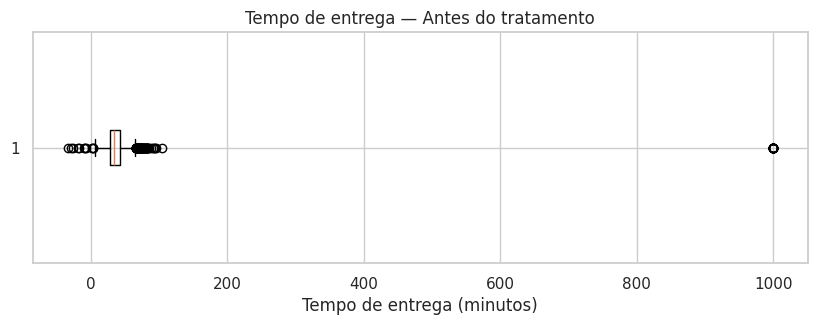

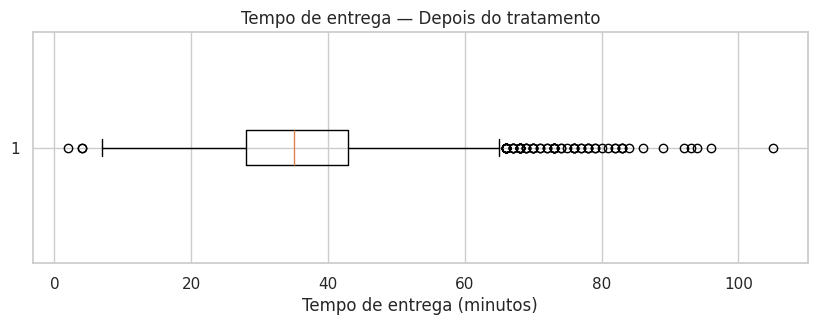

Tempos inválidos identificados: 33
Tempos ausentes após o tratamento: 33
Pedidos preservados: 8058

Estatísticas após o tratamento:


,tempo_entrega_min
count,8025.000000
mean,35.914268
std,11.103244
min,2.000000
25%,28.000000
50%,35.000000
75%,43.000000
max,105.000000


In [ ]:
# Sua solução aqui
import matplotlib.pyplot as plt

# 1. Boxplot antes do tratamento
plt.figure(figsize=(10, 3))
plt.boxplot(df['tempo_entrega_min'].dropna(), vert=False)
plt.title('Tempo de entrega — Antes do tratamento')
plt.xlabel('Tempo de entrega (minutos)')
plt.show()

# 2. Criar a flag para identificar tempos inválidos
df['tempo_invalido'] = (
    (df['tempo_entrega_min'] <= 0) |
    (df['tempo_entrega_min'] == 999)
)

# 3. Transformar os tempos inválidos em NaN
df.loc[df['tempo_invalido'], 'tempo_entrega_min'] = float('nan')

# 4. Boxplot depois do tratamento
plt.figure(figsize=(10, 3))
plt.boxplot(df['tempo_entrega_min'].dropna(), vert=False)
plt.title('Tempo de entrega — Depois do tratamento')
plt.xlabel('Tempo de entrega (minutos)')
plt.show()

# 5. Conferir o resultado
print("Tempos inválidos identificados:",
      df['tempo_invalido'].sum())

print("Tempos ausentes após o tratamento:",
      df['tempo_entrega_min'].isna().sum())

print("Pedidos preservados:", len(df))

print("\nEstatísticas após o tratamento:")
display(df['tempo_entrega_min'].describe())


*Sua resposta aqui*


A análise inicial do boxplot identificou valores extremos na coluna `tempo_entrega_min`, incluindo tempos negativos e registros iguais a 999 minutos.

Foram identificados **33 registros inválidos**, sendo 8 tempos menores ou iguais a zero e 25 registros com valor 999. Esses valores foram substituídos por `NaN`, e foi criada a coluna booleana `tempo_invalido` para identificá-los.

Após o tratamento, a média caiu de **38,85 para 35,91 minutos**, e o desvio-padrão diminuiu de **54,73 para 11,10 minutos**. A mediana permaneceu em **35 minutos**, demonstrando menor sensibilidade aos valores extremos.

O tempo máximo passou de 999 para 105 minutos. Os demais valores extremos foram preservados, pois podem representar entregas reais.

**Conclusão:** o tratamento corrigiu os 33 tempos inválidos, preservando os **8.058 pedidos**, dos quais 8.025 permaneceram com tempos válidos. A comparação dos boxplots antes e depois permite visualizar a distribuição sem a distorção causada pelos registros inválidos.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

Outliers pelo Z-score: 7
Outliers pelo IQR: 194

Limite inferior IQR: -2.73
Limite superior IQR: 9.27

Sinalizados pelos dois critérios: 7


,pedido_id,cidade,distancia_km,tempo_entrega_min,outlier_z,outlier_iqr
3242,503242,São Paulo,399.65,25.0,True,True
706,500706,São Paulo,391.89,23.0,True,True
3926,503926,São Paulo,369.22,56.0,True,True
1539,501539,Belo Horizonte,300.21,43.0,True,True
5826,505826,São Paulo,252.99,54.0,True,True
5749,505749,Rio de Janeiro,163.23,29.0,True,True
7133,507133,São Paulo,160.26,20.0,True,True
5200,505200,São Paulo,24.39,105.0,False,True
6687,506687,Belo Horizonte,18.58,89.0,False,True
8003,508003,Rio de Janeiro,18.30,83.0,False,True


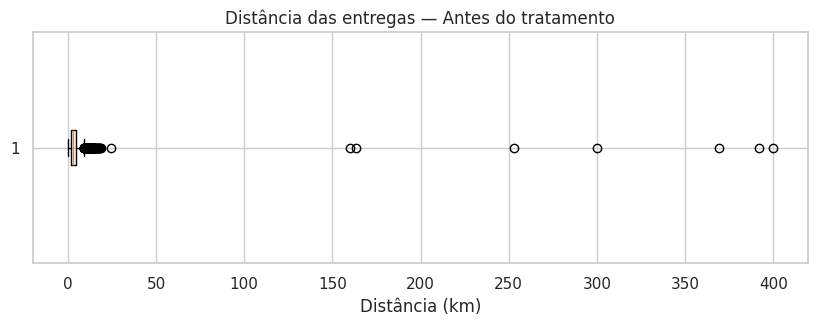

In [ ]:
# Sua solução aqui

# 1. Trabalhar apenas com distâncias informadas
distancias = df['distancia_km'].dropna()

# 2. Critério Z-score
media = distancias.mean()
desvio = distancias.std()

z_score = (df['distancia_km'] - media) / desvio
outlier_z = z_score.abs() > 3

# 3. Critério IQR
q1 = distancias.quantile(0.25)
q3 = distancias.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outlier_iqr = (
    (df['distancia_km'] < limite_inferior) |
    (df['distancia_km'] > limite_superior)
)

# 4. Comparar os critérios
print("Outliers pelo Z-score:", outlier_z.sum())
print("Outliers pelo IQR:", outlier_iqr.sum())

print("\nLimite inferior IQR:", round(limite_inferior, 2))
print("Limite superior IQR:", round(limite_superior, 2))

print("\nSinalizados pelos dois critérios:",
      (outlier_z & outlier_iqr).sum())

# 5. Examinar as 20 maiores distâncias
maiores = df.nlargest(20, 'distancia_km')[
    ['pedido_id', 'cidade', 'distancia_km', 'tempo_entrega_min']
].copy()

maiores['outlier_z'] = outlier_z.loc[maiores.index]
maiores['outlier_iqr'] = outlier_iqr.loc[maiores.index]

display(maiores)

# 6. Visualizar a distribuição original
plt.figure(figsize=(10, 3))
plt.boxplot(distancias, vert=False)
plt.title('Distância das entregas — Antes do tratamento')
plt.xlabel('Distância (km)')
plt.show()


Distâncias inválidas: 7
Distâncias ausentes após tratamento: 322
Pedidos preservados: 8058

Estatísticas após o tratamento:


,distancia_km
count,7736.000000
mean,3.537795
std,2.389663
min,0.080000
25%,1.770000
50%,3.025000
75%,4.760000
max,24.390000


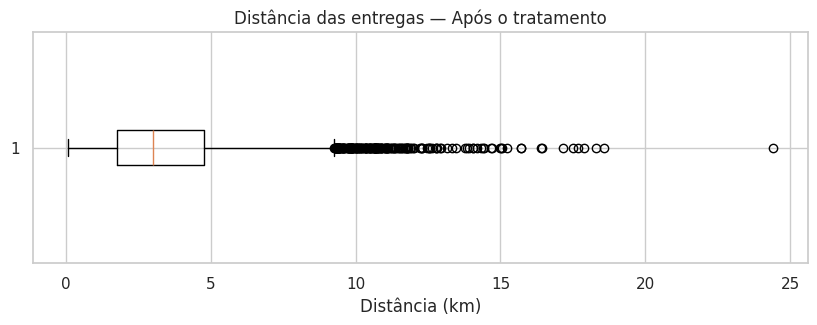

In [ ]:
# 1. Criar a flag de distâncias inválidas
df['distancia_invalida'] = df['distancia_km'] > 100

# 2. Substituir distâncias inválidas por NaN
df.loc[df['distancia_invalida'], 'distancia_km'] = float('nan')

# 3. Conferir o tratamento
print("Distâncias inválidas:",
      df['distancia_invalida'].sum())

print("Distâncias ausentes após tratamento:",
      df['distancia_km'].isna().sum())

print("Pedidos preservados:", len(df))

print("\nEstatísticas após o tratamento:")
display(df['distancia_km'].describe())

# 4. Boxplot após o tratamento
plt.figure(figsize=(10, 3))
plt.boxplot(df['distancia_km'].dropna(), vert=False)
plt.title('Distância das entregas — Após o tratamento')
plt.xlabel('Distância (km)')
plt.show()

*Sua resposta aqui*


Foram aplicados dois critérios estatísticos à coluna `distancia_km`: **Z-score > 3** e **1,5 × IQR**, para identificar possíveis valores extremos.

O Z-score sinalizou **7 pedidos**, enquanto o IQR identificou **194 pedidos**, considerando os limites de −2,73 km e 9,27 km. Os 7 registros identificados pelo Z-score também foram sinalizados pelo IQR.

A análise das maiores distâncias revelou uma separação expressiva entre **24,39 km**, maior distância considerada plausível, e **160,26 km**, menor distância do grupo suspeito. Os 7 registros mais extremos apresentaram distâncias entre 160,26 km e 399,65 km, incompatíveis com seus tempos de entrega, entre 20 e 56 minutos.

**Decisões de tratamento:**

- **Distâncias superiores a 100 km:** consideradas inválidas e substituídas por `NaN`, utilizando um limite operacional definido a partir dos dados.
- **Demais outliers:** preservados, pois distâncias longas não representam necessariamente erros.
- **Flag `distancia_invalida`:** criada para identificar os 7 registros considerados inválidos.

**Validação do tratamento:**

Após o tratamento, foram confirmadas **7 distâncias inválidas**, elevando o total de valores ausentes de 315 para **322**.

Permaneceram **7.736 distâncias válidas**, com média de 3,54 km, mediana de 3,03 km e distância máxima de 24,39 km.

**Conclusão:** a análise demonstrou que nem todo outlier estatístico representa um erro. O tratamento removeu apenas os valores incompatíveis com o contexto das entregas, preservando os extremos plausíveis e todos os **8.058 pedidos**, sem exclusão de registros.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [ ]:
# Sua solução aqui

# 1. IQR GLOBAL — considerando toda a base
q1 = df['valor_pedido'].quantile(0.25)
q3 = df['valor_pedido'].quantile(0.75)
iqr = q3 - q1

limite_inf_global = q1 - 1.5 * iqr
limite_sup_global = q3 + 1.5 * iqr

df['outlier_iqr_global'] = (
    (df['valor_pedido'] < limite_inf_global) |
    (df['valor_pedido'] > limite_sup_global)
)

# 2. IQR POR TIPO DE COZINHA
q1_cozinha = df.groupby('tipo_cozinha')['valor_pedido'].transform(
    lambda x: x.quantile(0.25)
)

q3_cozinha = df.groupby('tipo_cozinha')['valor_pedido'].transform(
    lambda x: x.quantile(0.75)
)

iqr_cozinha = q3_cozinha - q1_cozinha

df['outlier_iqr_cozinha'] = (
    (df['valor_pedido'] < q1_cozinha - 1.5 * iqr_cozinha) |
    (df['valor_pedido'] > q3_cozinha + 1.5 * iqr_cozinha)
)

# 3. Z-SCORE GLOBAL > 3
media = df['valor_pedido'].mean()
desvio = df['valor_pedido'].std()

z_score = (df['valor_pedido'] - media) / desvio

df['outlier_z_valor'] = z_score.abs() > 3

# 4. COMPARAÇÃO POR TIPO DE COZINHA
comparacao = df.groupby('tipo_cozinha').agg(
    total_pedidos=('pedido_id', 'count'),
    iqr_global=('outlier_iqr_global', 'sum'),
    iqr_cozinha=('outlier_iqr_cozinha', 'sum'),
    z_score=('outlier_z_valor', 'sum')
)

comparacao.loc['TOTAL'] = comparacao.sum()

print("Limite inferior IQR global:",
      round(limite_inf_global, 2))
print("Limite superior IQR global:",
      round(limite_sup_global, 2))

print("\nComparação dos critérios por tipo de cozinha:")
display(comparacao)

# 5. MAIORES VALORES DO PEDIDO
print("\nOs 15 pedidos de maior valor:")

display(
    df.nlargest(15, 'valor_pedido')[
        ['pedido_id', 'tipo_cozinha', 'valor_pedido',
         'outlier_iqr_global', 'outlier_iqr_cozinha',
         'outlier_z_valor']
    ]
)

Limite inferior IQR global: -14.63
Limite superior IQR global: 144.97

Comparação dos critérios por tipo de cozinha:


,total_pedidos,iqr_global,iqr_cozinha,z_score
tipo_cozinha,,,,
Brasileira,1561,6,38,5
Doces,814,3,18,2
Hambúrguer,1921,19,43,4
Japonesa,1116,246,24,12
Pizza,1786,70,60,4
Saudável,860,8,31,4
TOTAL,8058,352,214,31



Os 15 pedidos de maior valor:


,pedido_id,tipo_cozinha,valor_pedido,outlier_iqr_global,outlier_iqr_cozinha,outlier_z_valor
6904,506904,Pizza,2299.10,True,True,True
3553,503553,Japonesa,2207.79,True,True,True
4023,504023,Pizza,1441.97,True,True,True
1035,501035,Japonesa,1394.73,True,True,True
5238,505238,Japonesa,1074.23,True,True,True
6787,506787,Hambúrguer,1071.77,True,True,True
491,500491,Pizza,1035.26,True,True,True
4542,504542,Japonesa,765.04,True,True,True
1736,501736,Hambúrguer,700.91,True,True,True
4286,504286,Japonesa,697.91,True,True,True


*Sua resposta aqui*


Foram aplicados três critérios à coluna `valor_pedido`: **IQR global**, **IQR por tipo de cozinha** e **Z-score > 3**.

O IQR global identificou **352 pedidos (4,37%)**, utilizando o limite superior de R$ 144,97. O IQR calculado separadamente por cozinha sinalizou **214 pedidos (2,66%)**, enquanto o Z-score identificou **31 pedidos (0,38%)**.

A principal diferença ocorreu na cozinha **Japonesa**, que apresentou 246 outliers pelo IQR global, mas apenas 24 pelo IQR por cozinha. Isso demonstra que utilizar um único limite para toda a base pode classificar como atípicos valores que são mais comuns em determinadas categorias.

Os 15 pedidos mais caros, com valores entre R$ 505,64 e R$ 2.299,10, foram sinalizados pelos três métodos.

**Conclusão:** a quantidade de outliers varia conforme o critério e o grupo de comparação. O IQR por cozinha permite considerar as diferenças entre categorias, enquanto o Z-score global sinalizou menos registros. Nesta etapa, os valores foram apenas identificados, sem exclusão ou alteração, pois um pedido caro não representa necessariamente um erro.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

20 maiores razões:


,pedido_id,tipo_cozinha,valor_pedido,mediana_cozinha,razao_valor,salto_razao
6904,506904,Pizza,2299.10,74.31,30.94,10.49
3553,503553,Japonesa,2207.79,107.97,20.45,1.04
4023,504023,Pizza,1441.97,74.31,19.41,2.03
6787,506787,Hambúrguer,1071.77,61.67,17.38,3.45
491,500491,Pizza,1035.26,74.31,13.93,0.77
3246,503246,Doces,505.64,38.42,13.16,0.24
1035,501035,Japonesa,1394.73,107.97,12.92,0.07
1263,501263,Brasileira,614.31,47.82,12.85,1.48
1736,501736,Hambúrguer,700.91,61.67,11.37,1.22
4045,504045,Hambúrguer,625.71,61.67,10.15,0.20



Maiores saltos entre as 50 maiores razões:


,pedido_id,razao_valor,salto_razao
6904,506904,30.94,10.49
6787,506787,17.38,3.45
4023,504023,19.41,2.03
1263,501263,12.85,1.48
1736,501736,11.37,1.22
3553,503553,20.45,1.04
6157,506157,5.80,1.03
4501,504501,4.28,0.93
491,500491,13.93,0.77
5238,505238,9.95,0.72


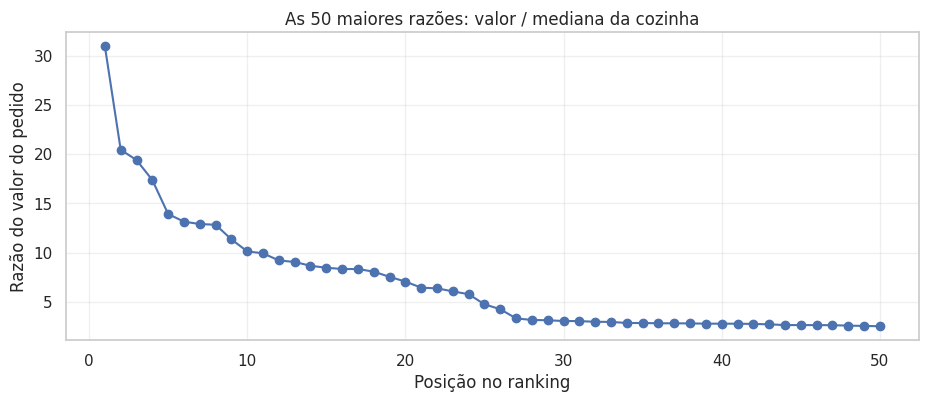


Detalhes dos 20 pedidos com maiores razões:


,pedido_id,cidade,data,tipo_cozinha,valor_pedido,distancia_km,taxa_entrega,tempo_entrega_min,razao_valor
6904,506904,Rio de Janeiro,2024-11-17,Pizza,2299.10,2.03,6.82,25.0,30.94
3553,503553,São Paulo,2024-06-24,Japonesa,2207.79,0.89,5.79,18.0,20.45
4023,504023,São Paulo,2024-07-14,Pizza,1441.97,0.76,0.00,27.0,19.41
6787,506787,Rio de Janeiro,2024-11-12,Hambúrguer,1071.77,2.60,7.33,24.0,17.38
491,500491,São Paulo,2024-01-24,Pizza,1035.26,2.13,6.91,34.0,13.93
3246,503246,São Paulo,2024-06-09,Doces,505.64,1.30,0.00,29.0,13.16
1035,501035,São Paulo,2024-02-23,Japonesa,1394.73,2.35,7.10,39.0,12.92
1263,501263,São Paulo,2024-03-04,Brasileira,614.31,4.75,9.27,51.0,12.85
1736,501736,Rio de Janeiro,2024-03-27,Hambúrguer,700.91,11.92,15.72,59.0,11.37
4045,504045,São Paulo,2024-07-15,Hambúrguer,625.71,1.04,5.93,24.0,10.15


In [ ]:
# Sua solução aqui

# 1. Calcular a mediana do valor por cozinha
df['mediana_cozinha'] = (
    df.groupby('tipo_cozinha')['valor_pedido']
      .transform('median')
)

# 2. Calcular a razão entre valor e mediana
df['razao_valor'] = (
    df['valor_pedido'] / df['mediana_cozinha']
)

# 3. Ordenar as maiores razões
ranking = df.sort_values(
    'razao_valor', ascending=False
).copy()

# 4. Calcular o salto entre razões consecutivas
ranking['salto_razao'] = (
    ranking['razao_valor'] -
    ranking['razao_valor'].shift(-1)
)

print("20 maiores razões:")
display(
    ranking[
        ['pedido_id', 'tipo_cozinha',
         'valor_pedido', 'mediana_cozinha',
         'razao_valor', 'salto_razao']
    ].head(20).round(2)
)

# 5. Mostrar os maiores saltos entre as 50 maiores razões
print("\nMaiores saltos entre as 50 maiores razões:")
display(
    ranking.head(50).nlargest(
        10, 'salto_razao'
    )[
        ['pedido_id', 'razao_valor', 'salto_razao']
    ].round(2)
)

# 6. Visualizar as 50 maiores razões
plt.figure(figsize=(11, 4))

plt.plot(
    range(1, 51),
    ranking['razao_valor'].head(50),
    marker='o'
)

plt.title('As 50 maiores razões: valor / mediana da cozinha')
plt.xlabel('Posição no ranking')
plt.ylabel('Razão do valor do pedido')
plt.grid(alpha=0.3)
plt.show()

# 7. Examinar os 20 pedidos com maiores razões
print("\nDetalhes dos 20 pedidos com maiores razões:")

display(
    ranking[
        ['pedido_id', 'cidade', 'data',
         'tipo_cozinha', 'valor_pedido',
         'distancia_km', 'taxa_entrega',
         'tempo_entrega_min', 'razao_valor']
    ].head(20).round(2)
)

In [ ]:
# 1. Definir o limite com base no salto observado
limite_pedido_grande = 15

# 2. Criar a flag booleana
df['pedido_grande'] = (
    df['razao_valor'] > limite_pedido_grande
)

# 3. Validar o resultado
print("Pedidos grandes identificados:",
      df['pedido_grande'].sum())

print("Pedidos preservados:", len(df))

print("\nDistribuição da flag:")
display(df['pedido_grande'].value_counts())

# 4. Examinar os pedidos classificados como grandes
display(
    df.loc[
        df['pedido_grande'],
        ['pedido_id', 'cidade', 'data',
         'tipo_cozinha', 'valor_pedido',
         'mediana_cozinha', 'razao_valor',
         'distancia_km', 'taxa_entrega',
         'tempo_entrega_min']
    ].sort_values(
        'razao_valor', ascending=False
    ).round(2)
)

Pedidos grandes identificados: 4
Pedidos preservados: 8058

Distribuição da flag:


,count
pedido_grande,
False,8054
True,4


,pedido_id,cidade,data,tipo_cozinha,valor_pedido,mediana_cozinha,razao_valor,distancia_km,taxa_entrega,tempo_entrega_min
6904,506904,Rio de Janeiro,2024-11-17,Pizza,2299.10,74.31,30.94,2.03,6.82,25.0
3553,503553,São Paulo,2024-06-24,Japonesa,2207.79,107.97,20.45,0.89,5.79,18.0
4023,504023,São Paulo,2024-07-14,Pizza,1441.97,74.31,19.41,0.76,0.00,27.0
6787,506787,Rio de Janeiro,2024-11-12,Hambúrguer,1071.77,61.67,17.38,2.60,7.33,24.0


*Sua resposta aqui*


Foi calculada, para cada pedido, a razão entre `valor_pedido` e a mediana do valor correspondente ao seu `tipo_cozinha`, permitindo identificar pedidos excepcionalmente caros em relação à própria categoria.

A análise das maiores razões identificou um salto de **10,49**, entre 30,94 e 20,45, e outro de **3,45**, entre 17,38 e 13,93. O segundo salto foi utilizado para estabelecer um limite operacional de **razão superior a 15**, identificando um grupo de quatro pedidos excepcionalmente grandes.

Esses pedidos apresentaram valores entre **R$ 1.071,77 e R$ 2.299,10**, distribuídos entre São Paulo e Rio de Janeiro, nas cozinhas Pizza, Japonesa e Hambúrguer.

A investigação das datas, distâncias, taxas e tempos de entrega não revelou inconsistências evidentes. As distâncias variaram de 0,76 a 2,60 km, e os tempos de entrega, de 18 a 27 minutos. Embora possam representar compras grandes ou corporativas, não há informações suficientes para confirmar essa hipótese ou caracterizar erros de digitação.

**Decisão de tratamento:** os valores originais foram preservados, e foi criada a flag booleana `pedido_grande`, identificando os pedidos com razão superior a 15.

**Validação:** foram identificados **4 pedidos grandes** e 8.054 pedidos não classificados nessa categoria, mantendo todos os **8.058 registros**.

**Conclusão:** valores muito elevados não devem ser automaticamente considerados erros. A análise contextual permitiu identificar e sinalizar pedidos excepcionalmente grandes sem alterar seus valores, preservando a integridade da base para análises posteriores.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [ ]:
# Sua solução aqui

import pandas as pd

# 1. Criar uma base temporária sem os pedidos grandes
df_sem_grandes = df.loc[~df['pedido_grande']].copy()

# 2. Comparação geral
comparacao_geral = pd.DataFrame({
    'Com grandes': [
        df['valor_pedido'].mean(),
        df['valor_pedido'].median()
    ],
    'Sem grandes': [
        df_sem_grandes['valor_pedido'].mean(),
        df_sem_grandes['valor_pedido'].median()
    ]
}, index=['Média', 'Mediana'])

comparacao_geral['Diferença (R$)'] = (
    comparacao_geral['Com grandes'] -
    comparacao_geral['Sem grandes']
)

print("Comparação geral do ticket:")
display(comparacao_geral.round(2))

# 3. Comparação por tipo de cozinha
com_grandes = df.groupby('tipo_cozinha')['valor_pedido'].agg(
    media_com='mean',
    mediana_com='median'
)

sem_grandes = df_sem_grandes.groupby('tipo_cozinha')['valor_pedido'].agg(
    media_sem='mean',
    mediana_sem='median'
)

comparacao_cozinha = com_grandes.join(sem_grandes)

# 4. Calcular o impacto da retirada dos pedidos grandes
comparacao_cozinha['dif_media'] = (
    comparacao_cozinha['media_com'] -
    comparacao_cozinha['media_sem']
)

comparacao_cozinha['dif_mediana'] = (
    comparacao_cozinha['mediana_com'] -
    comparacao_cozinha['mediana_sem']
)

print("\nComparação por tipo de cozinha:")
display(comparacao_cozinha.round(2))

# 5. Verificar quantos pedidos foram considerados
print("\nPedidos com grandes:", len(df))
print("Pedidos sem grandes:", len(df_sem_grandes))
print("Pedidos grandes identificados:", df['pedido_grande'].sum())

Comparação geral do ticket:


,Com grandes,Sem grandes,Diferença (R$)
Média,71.55,70.72,0.84
Mediana,61.61,61.59,0.02



Comparação por tipo de cozinha:


,media_com,mediana_com,media_sem,mediana_sem,dif_media,dif_mediana
tipo_cozinha,,,,,,
Brasileira,51.17,47.82,51.17,47.82,0.00,0.00
Doces,41.79,38.42,41.79,38.42,0.00,0.00
Hambúrguer,67.65,61.67,67.13,61.66,0.52,0.02
Japonesa,120.37,107.97,118.49,107.89,1.87,0.08
Pizza,82.79,74.31,80.78,74.30,2.00,0.01
Saudável,58.77,53.74,58.77,53.74,0.00,0.00



Pedidos com grandes: 8058
Pedidos sem grandes: 8054
Pedidos grandes identificados: 4


*Sua resposta aqui*

Foram comparadas a média e a mediana de `valor_pedido` na base completa, com **8.058 pedidos**, e em uma base temporária sem os **4 pedidos grandes**, contendo 8.054 registros.

Na análise geral, a média passou de **R$ 71,55 para R$ 70,72**, uma diferença de R$ 0,84. Já a mediana variou de **R$ 61,61 para R$ 61,59**, uma diferença de apenas R$ 0,02.

Por tipo de cozinha, os maiores impactos na média ocorreram em **Pizza (R$ 2,00)**, **Japonesa (R$ 1,87)** e **Hambúrguer (R$ 0,52)**. Nas demais categorias, não houve alteração. As medianas apresentaram variações mínimas em todas as cozinhas.

**Decisão:** a **mediana será utilizada como principal indicador de ticket típico** nas próximas análises, por ser mais resistente à influência de valores extremos. A média continuará sendo apresentada quando relevante para análises financeiras e comparações.

**Conclusão:** os pedidos grandes influenciaram mais a média do que a mediana, embora o impacto geral tenha sido pequeno. A análise confirmou a maior estabilidade da mediana e justificou sua escolha para representar o valor típico dos pedidos, mantendo os **8.058 registros** na base original.

In [ ]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [ ]:
# Sua solução aqui

# 1. Selecionar as variáveis numéricas
colunas = [
    'valor_pedido',
    'taxa_entrega',
    'distancia_km',
    'tempo_entrega_min',
    'avaliacao'
]

# 2. Calcular as estatísticas do describe()
resumo = df[colunas].describe().T

# 3. Calcular o IQR
resumo['IQR'] = resumo['75%'] - resumo['25%']

# 4. Calcular o coeficiente de variação (%)
resumo['CV (%)'] = (
    resumo['std'] / resumo['mean'] * 100
)

# 5. Calcular a assimetria
resumo['Assimetria'] = df[colunas].skew()

# 6. Calcular a moda
resumo['Moda'] = df[colunas].apply(
    lambda x: x.mode().iloc[0]
    if not x.mode().empty else np.nan
)

# 7. Exibir a tabela
print("Resumo estatístico das variáveis numéricas:")
display(resumo.round(2))


Resumo estatístico das variáveis numéricas:


,count,mean,std,min,25%,50%,75%,max,IQR,CV (%),Assimetria,Moda
valor_pedido,8058.0,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,48.52
taxa_entrega,8058.0,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0.00
distancia_km,7736.0,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.70
tempo_entrega_min,8025.0,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34.00
avaliacao,6716.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5.00




Foi elaborada uma tabela descritiva para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao`, incluindo as métricas do `describe()`, amplitude interquartil (IQR), coeficiente de variação (CV), assimetria e moda.

O **valor do pedido** apresentou média de R$ 71,55, mediana de R$ 61,61, CV de 84,22% e assimetria de 17,52, evidenciando elevada dispersão e forte influência de valores extremos.

A **taxa de entrega** apresentou média de R$ 7,27 e leve assimetria negativa (−0,51). A **distância** registrou mediana de 3,02 km e assimetria positiva (1,37), indicando maior concentração em distâncias menores.

O **tempo de entrega** apresentou média de 35,91 minutos, mediana de 35 minutos e assimetria positiva moderada (0,52). Já a **avaliação** registrou média de 4,35, moda de 5 e assimetria negativa (−0,70), demonstrando concentração nas avaliações mais altas.

As diferenças nas contagens refletem os valores ausentes preservados nas etapas de limpeza.

**Conclusão:** a análise revelou diferentes níveis de dispersão e assimetria entre as variáveis. A elevada assimetria de `valor_pedido` reforça a escolha da **mediana como indicador do ticket típico**, por sua maior resistência aos valores extremos.

### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

*Sua resposta aqui*


**(a) Qual variável é mais assimétrica e o que isso significa para a escolha entre média e mediana?**

A variável `valor_pedido` apresentou a maior assimetria (**17,52**), indicando uma distribuição fortemente assimétrica à direita, influenciada por pedidos de valores muito elevados. Por isso, a **mediana (R$ 61,61)** representa melhor o ticket típico do que a média (R$ 71,55), que é mais sensível aos valores extremos.

**(b) Qual variável apresenta maior variabilidade relativa?**

A variável `valor_pedido` também apresentou o maior coeficiente de variação (**84,22%**), indicando elevada dispersão dos valores em relação à média. Em seguida, aparecem `distancia_km` (67,55%) e `taxa_entrega` (45,20%).

**(c) O que a moda da `taxa_entrega` revela?**

A moda da `taxa_entrega` foi **R$ 0,00**, indicando que a taxa de entrega gratuita é o valor individual mais frequente na base. Isso sugere a presença de pedidos com isenção de taxa, embora não signifique que a maioria das entregas seja gratuita.

**(d) A avaliação média é alta ou baixa?**

A avaliação média foi de **4,35 em uma escala de 1 a 5**, considerada alta. A moda de **5 estrelas** reforça a concentração de avaliações positivas. Entretanto, essa interpretação considera apenas os **6.716 pedidos avaliados**, pois 1.342 registros não possuem avaliação.

**Conclusão:** a análise evidencia a importância de utilizar medidas estatísticas adequadas às características dos dados. A mediana é mais apropriada para representar o ticket típico, enquanto as avaliações disponíveis indicam uma percepção predominantemente positiva dos clientes.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [ ]:
# Sua solução aqui

# 1. Selecionar as variáveis categóricas
categoricas = [
    'cidade',
    'tipo_cozinha',
    'forma_pagamento',
    'plataforma'
]

# 2. Calcular moda e distribuição percentual
for coluna in categoricas:

    print(f"\n{'=' * 50}")
    print(f"VARIÁVEL: {coluna.upper()}")

    # Identificar a moda
    moda = df[coluna].mode().iloc[0]
    print(f"Moda: {moda}")

    # Calcular frequência absoluta
    frequencia = df[coluna].value_counts(dropna=False)

    # Calcular frequência percentual
    percentual = (
        df[coluna].value_counts(
            normalize=True, dropna=False
        ) * 100
    )

    # Organizar a tabela
    tabela = pd.DataFrame({
        'Quantidade': frequencia,
        'Percentual (%)': percentual
    })

    # Adicionar linha de total
    tabela.loc['TOTAL'] = [
        tabela['Quantidade'].sum(),
        tabela['Percentual (%)'].sum()
    ]

    display(tabela.round(2))



VARIÁVEL: CIDADE
Moda: São Paulo


,Quantidade,Percentual (%)
cidade,,
São Paulo,4055.0,50.32
Rio de Janeiro,2371.0,29.42
Belo Horizonte,1632.0,20.25
TOTAL,8058.0,100.00



VARIÁVEL: TIPO_COZINHA
Moda: Hambúrguer


,Quantidade,Percentual (%)
tipo_cozinha,,
Hambúrguer,1921.0,23.84
Pizza,1786.0,22.16
Brasileira,1561.0,19.37
Japonesa,1116.0,13.85
Saudável,860.0,10.67
Doces,814.0,10.10
TOTAL,8058.0,100.00



VARIÁVEL: FORMA_PAGAMENTO
Moda: Cartão de crédito


,Quantidade,Percentual (%)
forma_pagamento,,
Cartão de crédito,3642.0,45.20
Pix,2633.0,32.68
Vale-refeição,1222.0,15.17
Dinheiro,561.0,6.96
TOTAL,8058.0,100.00



VARIÁVEL: PLATAFORMA
Moda: Android


,Quantidade,Percentual (%)
plataforma,,
Android,4449.0,55.21
iOS,2574.0,31.94
Web,882.0,10.95
Não informada,153.0,1.90
TOTAL,8058.0,100.00


*Sua resposta aqui*


Foram calculadas a moda, a frequência absoluta e a distribuição percentual das variáveis `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`.

**Cidade:** São Paulo apresentou a maior concentração de pedidos (**50,32%**), seguida por Rio de Janeiro (29,42%) e Belo Horizonte (20,25%).

**Tipo de cozinha:** Hambúrguer foi a categoria mais frequente (**23,84%**), seguida por Pizza (22,16%) e Brasileira (19,37%).

**Forma de pagamento:** Cartão de crédito foi o método mais utilizado (**45,20%**), seguido por Pix (32,68%). Juntos, representam aproximadamente 77,88% dos pedidos.

**Plataforma:** Android concentrou a maior participação (**55,21%**), seguido por iOS (31,94%) e Web (10,95%). A categoria "Não informada" representou 1,90%.

**Conclusão:** os pedidos estão concentrados principalmente em São Paulo, com destaque para Hambúrguer, pagamento por cartão de crédito e utilização da plataforma Android. A análise permite identificar as categorias predominantes e compreender a composição da base de dados.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [ ]:
# Sua solução aqui

# 1. Selecionar os tempos válidos
tempos = df['tempo_entrega_min'].dropna()

# 2. Calcular os percentis
percentis = tempos.quantile([0.50, 0.75, 0.90, 0.95])

print("Percentis do tempo de entrega:")
print(percentis)

# 3. Calcular pedidos acima de 35 minutos
acima_35 = (tempos > 35).sum()
perc_35 = (tempos > 35).mean() * 100

# 4. Calcular pedidos acima de 45 minutos
acima_45 = (tempos > 45).sum()
perc_45 = (tempos > 45).mean() * 100

# 5. Exibir os resultados
print("\nPedidos com tempo válido:", len(tempos))

print(f"\nAcima de 35 minutos: {acima_35} pedidos ({perc_35:.2f}%)")

print(f"Acima de 45 minutos: {acima_45} pedidos ({perc_45:.2f}%)")

# 6. Avaliar a promessa de entrega
print("\nPromessa: entrega em até 45 minutos")

print(f"Pedidos que cumpriram: {(tempos <= 45).sum()}")

print(f"Pedidos que quebraram a promessa: {acima_45}")

print(f"Percentual de descumprimento: {perc_45:.2f}%")

print(f"Pedidos sem tempo válido: {df['tempo_entrega_min'].isna().sum()}")


Percentis do tempo de entrega:
0.50    35.0
0.75    43.0
0.90    50.0
0.95    55.0
Name: tempo_entrega_min, dtype: float64

Pedidos com tempo válido: 8025

Acima de 35 minutos: 3908 pedidos (48.70%)
Acima de 45 minutos: 1476 pedidos (18.39%)

Promessa: entrega em até 45 minutos
Pedidos que cumpriram: 6549
Pedidos que quebraram a promessa: 1476
Percentual de descumprimento: 18.39%
Pedidos sem tempo válido: 33


*Sua resposta aqui*



Foram calculados os percentis 50, 75, 90 e 95 do tempo de entrega, considerando os **8.025 pedidos com tempos válidos**.

Os resultados foram: **P50 = 35 minutos**, **P75 = 43 minutos**, **P90 = 50 minutos** e **P95 = 55 minutos**. Isso indica que aproximadamente 90% das entregas foram realizadas em até 50 minutos e 95% em até 55 minutos.

Em relação aos limites operacionais, **3.908 pedidos (48,70%)** ultrapassaram 35 minutos, enquanto **1.476 pedidos (18,39%)** ultrapassaram 45 minutos.

Considerando uma promessa de entrega em até 45 minutos, **6.549 pedidos (81,61%)** cumpriram o prazo e **1.476 pedidos (18,39%)** descumpriram a promessa.

Os 33 pedidos com tempos inválidos foram desconsiderados dos cálculos, pois não permitem verificar o cumprimento do prazo.

**Conclusão:** embora a maioria das entregas tenha ocorrido dentro de 45 minutos, aproximadamente **1 em cada 5 pedidos com tempo válido** ultrapassou esse limite. Esse resultado evidencia uma oportunidade de melhoria na eficiência operacional e no cumprimento dos prazos prometidos aos clientes.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [ ]:
# Sua solução aqui

# Selecionar os pedidos de 2024
df_2024 = df[df['data_hora'].dt.year == 2024].copy()

# Considerar apenas tempos válidos para o indicador de atraso
tempos = df_2024['tempo_entrega_min'].dropna()

# Criar a Series de KPIs
kpis_2024 = pd.Series({
    'Nº de pedidos': len(df_2024),

    'Faturamento em itens (R$)': df_2024['valor_pedido'].sum(),

    'Receita de taxa de entrega (R$)': df_2024['taxa_entrega'].sum(),

    'Ticket médio (R$)': df_2024['valor_pedido'].mean(),

    'Ticket mediano (R$)': df_2024['valor_pedido'].median(),

    'Pedidos com cupom (%)': df_2024['cupom'].mean() * 100,

    'Clientes novos (%)': df_2024['cliente_novo'].mean() * 100,

    'Pedidos com frete grátis (%)':
        (df_2024['taxa_entrega'] == 0).mean() * 100,

    'Tempo médio de entrega (min)':
        df_2024['tempo_entrega_min'].mean(),

    'Entregas acima de 45 min (%)':
        (tempos > 45).mean() * 100,

    'Avaliação média': df_2024['avaliacao'].mean(),

    'Pedidos avaliados (%)':
        df_2024['avaliacao'].notna().mean() * 100
})

# Exibir os KPIs
display(kpis_2024.round(2))


,0
Nº de pedidos,8058.00
Faturamento em itens (R$),576584.75
Receita de taxa de entrega (R$),58571.40
Ticket médio (R$),71.55
Ticket mediano (R$),61.61
Pedidos com cupom (%),21.21
Clientes novos (%),17.37
Pedidos com frete grátis (%),11.17
Tempo médio de entrega (min),35.91
Entregas acima de 45 min (%),18.39




Foram calculados 12 indicadores de desempenho, consolidados em uma única `Series`, considerando a granularidade anual dos **8.058 pedidos de 2024**.

**Indicadores financeiros:** o faturamento em itens totalizou **R\$ 576.584,75**, enquanto a receita de taxas de entrega alcançou **R\$ 58.571,40**. O ticket médio foi de **R\$ 71,55** e o mediano de **R\$ 61,61**, evidenciando a influência de pedidos de maior valor sobre a média.

**Perfil dos pedidos:** 21,21% utilizaram cupom, 17,37% foram realizados por clientes novos e 11,17% tiveram frete grátis.

**Desempenho operacional:** o tempo médio de entrega foi de **35,91 minutos**, com **18,39% das entregas válidas** ultrapassando 45 minutos, indicando uma oportunidade de melhoria no cumprimento dos prazos.

**Satisfação dos clientes:** a avaliação média foi de **4,35 estrelas**, considerada alta. Entretanto, apenas **83,35% dos pedidos** receberam avaliação.

**Conclusão:** os KPIs oferecem uma visão consolidada do desempenho financeiro, comercial e operacional em 2024. Os principais pontos de atenção são o cumprimento dos prazos de entrega e a ampliação da participação dos clientes nas avaliações.

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [ ]:
# Sua solução aqui

# 1. Agrupar por cidade utilizando named aggregation
tabela_cidades = df.groupby('cidade').agg(
    pedidos=('pedido_id', 'count'),
    faturamento=('valor_pedido', 'sum'),
    ticket_mediano=('valor_pedido', 'median'),
    tempo_medio_entrega=('tempo_entrega_min', 'mean'),
    avaliacao_media=('avaliacao', 'mean'),
    perc_cupom=('cupom', lambda x: x.mean() * 100)
)

# 2. Calcular a participação percentual de cada cidade
tabela_cidades['participacao_pct'] = (
    tabela_cidades['pedidos'] / len(df) * 100
)

# 3. Calcular o percentual de dias com chuva por cidade
# Cada combinação cidade + data representa um dia
chuva_diaria = (
    df.groupby(['cidade', 'data'])['chuva']
    .max()
    .groupby('cidade')
    .mean() * 100
)

# 4. Adicionar o percentual de dias com chuva
tabela_cidades['dias_com_chuva_pct'] = chuva_diaria

# 5. Organizar a ordem das colunas
tabela_cidades = tabela_cidades[
    [
        'pedidos',
        'participacao_pct',
        'faturamento',
        'ticket_mediano',
        'tempo_medio_entrega',
        'avaliacao_media',
        'perc_cupom',
        'dias_com_chuva_pct'
    ]
]

# 6. Ordenar por quantidade de pedidos
tabela_cidades = tabela_cidades.sort_values(
    'pedidos', ascending=False
)

# 7. Exibir a tabela
display(tabela_cidades.round(2))


,pedidos,participacao_pct,faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,perc_cupom,dias_com_chuva_pct
cidade,,,,,,,,
São Paulo,4055,50.32,289275.55,61.54,35.86,4.35,21.60,25.21
Rio de Janeiro,2371,29.42,172029.24,61.43,35.71,4.36,20.75,24.45
Belo Horizonte,1632,20.25,115279.96,62.04,36.34,4.34,20.89,26.39


*Sua resposta aqui*


Utilizando `groupby()` com *named aggregation*, foram calculados indicadores de desempenho por cidade, ordenados pela quantidade de pedidos.

**São Paulo:** liderou em volume, com **4.055 pedidos (50,32%)**, e faturamento de **R\$ 289.275,55**. Apresentou ticket mediano de R\$ 61,54, tempo médio de entrega de 35,86 minutos e o maior percentual de pedidos com cupom (21,60%).

**Rio de Janeiro:** registrou **2.371 pedidos (29,42%)** e faturamento de **R\$ 172.029,24**. Apresentou o menor tempo médio de entrega (35,71 minutos) e a maior avaliação média (4,36).

**Belo Horizonte:** contabilizou **1.632 pedidos (20,25%)** e faturamento de **R\$ 115.279,96**. Destacou-se pelo maior ticket mediano (R\$ 62,04) e pelo maior percentual de dias com chuva (26,39%), mas também pelo maior tempo médio de entrega (36,34 minutos).

**Conclusão:** São Paulo concentra aproximadamente metade dos pedidos e do faturamento. Entretanto, os indicadores de ticket, tempo de entrega e avaliação são semelhantes entre as cidades, sugerindo um desempenho operacional relativamente equilibrado. As diferenças observadas são descritivas e não demonstram, isoladamente, diferenças estatisticamente significativas.

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [ ]:
# Sua solução aqui
import pandas as pd

# 1. Agrupar por tipo de cozinha
tabela_cozinha = df.groupby('tipo_cozinha').agg(
    pedidos=('pedido_id', 'count'),
    ticket_medio=('valor_pedido', 'mean'),
    ticket_mediano=('valor_pedido', 'median'),
    faturamento=('valor_pedido', 'sum')
)

# 2. Calcular a participação no faturamento total
tabela_cozinha['participacao_faturamento_pct'] = (
    tabela_cozinha['faturamento'] /
    df['valor_pedido'].sum() * 100
)

# 3. Ordenar por quantidade de pedidos
tabela_cozinha = tabela_cozinha.sort_values(
    'pedidos', ascending=False
)

# 4. Exibir a tabela
display(tabela_cozinha.round(2))

# 5. Identificar maior e menor ticket
print("\nMAIOR E MENOR TICKET")

print("Maior ticket médio:",
      tabela_cozinha['ticket_medio'].idxmax())

print("Menor ticket médio:",
      tabela_cozinha['ticket_medio'].idxmin())

print("Maior ticket mediano:",
      tabela_cozinha['ticket_mediano'].idxmax())

print("Menor ticket mediano:",
      tabela_cozinha['ticket_mediano'].idxmin())

# 6. Comparar os rankings
ranking_volume = tabela_cozinha.index.tolist()

ranking_faturamento = (
    tabela_cozinha.sort_values(
        'faturamento', ascending=False
    ).index.tolist()
)

print("\nRANKING POR VOLUME:")
print(" > ".join(ranking_volume))

print("\nRANKING POR FATURAMENTO:")
print(" > ".join(ranking_faturamento))

print("\nA ordem é a mesma?",
      ranking_volume == ranking_faturamento)


,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento_pct
tipo_cozinha,,,,,
Hambúrguer,1921,67.65,61.67,129963.40,22.54
Pizza,1786,82.79,74.31,147857.26,25.64
Brasileira,1561,51.17,47.82,79871.60,13.85
Japonesa,1116,120.37,107.97,134328.26,23.30
Saudável,860,58.77,53.74,50544.31,8.77
Doces,814,41.79,38.42,34019.92,5.90



MAIOR E MENOR TICKET
Maior ticket médio: Japonesa
Menor ticket médio: Doces
Maior ticket mediano: Japonesa
Menor ticket mediano: Doces

RANKING POR VOLUME:
Hambúrguer > Pizza > Brasileira > Japonesa > Saudável > Doces

RANKING POR FATURAMENTO:
Pizza > Japonesa > Hambúrguer > Brasileira > Saudável > Doces

A ordem é a mesma? False


*Sua resposta aqui*

Utilizando `groupby()` com *named aggregation*, foram calculados os indicadores de volume, ticket médio, ticket mediano, faturamento e participação no faturamento por tipo de cozinha.

**Maior e menor ticket:** a cozinha **Japonesa** apresentou o maior ticket médio (**R\$ 120,37**) e mediano (**R\$ 107,97**). Já **Doces** registrou os menores valores, com ticket médio de **R\$ 41,79** e mediano de **R\$ 38,42**.

**Participação no faturamento:** Pizza liderou com **R\$ 147.857,26 (25,64%)**, seguida por Japonesa (**23,30%**) e Hambúrguer (**22,54%**). Juntas, essas três categorias representaram **71,48% do faturamento total**.

**Comparação dos rankings:**

- **Por volume:** Hambúrguer > Pizza > Brasileira > Japonesa > Saudável > Doces.
- **Por faturamento:** Pizza > Japonesa > Hambúrguer > Brasileira > Saudável > Doces.

**Conclusão:** a ordem por volume não é igual à ordem por faturamento. Hambúrguer liderou em quantidade de pedidos (1.921), mas Pizza apresentou o maior faturamento. A cozinha Japonesa, mesmo ocupando a quarta posição em volume, alcançou a segunda posição em faturamento devido ao seu ticket mais elevado. Isso demonstra que o faturamento depende tanto da quantidade de pedidos quanto do valor de cada pedido.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [ ]:
# Sua solução aqui
# parte (a)
# Agrupar os indicadores por plataforma
tabela_plataforma = df.groupby('plataforma').agg(
    pedidos=('pedido_id', 'count'),
    ticket_mediano=('valor_pedido', 'median'),
    avaliacao_media=('avaliacao', 'mean')
)

# Ordenar por quantidade de pedidos
tabela_plataforma = tabela_plataforma.sort_values(
    'pedidos', ascending=False
)

display(tabela_plataforma.round(2))


,pedidos,ticket_mediano,avaliacao_media
plataforma,,,
Android,4449,61.67,4.35
iOS,2574,60.76,4.35
Web,882,62.96,4.33
Não informada,153,62.44,4.39


In [ ]:
# Parte (b)
# Tabela cruzada com percentual por linha
tabela_pagamento = pd.crosstab(
    index=df['cidade'],
    columns=df['forma_pagamento'],
    normalize='index'
) * 100

# Exibir os resultados
display(tabela_pagamento.round(2))

# Conferir se cada linha totaliza 100%
print("\nSoma dos percentuais por cidade:")
print(tabela_pagamento.sum(axis=1).round(2))

forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26,6.86,32.60,14.28
Rio de Janeiro,45.47,6.87,33.11,14.55
São Paulo,44.61,7.05,32.45,15.88



Soma dos percentuais por cidade:
cidade
Belo Horizonte    100.0
Rio de Janeiro    100.0
São Paulo         100.0
dtype: float64


*Sua resposta aqui*


**(a) Ticket mediano e avaliação média por plataforma**

A plataforma **Web** apresentou o maior ticket mediano (**R\$ 62,96**), enquanto o **iOS** registrou o menor (**R\$ 60,76**).

As avaliações médias foram semelhantes entre as plataformas, variando de **4,33 (Web)** a **4,39 (Não informada)**. Android e iOS apresentaram a mesma média de 4,35.

**(b) Distribuição das formas de pagamento por cidade**

A tabela cruzada, calculada com percentuais por linha, revelou que as três cidades apresentam padrões de pagamento semelhantes.

O **cartão de crédito** foi o método predominante em Belo Horizonte (46,26%), Rio de Janeiro (45,47%) e São Paulo (44,61%).

O **Pix** ocupou a segunda posição, com percentuais entre 32,45% e 33,11%. O vale-refeição apresentou maior participação em São Paulo (15,88%), enquanto o dinheiro foi o método menos utilizado nas três cidades.

**Conclusão:** as diferenças de ticket e avaliação entre plataformas são pequenas. Da mesma forma, as cidades apresentam distribuições percentuais de pagamento bastante próximas, sem diferenças descritivas expressivas. Para verificar se existe associação estatisticamente significativa entre cidade e forma de pagamento, será necessário aplicar o teste qui-quadrado de independência.

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

RESUMO DIÁRIO


,pedido_id
count,366.00
mean,22.02
std,6.01
min,1.00
25%,18.00
50%,21.50
75%,26.00
max,41.00



RESUMO SEMANAL


,pedido_id
count,53.00
mean,152.04
std,24.75
min,49.00
25%,136.00
50%,152.00
75%,161.00
max,202.00



RESUMO MENSAL


,pedido_id
count,12.00
mean,671.50
std,84.36
min,559.00
25%,627.00
50%,661.00
75%,683.00
max,840.00


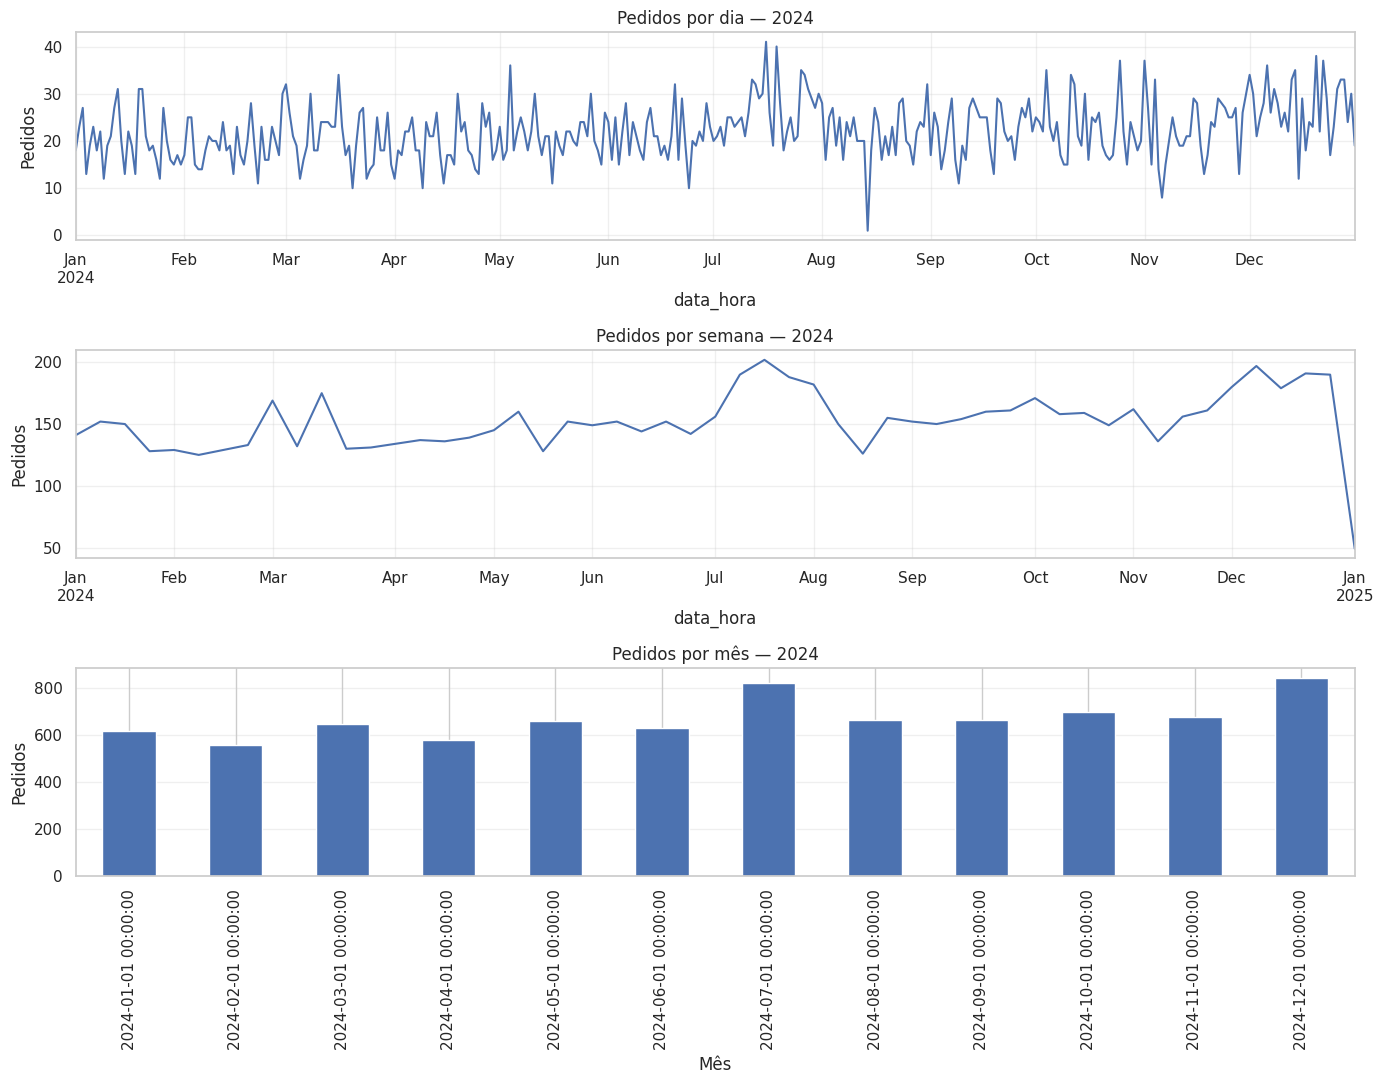


ANÁLISE DE DIAS ANÔMALOS
Q1: 18.00
Q3: 26.00
IQR: 8.00
Limite inferior: 6.00
Limite superior: 38.00

Dias identificados como anômalos:


,pedidos
data_hora,
2024-07-16,41
2024-07-19,40
2024-08-14,1



5 dias com maior volume:


,pedidos
data_hora,
2024-07-16,41
2024-07-19,40
2024-12-20,38
2024-10-25,37
2024-11-01,37



5 dias com menor volume:


,pedidos
data_hora,
2024-08-14,1
2024-11-06,8
2024-03-20,10
2024-04-09,10
2024-06-24,10



SEMANAS INCOMPLETAS:


,pedidos,dias_no_periodo,media_pedidos_por_dia
2025-01-05,49,2,24.5



TOTAL DE SEMANAS: 53
TOTAL DE PEDIDOS: 8058

Validação concluída: as três séries totalizam 8058 pedidos.


In [ ]:
# Sua solução aqui

# ============================================================
# 1. SÉRIES TEMPORAIS: DIA, SEMANA E MÊS
# ============================================================

df_tempo = df.set_index('data_hora').sort_index()

pedidos_dia = df_tempo.resample('D')['pedido_id'].count()
pedidos_semana = df_tempo.resample('W-SUN')['pedido_id'].count()
pedidos_mes = df_tempo.resample('MS')['pedido_id'].count()

print("RESUMO DIÁRIO")
display(pedidos_dia.describe().round(2))

print("\nRESUMO SEMANAL")
display(pedidos_semana.describe().round(2))

print("\nRESUMO MENSAL")
display(pedidos_mes.describe().round(2))


# ============================================================
# 2. GRÁFICOS DAS TRÊS GRANULARIDADES
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 11))

pedidos_dia.plot(
    ax=axes[0],
    title='Pedidos por dia — 2024'
)
axes[0].set_ylabel('Pedidos')
axes[0].grid(alpha=0.3)

pedidos_semana.plot(
    ax=axes[1],
    title='Pedidos por semana — 2024'
)
axes[1].set_ylabel('Pedidos')
axes[1].grid(alpha=0.3)

pedidos_mes.plot(
    ax=axes[2],
    kind='bar',
    title='Pedidos por mês — 2024'
)
axes[2].set_ylabel('Pedidos')
axes[2].set_xlabel('Mês')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 3. IDENTIFICAÇÃO DE DIAS ANÔMALOS — MÉTODO IQR
# ============================================================

q1 = pedidos_dia.quantile(0.25)
q3 = pedidos_dia.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

dias_anomalos = pedidos_dia[
    (pedidos_dia < limite_inferior) |
    (pedidos_dia > limite_superior)
]

print("\nANÁLISE DE DIAS ANÔMALOS")
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

print("\nDias identificados como anômalos:")
display(dias_anomalos.to_frame('pedidos'))

print("\n5 dias com maior volume:")
display(pedidos_dia.nlargest(5).to_frame('pedidos'))

print("\n5 dias com menor volume:")
display(pedidos_dia.nsmallest(5).to_frame('pedidos'))


# ============================================================
# 4. IDENTIFICAÇÃO DE SEMANAS INCOMPLETAS
# ============================================================

calendario = pd.DataFrame(
    index=pd.date_range('2024-01-01', '2024-12-31', freq='D')
)

dias_por_semana = calendario.resample('W-SUN').size()

comparacao_semanal = pd.DataFrame({
    'pedidos': pedidos_semana,
    'dias_no_periodo': dias_por_semana
})

comparacao_semanal['media_pedidos_por_dia'] = (
    comparacao_semanal['pedidos'] /
    comparacao_semanal['dias_no_periodo']
)

print("\nSEMANAS INCOMPLETAS:")
display(
    comparacao_semanal[
        comparacao_semanal['dias_no_periodo'] < 7
    ].round(2)
)

print("\nTOTAL DE SEMANAS:", len(pedidos_semana))
print("TOTAL DE PEDIDOS:", pedidos_semana.sum())

# Validação
assert pedidos_dia.sum() == len(df)
assert pedidos_semana.sum() == len(df)
assert pedidos_mes.sum() == len(df)

print("\nValidação concluída: as três séries totalizam",
      len(df), "pedidos.")


*Sua resposta aqui*

Foram construídas séries temporais de pedidos por dia, semana e mês, utilizando `resample()`, com validação dos **8.058 pedidos de 2024**.

**Granularidade diária:** apresentou média de **22,02 pedidos**, permitindo identificar oscilações pontuais. Pelo método IQR, foram encontrados três dias anômalos: **16/07 (41 pedidos)**, **19/07 (40 pedidos)** e **14/08 (1 pedido)**. Essas variações poderiam passar despercebidas nas agregações semanal e mensal.

**Granularidade semanal:** apresentou média de **152,04 pedidos**, facilitando a identificação de oscilações entre semanas e reduzindo as variações diárias. Entretanto, pode ocultar dias com volumes excepcionalmente altos ou baixos.

**Granularidade mensal:** apresentou média de **671,50 pedidos**, permitindo observar tendências gerais de demanda ao longo do ano, mas ocultando oscilações pontuais.

**Semana incompleta:** a semana encerrada em **05/01/2025** contém apenas dois dias de 2024 (30 e 31/12), com **49 pedidos**. Portanto, não deve ser comparada diretamente com semanas completas de sete dias. Sua média diária foi de **24,5 pedidos**.

**Conclusão:** cada granularidade oferece uma perspectiva diferente. A análise diária é mais adequada para detectar anomalias; a semanal permite acompanhar oscilações intermediárias; e a mensal facilita a avaliação de tendências gerais. A escolha da granularidade deve considerar a pergunta analisada e a comparabilidade dos períodos.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [ ]:
# Sua solução aqui

# ============================================================
# 1. PIVOT TABLE — HORA × DIA DA SEMANA
# ============================================================

ordem_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

tabela_hora_dia = pd.pivot_table(
    df,
    index='hora',
    columns='dia_semana',
    values='pedido_id',
    aggfunc='count',
    fill_value=0,
    observed=True
)

# Garantir a ordem correta dos dias da semana
tabela_hora_dia = tabela_hora_dia.reindex(
    columns=ordem_dias,
    fill_value=0
)

print("PEDIDOS POR HORA × DIA DA SEMANA")
display(tabela_hora_dia)


# ============================================================
# 2. MÉDIA DE PEDIDOS POR DIA DA SEMANA
# ============================================================

# Total de pedidos por dia da semana
total_pedidos = (
    df.groupby('dia_semana', observed=True)
    .size()
    .reindex(ordem_dias, fill_value=0)
)

# Calendário completo de 2024
calendario = pd.date_range(
    '2024-01-01',
    '2024-12-31',
    freq='D'
)

# Quantidade de ocorrências de cada dia da semana
dias_calendario = (
    pd.Series(calendario.dayofweek)
    .value_counts()
    .reindex(range(7), fill_value=0)
)

dias_calendario.index = ordem_dias

# Construir tabela comparativa
media_dia_semana = pd.DataFrame({
    'total_pedidos': total_pedidos,
    'quantidade_dias': dias_calendario
})

media_dia_semana['media_pedidos_por_dia'] = (
    media_dia_semana['total_pedidos'] /
    media_dia_semana['quantidade_dias']
)

print("\nMÉDIA DE PEDIDOS POR DIA DA SEMANA")
display(media_dia_semana.round(2))


# ============================================================
# 3. IDENTIFICAR OS MAIORES MOVIMENTOS
# ============================================================

# Combinação de hora e dia com mais pedidos
maior_movimento = tabela_hora_dia.stack().idxmax()
quantidade_maxima = tabela_hora_dia.stack().max()

print("\nHORÁRIO COM MAIOR VOLUME ACUMULADO")
print(f"Dia: {maior_movimento[1]}")
print(f"Hora: {maior_movimento[0]}h")
print(f"Pedidos: {quantidade_maxima}")

# Dia da semana com maior média diária
dia_maior_media = media_dia_semana[
    'media_pedidos_por_dia'
].idxmax()

print("\nDIA DA SEMANA COM MAIOR MÉDIA")
print(dia_maior_media)

# Validação
assert tabela_hora_dia.to_numpy().sum() == len(df)
assert media_dia_semana['total_pedidos'].sum() == len(df)

print("\nValidação concluída: 8.058 pedidos contabilizados.")


PEDIDOS POR HORA × DIA DA SEMANA


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31



MÉDIA DE PEDIDOS POR DIA DA SEMANA


,total_pedidos,quantidade_dias,media_pedidos_por_dia
Seg,1107,53,20.89
Ter,1064,53,20.08
Qua,1020,52,19.62
Qui,1049,52,20.17
Sex,1379,52,26.52
Sáb,1365,52,26.25
Dom,1074,52,20.65



HORÁRIO COM MAIOR VOLUME ACUMULADO
Dia: Sex
Hora: 20h
Pedidos: 212

DIA DA SEMANA COM MAIOR MÉDIA
Sex

Validação concluída: 8.058 pedidos contabilizados.


*Sua resposta aqui*


**(a) Distribuição de pedidos por hora e dia da semana**

A `pivot_table` revelou maior concentração de pedidos nos períodos de **almoço (12h–13h)** e **jantar (19h–21h)**.

O maior volume acumulado ocorreu às **sextas-feiras, às 20h**, com **212 pedidos** ao longo de 2024. Também se destacaram os sábados às 20h, com 201 pedidos.

**(b) Média de pedidos por dia da semana**

A **sexta-feira** apresentou a maior média diária (**26,52 pedidos**), seguida pelo **sábado (26,25)**. A menor média ocorreu na **quarta-feira (19,62)**.

A utilização da média diária é mais justa porque **2024 foi um ano bissexto**, com 53 segundas-feiras e terças-feiras, enquanto os demais dias ocorreram 52 vezes. Comparar somente os totais poderia favorecer os dias com mais ocorrências no calendário.

**Conclusão:** a demanda se concentra nos horários de almoço e jantar, com maior intensidade às sextas-feiras e aos sábados. A análise por hora e dia da semana permite identificar períodos de pico e pode apoiar o planejamento de equipes, restaurantes e entregadores.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [ ]:
# Sua solução aqui

# ============================================================
# 1. COMPARAÇÃO ENTRE PEDIDOS COM E SEM CUPOM
# ============================================================

comparacao_cupom = df.groupby('cupom').agg(
    pedidos=('pedido_id', 'count'),
    ticket_mediano=('valor_pedido', 'median'),
    clientes_novos_pct=('cliente_novo', lambda x: x.mean() * 100),
    frete_gratis_pct=('taxa_entrega', lambda x: (x == 0).mean() * 100),
    avaliacao_media=('avaliacao', 'mean')
)

# Identificar os grupos
comparacao_cupom.index = comparacao_cupom.index.map({
    False: 'Sem cupom',
    True: 'Com cupom'
})

print("COMPARAÇÃO: PEDIDOS COM E SEM CUPOM")
display(comparacao_cupom.round(2))


# ============================================================
# 2. TAXA DE CUPOM E MÉDIA DIÁRIA DE PEDIDOS POR MÊS
# ============================================================

# Agrupar os pedidos por mês
analise_mensal = df.groupby('mes').agg(
    pedidos=('pedido_id', 'count'),
    taxa_cupom_pct=('cupom', lambda x: x.mean() * 100)
)

# Calcular o número de dias de cada mês de 2024
dias_mes = pd.Series(
    {mes: pd.Period(f'2024-{mes:02d}').days_in_month
     for mes in range(1, 13)}
)

analise_mensal['dias_no_mes'] = dias_mes

# Calcular a média diária de pedidos
analise_mensal['media_pedidos_dia'] = (
    analise_mensal['pedidos'] /
    analise_mensal['dias_no_mes']
)

# Substituir os números pelos nomes dos meses
nomes_meses = {
    1: 'Jan', 2: 'Fev', 3: 'Mar',
    4: 'Abr', 5: 'Mai', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Set',
    10: 'Out', 11: 'Nov', 12: 'Dez'
}

analise_mensal.index = analise_mensal.index.map(nomes_meses)

print("\nANÁLISE MENSAL: CUPOM E PEDIDOS")
display(analise_mensal.round(2))


# ============================================================
# 3. DESTAQUE PARA JULHO
# ============================================================

print("\nDESTAQUE: JULHO DE 2024")

print(
    f"Taxa de uso de cupom: "
    f"{analise_mensal.loc['Jul', 'taxa_cupom_pct']:.2f}%"
)

print(
    f"Média de pedidos por dia: "
    f"{analise_mensal.loc['Jul', 'media_pedidos_dia']:.2f}"
)

print(
    f"Total de pedidos: "
    f"{analise_mensal.loc['Jul', 'pedidos']:.0f}"
)

# ============================================================
# 4. VALIDAÇÃO
# ============================================================

assert comparacao_cupom['pedidos'].sum() == len(df)
assert analise_mensal['pedidos'].sum() == len(df)

print("\nValidação concluída: 8.058 pedidos contabilizados.")

COMPARAÇÃO: PEDIDOS COM E SEM CUPOM


,pedidos,ticket_mediano,clientes_novos_pct,frete_gratis_pct,avaliacao_media
cupom,,,,,
Sem cupom,6349,62.82,12.81,0.00,4.36
Com cupom,1709,57.22,34.35,52.66,4.31



ANÁLISE MENSAL: CUPOM E PEDIDOS


,pedidos,taxa_cupom_pct,dias_no_mes,media_pedidos_dia
mes,,,,
Jan,618,16.18,31,19.94
Fev,559,23.61,29,19.28
Mar,647,19.94,31,20.87
Abr,580,16.55,30,19.33
Mai,660,18.64,31,21.29
Jun,630,19.52,30,21.00
Jul,822,45.62,31,26.52
Ago,662,21.15,31,21.35
Set,664,18.83,30,22.13



DESTAQUE: JULHO DE 2024
Taxa de uso de cupom: 45.62%
Média de pedidos por dia: 26.52
Total de pedidos: 822

Validação concluída: 8.058 pedidos contabilizados.


*Sua resposta aqui*


**(a) Comparação entre pedidos com e sem cupom**

Os pedidos **com cupom** apresentaram ticket mediano de **R\$ 57,22**, inferior aos **R\$ 62,82** dos pedidos sem cupom.

A participação de clientes novos foi maior entre os pedidos com cupom (**34,35%**) do que entre aqueles sem cupom (**12,81%**). Além disso, **52,66% dos pedidos com cupom** tiveram frete grátis, contra 0% dos pedidos sem cupom.

As avaliações médias foram próximas: **4,31 com cupom** e **4,36 sem cupom**.

**(b) Evolução mensal e destaque de julho**

Julho apresentou um aumento expressivo na taxa de utilização de cupons, atingindo **45,62%**, contra 19,52% em junho e 21,21% na média anual.

Simultaneamente, a média diária de pedidos aumentou de **21,00 em junho para 26,52 em julho**, crescimento aproximado de **26,29%**. Julho registrou 822 pedidos, sendo um dos meses de maior movimento do ano.

**Conclusão:** os cupons estão associados a maior participação de clientes novos e maior frequência de frete grátis. Em julho, o aumento expressivo no uso de cupons coincidiu com o crescimento do volume diário de pedidos, sugerindo uma possível ação promocional. Entretanto, os dados não permitem afirmar que os cupons causaram esse crescimento.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [ ]:
# Sua solução aqui

# ============================================================
# 1. TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA
# Granularidade: pedido
# ============================================================

tempo_chuva = df.groupby('chuva').agg(
    pedidos=('pedido_id', 'count'),
    entregas_validas=('tempo_entrega_min', 'count'),
    tempo_medio=('tempo_entrega_min', 'mean')
)

tempo_chuva.index = tempo_chuva.index.map({
    False: 'Sem chuva',
    True: 'Com chuva'
})

print("TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA")
display(tempo_chuva.round(2))


# ============================================================
# 2. CONSTRUIR A BASE CIDADE-DIA
# Granularidade: uma linha por cidade e data
# ============================================================

cidade_dia = df.groupby(['cidade', 'data']).agg(
    pedidos=('pedido_id', 'count'),
    chuva=('chuva', 'first')
).reset_index()

# Verificar se chuva é constante em cada cidade-dia
consistencia_chuva = (
    df.groupby(['cidade', 'data'])['chuva']
    .nunique()
)

assert consistencia_chuva.max() == 1, (
    "Há cidade-dias com informações divergentes de chuva."
)

print("\nBASE CIDADE-DIA — PRIMEIRAS LINHAS")
display(cidade_dia.head())


# ============================================================
# 3. MÉDIA DE PEDIDOS POR CIDADE-DIA COM E SEM CHUVA
# ============================================================

volume_chuva = cidade_dia.groupby(
    ['cidade', 'chuva']
).agg(
    quantidade_dias=('pedidos', 'count'),
    total_pedidos=('pedidos', 'sum'),
    media_pedidos_dia=('pedidos', 'mean')
).reset_index()

volume_chuva['chuva'] = volume_chuva['chuva'].map({
    False: 'Sem chuva',
    True: 'Com chuva'
})

print("\nMÉDIA DE PEDIDOS POR CIDADE-DIA")
display(volume_chuva.round(2))


# ============================================================
# 4. VALIDAÇÃO
# ============================================================

assert tempo_chuva['pedidos'].sum() == len(df)
assert cidade_dia['pedidos'].sum() == len(df)
assert volume_chuva['total_pedidos'].sum() == len(df)

print("\nValidação concluída: 8.058 pedidos contabilizados.")
print("Total de cidade-dias:", len(cidade_dia))


TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA


,pedidos,entregas_validas,tempo_medio
chuva,,,
Sem chuva,5691,5667,33.23
Com chuva,2367,2358,42.36



BASE CIDADE-DIA — PRIMEIRAS LINHAS


,cidade,data,pedidos,chuva
0,Belo Horizonte,2024-01-01,6,True
1,Belo Horizonte,2024-01-02,6,True
2,Belo Horizonte,2024-01-03,7,True
3,Belo Horizonte,2024-01-04,3,False
4,Belo Horizonte,2024-01-05,7,True



MÉDIA DE PEDIDOS POR CIDADE-DIA


,cidade,chuva,quantidade_dias,total_pedidos,media_pedidos_dia
0,Belo Horizonte,Sem chuva,265,1128,4.26
1,Belo Horizonte,Com chuva,95,504,5.31
2,Rio de Janeiro,Sem chuva,275,1724,6.27
3,Rio de Janeiro,Com chuva,89,647,7.27
4,São Paulo,Sem chuva,273,2839,10.40
5,São Paulo,Com chuva,92,1216,13.22



Validação concluída: 8.058 pedidos contabilizados.
Total de cidade-dias: 1089


*Sua resposta aqui*

**(a) Tempo médio de entrega com e sem chuva**

O tempo médio de entrega foi de **33,23 minutos sem chuva** e **42,36 minutos com chuva**.

A diferença foi de **9,13 minutos**, representando um aumento aproximado de **27,5%** nos dias chuvosos.

**(b) Média de pedidos por cidade-dia**

A média diária de pedidos foi maior nos dias chuvosos nas três cidades:

- **Belo Horizonte:** de 4,26 para 5,31 pedidos/dia (+24,6%).
- **Rio de Janeiro:** de 6,27 para 7,27 pedidos/dia (+15,9%).
- **São Paulo:** de 10,40 para 13,22 pedidos/dia (+27,1%).

A comparação dos totais de pedidos não seria adequada porque existem quantidades diferentes de dias com e sem chuva. Por isso, foi necessário agrupar os dados por **cidade e data**, calculando a média de pedidos por cidade-dia em cada condição.

**Conclusão:** a chuva está associada a entregas mais demoradas e a um maior volume médio diário de pedidos nas três cidades. Os resultados são descritivos e não demonstram, isoladamente, uma relação de causalidade.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

COMPARAÇÃO ENTRE TRIMESTRES


,Trimestre,Total de pedidos,Quantidade de dias,Média diária
0,1º trimestre,1824,91,20.04
1,4º trimestre,2216,92,24.09


Crescimento da média diária: 20.17%

TENDÊNCIA LINEAR — NP.POLYFIT
Inclinação: 0.0163 pedido(s) por dia
Valor ajustado em 01/01: 19.11 pedidos/dia
Valor ajustado em 31/12: 25.04 pedidos/dia
Crescimento estimado pela reta: 31.07%
Dia excluído do ajuste: 14/08/2024


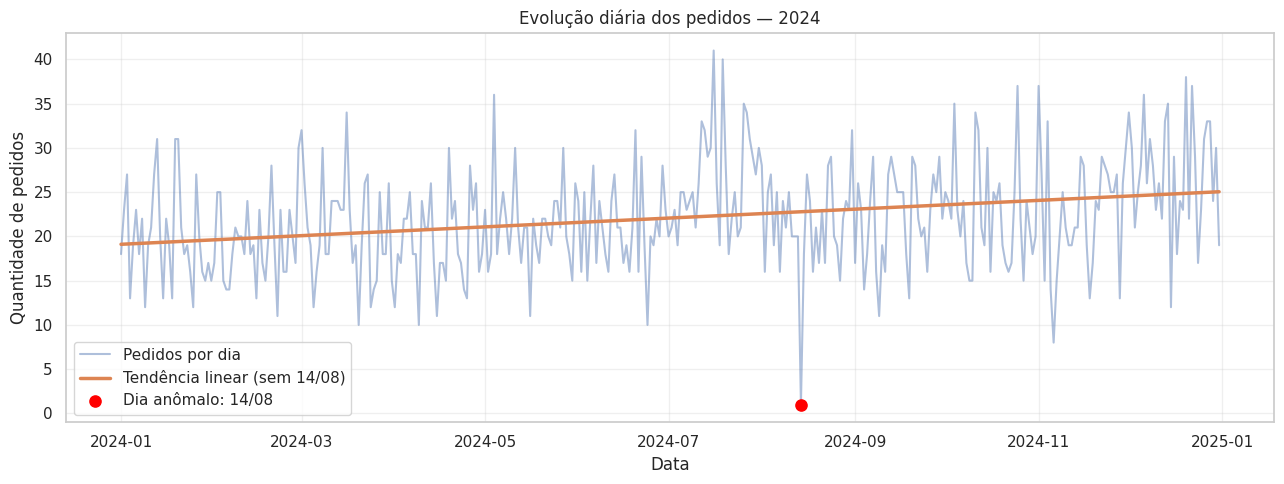


Validação concluída: 8.058 pedidos.
366 dias analisados; 365 utilizados no ajuste linear.


In [ ]:
# Sua solução aqui

# ============================================================
# 1. CONSTRUIR A SÉRIE DIÁRIA DE PEDIDOS
# ============================================================

pedidos_dia = (
    df.set_index('data_hora')
      .resample('D')['pedido_id']
      .count()
)

# ============================================================
# 2. MÉDIA DIÁRIA: 1º TRIMESTRE × 4º TRIMESTRE
# ============================================================

primeiro_tri = pedidos_dia.loc['2024-01-01':'2024-03-31']
quarto_tri = pedidos_dia.loc['2024-10-01':'2024-12-31']

media_1tri = primeiro_tri.mean()
media_4tri = quarto_tri.mean()

crescimento_trimestral = (
    (media_4tri / media_1tri) - 1
) * 100

comparacao = pd.DataFrame({
    'Trimestre': ['1º trimestre', '4º trimestre'],
    'Total de pedidos': [primeiro_tri.sum(), quarto_tri.sum()],
    'Quantidade de dias': [len(primeiro_tri), len(quarto_tri)],
    'Média diária': [media_1tri, media_4tri]
})

print("COMPARAÇÃO ENTRE TRIMESTRES")
display(comparacao.round(2))

print(f"Crescimento da média diária: {crescimento_trimestral:.2f}%")


# ============================================================
# 3. AJUSTAR RETA À SÉRIE DIÁRIA COM NP.POLYFIT
# Excluir o dia anômalo 14/08/2024
# ============================================================

serie_ajuste = pedidos_dia.drop(pd.Timestamp('2024-08-14'))

# Número de dias desde 01/01/2024
x = (serie_ajuste.index - pd.Timestamp('2024-01-01')).days.to_numpy()
y = serie_ajuste.to_numpy()

# Ajuste linear: y = a*x + b
a, b = np.polyfit(x, y, 1)

# Previsões da reta no início e no fim de 2024
inicio = b
fim = a * 365 + b

crescimento_reta = ((fim / inicio) - 1) * 100

print("\nTENDÊNCIA LINEAR — NP.POLYFIT")
print(f"Inclinação: {a:.4f} pedido(s) por dia")
print(f"Valor ajustado em 01/01: {inicio:.2f} pedidos/dia")
print(f"Valor ajustado em 31/12: {fim:.2f} pedidos/dia")
print(f"Crescimento estimado pela reta: {crescimento_reta:.2f}%")
print("Dia excluído do ajuste: 14/08/2024")


# ============================================================
# 4. GRÁFICO DA SÉRIE DIÁRIA E RETA DE TENDÊNCIA
# ============================================================

x_completo = (
    pedidos_dia.index - pd.Timestamp('2024-01-01')
).days.to_numpy()

tendencia = a * x_completo + b

plt.figure(figsize=(13, 5))

plt.plot(
    pedidos_dia.index,
    pedidos_dia.values,
    alpha=0.45,
    label='Pedidos por dia'
)

plt.plot(
    pedidos_dia.index,
    tendencia,
    linewidth=2.5,
    label='Tendência linear (sem 14/08)'
)

plt.scatter(
    pd.Timestamp('2024-08-14'),
    pedidos_dia.loc['2024-08-14'],
    color='red',
    s=65,
    zorder=5,
    label='Dia anômalo: 14/08'
)

plt.title('Evolução diária dos pedidos — 2024')
plt.xlabel('Data')
plt.ylabel('Quantidade de pedidos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 5. VALIDAÇÃO
# ============================================================

assert pedidos_dia.sum() == len(df)
assert len(pedidos_dia) == 366
assert pedidos_dia.loc['2024-08-14'] == 1
assert len(serie_ajuste) == 365

print("\nValidação concluída: 8.058 pedidos.")
print("366 dias analisados; 365 utilizados no ajuste linear.")

*Sua resposta aqui*


**(a) Comparação entre o 1º e o 4º trimestre**

A média diária passou de **20,04 pedidos no 1º trimestre** para **24,09 pedidos no 4º trimestre**, representando crescimento de **20,17%**.

**(b) Tendência linear com `np.polyfit`**

Após excluir o dia anômalo **14/08/2024** do ajuste, a reta apresentou inclinação positiva de **0,0163 pedido por dia a cada dia transcorrido**.

O volume diário estimado pela reta passou de **19,11 pedidos em 01/01** para **25,04 pedidos em 31/12**, correspondendo a um crescimento de **31,07%**.

**Conclusão:** as duas metodologias indicam crescimento do volume de pedidos em 2024. A diferença entre os percentuais decorre dos métodos utilizados: comparação de médias trimestrais e estimativa por tendência linear. O crescimento não foi necessariamente uniforme ao longo do ano.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

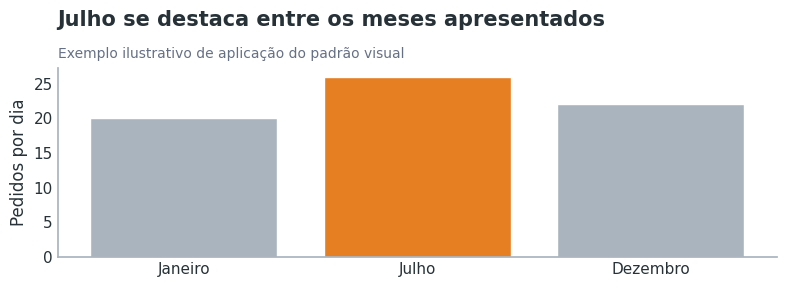

Padrão visual configurado com sucesso!


In [ ]:
# Sua solução aqui

import matplotlib.ticker as mtick

# ============================================================
# 1. PALETA DE CORES
# ============================================================

CORES = {
    'principal': '#1769AA',    # Azul: informação principal
    'destaque': '#E67E22',     # Laranja: ponto de atenção
    'secundaria': '#AAB4BE',   # Cinza: informações secundárias
    'sem_chuva': '#1769AA',    # Azul: sem chuva
    'com_chuva': '#E67E22',    # Laranja: com chuva
    'sem_cupom': '#1769AA',    # Azul: sem cupom
    'com_cupom': '#E67E22',    # Laranja: com cupom
    'texto': '#263238',
    'grade': '#E8EDF2',
    'fundo': '#FFFFFF'
}

# ============================================================
# 2. PADRÃO GERAL DOS GRÁFICOS
# ============================================================

sns.set_theme(style='white', font_scale=1.0)

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.facecolor': CORES['fundo'],
    'axes.facecolor': CORES['fundo'],
    'axes.edgecolor': CORES['secundaria'],
    'axes.labelcolor': CORES['texto'],
    'text.color': CORES['texto'],
    'xtick.color': CORES['texto'],
    'ytick.color': CORES['texto'],
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
    'font.size': 11,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'savefig.dpi': 150
})

# ============================================================
# 3. FORMATADORES DE EIXOS
# ============================================================

def formatar_reais(valor, pos=None):
    """Formata valores em reais: R$ 1.250,50."""
    numero = f'{valor:,.2f}'
    numero = numero.replace(',', 'X').replace('.', ',').replace('X', '.')
    return f'R$ {numero}'

def formatar_percentual(valor, pos=None):
    """Formata percentuais na escala de 0 a 100."""
    return f'{valor:.0f}%'

def formatar_minutos(valor, pos=None):
    """Formata tempos em minutos."""
    return f'{valor:.0f} min'

fmt_reais = mtick.FuncFormatter(formatar_reais)
fmt_percentual = mtick.FuncFormatter(formatar_percentual)
fmt_minutos = mtick.FuncFormatter(formatar_minutos)

# ============================================================
# 4. FUNÇÃO PARA TÍTULO E SUBTÍTULO
# ============================================================

def titulo_grafico(ax, titulo, subtitulo=None):
    """Adiciona título-conclusão e subtítulo ao gráfico."""

    ax.set_title(
        titulo,
        loc='left',
        fontsize=15,
        fontweight='bold',
        pad=30 if subtitulo else 15
    )

    if subtitulo:
        ax.text(
            0, 1.035,
            subtitulo,
            transform=ax.transAxes,
            fontsize=10,
            color='#667085',
            va='bottom'
        )

# ============================================================
# 5. FUNÇÃO PARA LIMPEZA VISUAL
# ============================================================

def limpar_grafico(ax, grade=False):
    """Remove elementos visuais desnecessários."""

    sns.despine(ax=ax)

    ax.tick_params(axis='both', length=0)

    if grade:
        ax.grid(
            axis='y',
            color=CORES['grade'],
            linewidth=0.7
        )
        ax.set_axisbelow(True)
    else:
        ax.grid(False)

# ============================================================
# 6. TESTE DO PADRÃO
# ============================================================

fig, ax = plt.subplots(figsize=(8, 3))

valores = [20, 26, 22]
categorias = ['Janeiro', 'Julho', 'Dezembro']

cores_barras = [
    CORES['secundaria'],
    CORES['destaque'],
    CORES['secundaria']
]

ax.bar(categorias, valores, color=cores_barras)

titulo_grafico(
    ax,
    'Julho se destaca entre os meses apresentados',
    'Exemplo ilustrativo de aplicação do padrão visual'
)

ax.set_ylabel('Pedidos por dia')
limpar_grafico(ax)

plt.tight_layout()
plt.show()

print("Padrão visual configurado com sucesso!")


### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

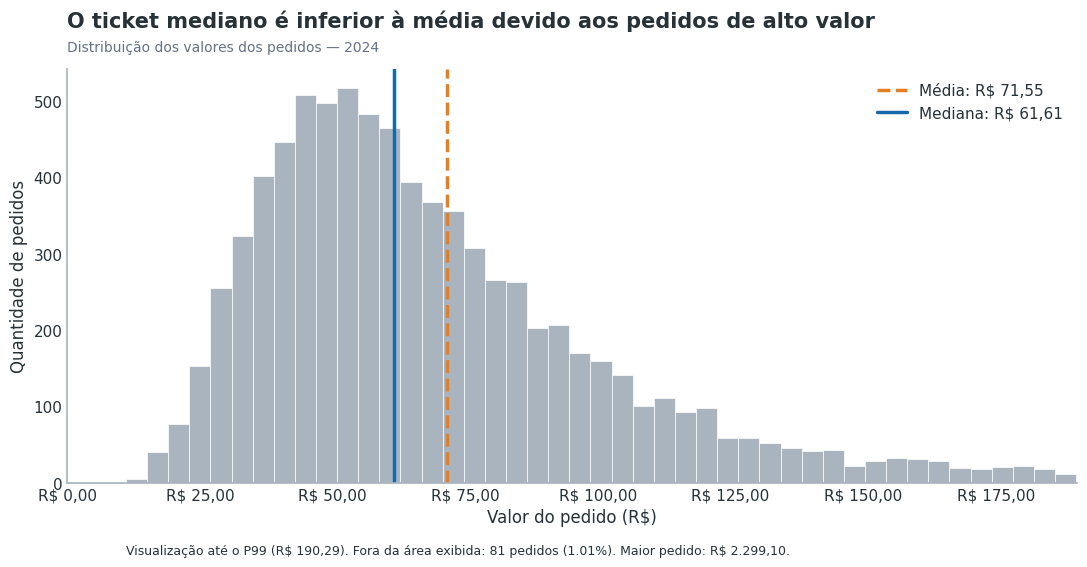

RESUMO DA DISTRIBUIÇÃO DO TICKET
Pedidos analisados: 8058
Média: R$ 71,55
Mediana: R$ 61,61
Percentil 99: R$ 190,29
Maior pedido: R$ 2.299,10
Pedidos acima do P99: 81
Percentual acima do P99: 1.01%

Validação concluída: nenhum pedido foi removido da base.


In [ ]:
# Sua solução aqui

# ============================================================
# 1. ESTATÍSTICAS DO TICKET
# ============================================================

valores = df['valor_pedido'].dropna()

media = valores.mean()
mediana = valores.median()
p99 = valores.quantile(0.99)
maximo = valores.max()

# Pedidos acima do limite visual
pedidos_extremos = (valores > p99).sum()
percentual_extremos = pedidos_extremos / len(valores) * 100

# ============================================================
# 2. HISTOGRAMA — DISTRIBUIÇÃO DO TICKET
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.5))

# Exibir a distribuição até o percentil 99
valores_visiveis = valores[valores <= p99]

ax.hist(
    valores_visiveis,
    bins=45,
    color=CORES['secundaria'],
    edgecolor='white',
    linewidth=0.5
)

# Linha da média
ax.axvline(
    media,
    color=CORES['destaque'],
    linewidth=2.5,
    linestyle='--',
    label=f'Média: {formatar_reais(media)}'
)

# Linha da mediana
ax.axvline(
    mediana,
    color=CORES['principal'],
    linewidth=2.5,
    label=f'Mediana: {formatar_reais(mediana)}'
)

# ============================================================
# 3. TÍTULO-CONCLUSÃO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'O ticket mediano é inferior à média devido aos pedidos de alto valor',
    'Distribuição dos valores dos pedidos — 2024'
)

ax.set_xlabel('Valor do pedido (R$)')
ax.set_ylabel('Quantidade de pedidos')

ax.xaxis.set_major_formatter(fmt_reais)

ax.set_xlim(0, p99)

# Legenda necessária para identificar média e mediana
ax.legend(frameon=False, loc='upper right')

limpar_grafico(ax)

# ============================================================
# 4. NOTA DE TRANSPARÊNCIA SOBRE VALORES EXTREMOS
# ============================================================

nota = (
    f'Visualização até o P99 ({formatar_reais(p99)}). '
    f'Fora da área exibida: {pedidos_extremos} pedidos '
    f'({percentual_extremos:.2f}%). '
    f'Maior pedido: {formatar_reais(maximo)}.'
)

fig.text(
    0.12,
    -0.02,
    nota.replace('$', r'\$'),
    fontsize=9,
    color=CORES['texto']
)

plt.tight_layout()
plt.show()

# ============================================================
# 5. RESUMO NUMÉRICO E VALIDAÇÃO
# ============================================================

print("RESUMO DA DISTRIBUIÇÃO DO TICKET")
print(f"Pedidos analisados: {len(valores)}")
print(f"Média: {formatar_reais(media)}")
print(f"Mediana: {formatar_reais(mediana)}")
print(f"Percentil 99: {formatar_reais(p99)}")
print(f"Maior pedido: {formatar_reais(maximo)}")
print(f"Pedidos acima do P99: {pedidos_extremos}")
print(f"Percentual acima do P99: {percentual_extremos:.2f}%")

assert len(valores) == len(df)
assert len(valores_visiveis) + pedidos_extremos == len(valores)

print("\nValidação concluída: nenhum pedido foi removido da base.")



O histograma evidencia uma **distribuição assimétrica à direita**, com ticket médio de **R\$ 71,55** e mediana de **R\$ 61,61**. A diferença indica que pedidos de valores elevados influenciam a média.

Para melhorar a visualização, o eixo horizontal foi limitado ao **percentil 99 (R\$ 190,29)**. Os **81 pedidos acima desse limite (1,01%)** não aparecem no histograma, mas permanecem na base e em todos os cálculos estatísticos.

O maior pedido registrado foi de **R\$ 2.299,10**.

**Conclusão:** a mediana representa melhor o valor típico dos pedidos, enquanto a média é influenciada pelos valores extremos. O recorte visual permite interpretar a distribuição principal sem ocultar a existência desses pedidos.

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

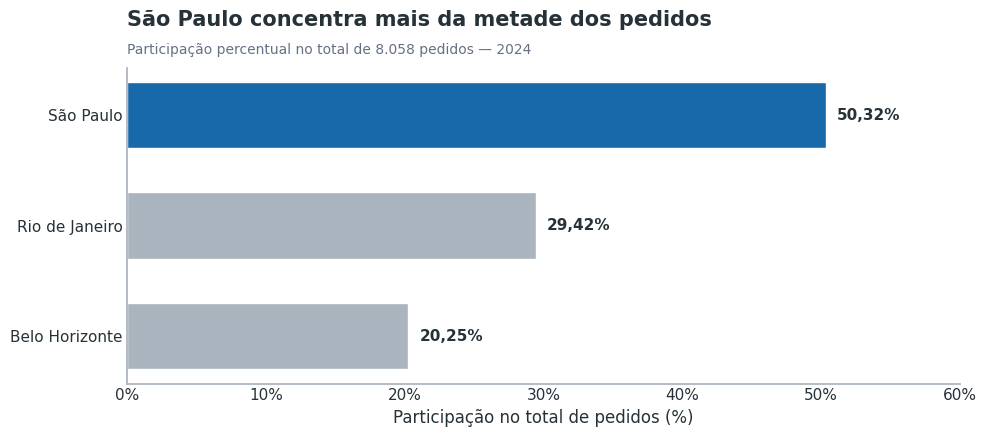

PARTICIPAÇÃO POR CIDADE


,proportion
cidade,
São Paulo,50.32
Rio de Janeiro,29.42
Belo Horizonte,20.25



Soma das participações: 100.00%
Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. CALCULAR A PARTICIPAÇÃO PERCENTUAL
# ============================================================

participacao = (
    df['cidade']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
)

# ============================================================
# 2. GRÁFICO DE BARRAS HORIZONTAIS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4.5))

cores_barras = [
    CORES['principal'] if cidade == 'São Paulo'
    else CORES['secundaria']
    for cidade in participacao.index
]

barras = ax.barh(
    participacao.index,
    participacao.values,
    color=cores_barras,
    height=0.6
)

# ============================================================
# 3. PERCENTUAL ESCRITO EM CADA BARRA
# ============================================================

for barra in barras:
    valor = barra.get_width()

    ax.text(
        valor + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:.2f}%'.replace('.', ','),
        va='center',
        fontsize=11,
        fontweight='bold',
        color=CORES['texto']
    )

# ============================================================
# 4. TÍTULO-CONCLUSÃO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'São Paulo concentra mais da metade dos pedidos',
    'Participação percentual no total de 8.058 pedidos — 2024'
)

ax.set_xlabel('Participação no total de pedidos (%)')
ax.set_ylabel('')

ax.set_xlim(0, 60)
ax.xaxis.set_major_formatter(fmt_percentual)

limpar_grafico(ax)

plt.tight_layout()
plt.show()

# ============================================================
# 5. VALIDAÇÃO
# ============================================================

print("PARTICIPAÇÃO POR CIDADE")
display(participacao.sort_values(ascending=False).round(2))

print(f"\nSoma das participações: {participacao.sum():.2f}%")

assert abs(participacao.sum() - 100) < 0.001

print("Validação concluída!")



O gráfico de barras horizontais apresenta a participação percentual de cada cidade no total de **8.058 pedidos** registrados em 2024.

**São Paulo lidera com 50,32% dos pedidos**, seguida pelo **Rio de Janeiro (29,42%)** e por **Belo Horizonte (20,25%)**.

A ordenação decrescente facilita a comparação, enquanto os percentuais escritos nas barras permitem identificar diretamente a participação de cada cidade.

**Conclusão:** São Paulo concentra mais da metade dos pedidos, demonstrando sua maior representatividade no volume de operações do aplicativo.

### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

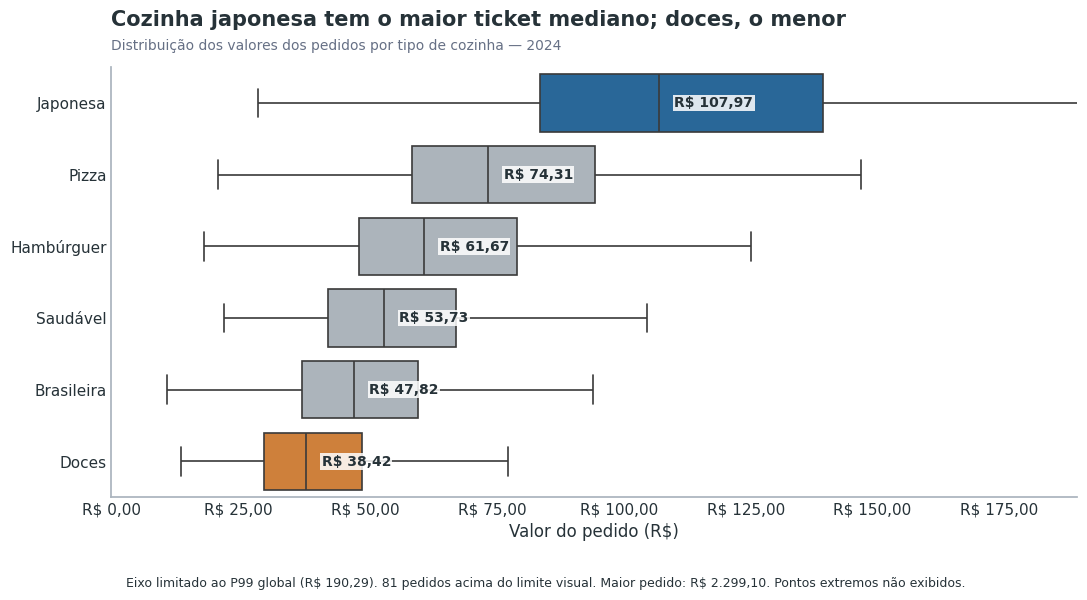

TICKET MEDIANO POR TIPO DE COZINHA


,valor_pedido
tipo_cozinha,
Japonesa,107.97
Pizza,74.31
Hambúrguer,61.67
Saudável,53.74
Brasileira,47.82
Doces,38.42



Maior ticket mediano: Japonesa — R$ 107,97
Menor ticket mediano: Doces — R$ 38,42
Pedidos acima do P99 global: 81
Maior pedido registrado: R$ 2.299,10

Validação concluída: todos os 8.058 pedidos preservados.


In [ ]:
# Sua solução aqui

# ============================================================
# 1. ORDENAR AS COZINHAS PELO TICKET MEDIANO
# ============================================================

medianas = (
    df.groupby('tipo_cozinha')['valor_pedido']
    .median()
    .sort_values(ascending=False)
)

ordem = medianas.index.tolist()

mais_cara = ordem[0]
mais_barata = ordem[-1]

# ============================================================
# 2. DEFINIR CORES E LIMITE VISUAL
# ============================================================

paleta = {
    cozinha: (
        CORES['principal'] if cozinha == mais_cara
        else CORES['destaque'] if cozinha == mais_barata
        else CORES['secundaria']
    )
    for cozinha in ordem
}

p99 = df['valor_pedido'].quantile(0.99)
maximo = df['valor_pedido'].max()

pedidos_acima_p99 = (df['valor_pedido'] > p99).sum()

# ============================================================
# 3. CONSTRUIR O BOXPLOT
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='valor_pedido',
    y='tipo_cozinha',
    order=ordem,
    hue='tipo_cozinha',
    hue_order=ordem,
    palette=paleta,
    dodge=False,
    legend=False,
    showfliers=False,
    linewidth=1.2,
    ax=ax
)

# ============================================================
# 4. DESTACAR MEDIANAS
# ============================================================

for i, cozinha in enumerate(ordem):
    valor = medianas[cozinha]

    ax.text(
        valor + 3,
        i,
        formatar_reais(valor).replace('$', r'\$'),
        va='center',
        fontsize=10,
        fontweight='bold',
        color=CORES['texto'],
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.85,
            pad=1
        )
    )

# ============================================================
# 5. TÍTULO-CONCLUSÃO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Cozinha japonesa tem o maior ticket mediano; doces, o menor',
    'Distribuição dos valores dos pedidos por tipo de cozinha — 2024'
)

ax.set_xlabel('Valor do pedido (R$)')
ax.set_ylabel('')

ax.xaxis.set_major_formatter(fmt_reais)
ax.set_xlim(0, p99)

limpar_grafico(ax)

# ============================================================
# 6. NOTA SOBRE VALORES EXTREMOS
# ============================================================

nota = (
    f'Eixo limitado ao P99 global ({formatar_reais(p99)}). '
    f'{pedidos_acima_p99} pedidos acima do limite visual. '
    f'Maior pedido: {formatar_reais(maximo)}. '
    f'Pontos extremos não exibidos.'
)

fig.text(
    0.12,
    0.01,
    nota.replace('$', r'\$'),
    fontsize=9,
    color=CORES['texto']
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

# ============================================================
# 7. RESUMO E VALIDAÇÃO
# ============================================================

print("TICKET MEDIANO POR TIPO DE COZINHA")
display(medianas.round(2))

print(f"\nMaior ticket mediano: {mais_cara} — {formatar_reais(medianas.iloc[0])}")
print(f"Menor ticket mediano: {mais_barata} — {formatar_reais(medianas.iloc[-1])}")
print(f"Pedidos acima do P99 global: {pedidos_acima_p99}")
print(f"Maior pedido registrado: {formatar_reais(maximo)}")

assert medianas.notna().all()
assert df.groupby('tipo_cozinha').size().sum() == len(df)

print("\nValidação concluída: todos os 8.058 pedidos preservados.")



O boxplot compara a distribuição dos valores dos pedidos entre as seis categorias de cozinha, ordenadas pelo **ticket mediano**, da mais cara para a mais barata.

A **cozinha japonesa apresenta o maior ticket mediano (R\$ 107,97)**, seguida por Pizza (R\$ 74,31), Hambúrguer (R\$ 61,67), Saudável (R\$ 53,74), Brasileira (R\$ 47,82) e Doces (R\$ 38,42).

A diferença entre os extremos é de **R\$ 69,55**, sendo o ticket mediano da cozinha japonesa aproximadamente **2,81 vezes** o de Doces.

Para facilitar a comparação das distribuições, o eixo horizontal foi limitado ao **P99 global (R\$ 190,29)** e os pontos discrepantes não foram desenhados. Existem **81 pedidos acima desse limite (1,01%)**, e o maior pedido registrado foi de **R\$ 2.299,10**. Todos permanecem na base de dados.

**Conclusão:** o tipo de cozinha está associado a diferenças expressivas no valor típico dos pedidos. A cozinha japonesa apresenta o maior ticket mediano, enquanto Doces apresenta o menor. O boxplot também permite comparar a dispersão dos valores entre as categorias, sem que os pedidos extremos comprometam a escala visual.

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

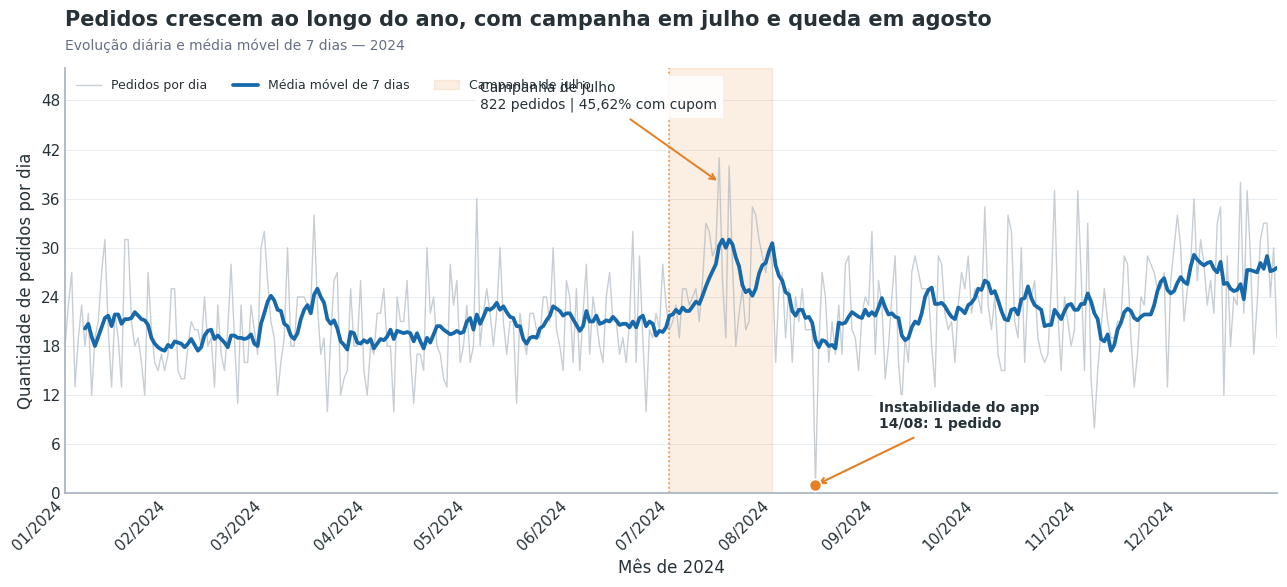

RESUMO DA EVOLUÇÃO DIÁRIA
Dias analisados: 366
Total de pedidos: 8058
Média diária: 22.02 pedidos
Maior volume diário: 41 pedidos em 16/07/2024
Dia de instabilidade: 14/08/2024 — 1 pedido
Pedidos em julho: 822
Média móvel no último dia: 27.57 pedidos/dia

Validação concluída: todos os pedidos foram considerados.


In [ ]:
# Sua solução aqui

import matplotlib.dates as mdates

# ============================================================
# 1. CONSTRUIR A SÉRIE DIÁRIA
# ============================================================

pedidos_diarios = (
    df.set_index('data_hora')
      .resample('D')
      .size()
      .rename('pedidos')
)

# Média móvel de 7 dias
media_movel_7d = pedidos_diarios.rolling(
    window=7,
    min_periods=7
).mean()

# Datas relevantes
inicio_campanha = pd.Timestamp('2024-07-01')
fim_campanha = pd.Timestamp('2024-07-31')
dia_instabilidade = pd.Timestamp('2024-08-14')

pedidos_instabilidade = pedidos_diarios.loc[dia_instabilidade]

# ============================================================
# 2. CRIAR O GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

# Série diária: cinza, para não competir com a tendência
ax.plot(
    pedidos_diarios.index,
    pedidos_diarios.values,
    color=CORES['secundaria'],
    linewidth=1,
    alpha=0.65,
    label='Pedidos por dia',
    zorder=2
)

# Média móvel: azul, em destaque
ax.plot(
    media_movel_7d.index,
    media_movel_7d.values,
    color=CORES['principal'],
    linewidth=2.7,
    label='Média móvel de 7 dias',
    zorder=4
)

# ============================================================
# 3. DESTACAR A CAMPANHA DE JULHO
# ============================================================

ax.axvspan(
    inicio_campanha,
    fim_campanha + pd.Timedelta(days=1),
    color=CORES['destaque'],
    alpha=0.13,
    label='Campanha de julho',
    zorder=1
)

ax.axvline(
    inicio_campanha,
    color=CORES['destaque'],
    linestyle=':',
    linewidth=1.2,
    alpha=0.8
)

ax.annotate(
    'Campanha de julho\n822 pedidos | 45,62% com cupom',
    xy=(pd.Timestamp('2024-07-16'), 38),
    xytext=(pd.Timestamp('2024-05-05'), 47),
    fontsize=10,
    color=CORES['texto'],
    ha='left',
    arrowprops=dict(
        arrowstyle='->',
        color=CORES['destaque'],
        linewidth=1.4
    ),
    bbox=dict(
        facecolor='white',
        edgecolor='none',
        alpha=0.9,
        pad=4
    )
)

# ============================================================
# 4. ANOTAR O DIA DE INSTABILIDADE
# ============================================================

ax.scatter(
    dia_instabilidade,
    pedidos_instabilidade,
    color=CORES['destaque'],
    s=75,
    edgecolor='white',
    linewidth=1.2,
    zorder=6
)

ax.annotate(
    f'Instabilidade do app\n14/08: {pedidos_instabilidade} pedido',
    xy=(dia_instabilidade, pedidos_instabilidade),
    xytext=(pd.Timestamp('2024-09-02'), 8),
    fontsize=10,
    fontweight='bold',
    color=CORES['texto'],
    arrowprops=dict(
        arrowstyle='->',
        color=CORES['destaque'],
        linewidth=1.5
    ),
    bbox=dict(
        facecolor='white',
        edgecolor='none',
        alpha=0.95,
        pad=4
    )
)

# ============================================================
# 5. TÍTULO-CONCLUSÃO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Pedidos crescem ao longo do ano, com campanha em julho e queda em agosto',
    'Evolução diária e média móvel de 7 dias — 2024'
)

ax.set_xlabel('Mês de 2024')
ax.set_ylabel('Quantidade de pedidos por dia')

# Eixo temporal: um marcador por mês
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha='right'
)

ax.set_xlim(
    pd.Timestamp('2024-01-01'),
    pd.Timestamp('2024-12-31')
)

ax.set_ylim(bottom=0, top=max(52, pedidos_diarios.max() + 8))

ax.yaxis.set_major_locator(
    plt.MaxNLocator(integer=True)
)

ax.legend(
    frameon=False,
    loc='upper left',
    ncol=3,
    fontsize=9
)

limpar_grafico(ax, grade=True)

plt.tight_layout()
plt.show()

# ============================================================
# 6. RESUMO E VALIDAÇÃO
# ============================================================

print("RESUMO DA EVOLUÇÃO DIÁRIA")

print(f"Dias analisados: {len(pedidos_diarios)}")
print(f"Total de pedidos: {pedidos_diarios.sum()}")
print(f"Média diária: {pedidos_diarios.mean():.2f} pedidos")

print(
    f"Maior volume diário: {pedidos_diarios.max()} pedidos "
    f"em {pedidos_diarios.idxmax():%d/%m/%Y}"
)

print(
    f"Dia de instabilidade: "
    f"{dia_instabilidade:%d/%m/%Y} — "
    f"{pedidos_instabilidade} pedido"
)

pedidos_julho = pedidos_diarios.loc['2024-07'].sum()
print(f"Pedidos em julho: {pedidos_julho}")

print(
    f"Média móvel no último dia: "
    f"{media_movel_7d.iloc[-1]:.2f} pedidos/dia"
)

assert pedidos_diarios.sum() == len(df)
assert len(pedidos_diarios) == 366
assert pedidos_instabilidade == 1
assert pedidos_julho == 822

print("\nValidação concluída: todos os pedidos foram considerados.")




O gráfico apresenta a evolução diária dos **8.058 pedidos registrados ao longo dos 366 dias de 2024**, acompanhada de uma **média móvel de 7 dias**, utilizada para suavizar as oscilações e facilitar a identificação de tendências.

A média geral foi de **22,02 pedidos por dia**. O maior volume ocorreu em **16 de julho de 2024**, com **41 pedidos**.

O mês de julho, período da campanha promocional, registrou **822 pedidos**, com utilização de cupons em **45,62%** deles. O aumento da atividade nesse período coincide com a campanha, mas essa associação não permite afirmar uma relação causal.

Em **14 de agosto de 2024**, foi registrado apenas **1 pedido**, caracterizando uma queda excepcional associada ao dia de instabilidade do aplicativo. Esse registro foi preservado na série histórica e no cálculo da média móvel.

No último dia do ano, a média móvel de 7 dias alcançou **27,57 pedidos/dia**, acima da média anual de 22,02 pedidos/dia.

**Conclusão:** a série diária evidencia oscilações na demanda, maior movimentação durante a campanha de julho e uma queda atípica no dia de instabilidade do aplicativo. A média móvel facilita a identificação da tendência subjacente, indicando um encerramento de ano com volume de pedidos superior à média anual.

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

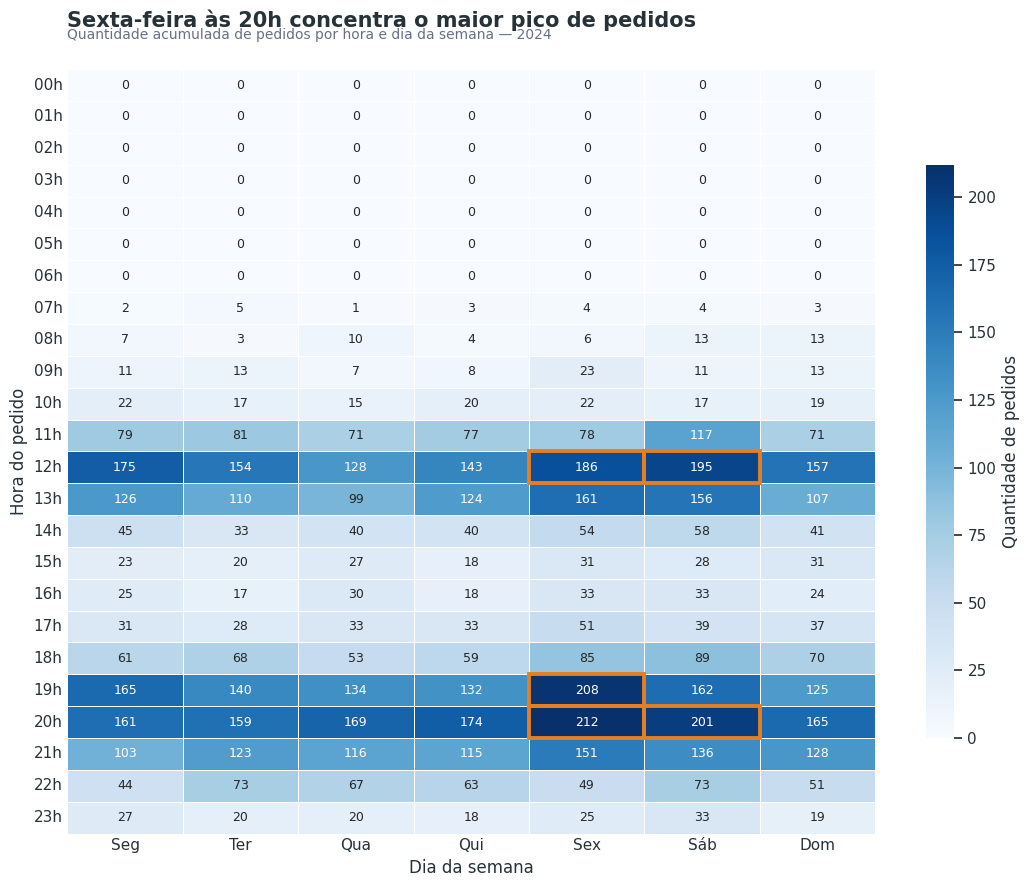

CINCO MAIORES PICOS DE PEDIDOS
Sex, às 20h: 212 pedidos
Sex, às 19h: 208 pedidos
Sáb, às 20h: 201 pedidos
Sáb, às 12h: 195 pedidos
Sex, às 12h: 186 pedidos

TOTAL DE PEDIDOS POR DIA DA SEMANA


,0
dia_semana,
Sex,1379
Sáb,1365
Seg,1107
Dom,1074
Ter,1064
Qui,1049
Qua,1020



Total no mapa de calor: 8058

Validação concluída: todos os pedidos foram considerados.


In [ ]:
# Sua solução aqui

# ============================================================
# 1. CONSTRUIR A TABELA HORA × DIA DA SEMANA
# ============================================================

ordem_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

tabela_horarios = pd.crosstab(
    df['hora'],
    df['dia_semana']
)

tabela_horarios = tabela_horarios.reindex(
    index=range(24),
    columns=ordem_dias,
    fill_value=0
)

# ============================================================
# 2. IDENTIFICAR OS CINCO MAIORES PICOS
# ============================================================

top5 = (
    tabela_horarios
    .stack()
    .sort_values(ascending=False)
    .head(5)
)

# ============================================================
# 3. CRIAR O MAPA DE CALOR
# ============================================================

fig, ax = plt.subplots(figsize=(11, 9))

# Paleta: valores baixos claros e picos em azul intenso
mapa = sns.heatmap(
    tabela_horarios,
    cmap='Blues',
    annot=True,
    fmt='d',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={
        'label': 'Quantidade de pedidos',
        'shrink': 0.75
    },
    annot_kws={'fontsize': 9},
    ax=ax
)

# ============================================================
# 4. DESTACAR OS CINCO MAIORES PICOS
# ============================================================

for (hora, dia), quantidade in top5.items():

    linha = tabela_horarios.index.get_loc(hora)
    coluna = tabela_horarios.columns.get_loc(dia)

    destaque = plt.Rectangle(
        (coluna, linha),
        1,
        1,
        fill=False,
        edgecolor=CORES['destaque'],
        linewidth=2.8
    )

    ax.add_patch(destaque)

# ============================================================
# 5. TÍTULO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Sexta-feira às 20h concentra o maior pico de pedidos',
    'Quantidade acumulada de pedidos por hora e dia da semana — 2024'
)

ax.set_xlabel('Dia da semana')
ax.set_ylabel('Hora do pedido')

ax.set_yticklabels(
    [f'{int(h):02d}h' for h in tabela_horarios.index],
    rotation=0
)

ax.set_xticklabels(
    ordem_dias,
    rotation=0
)

ax.tick_params(axis='both', length=0)

plt.tight_layout()
plt.show()

# ============================================================
# 6. RESUMO E VALIDAÇÃO
# ============================================================

print("CINCO MAIORES PICOS DE PEDIDOS")

for (hora, dia), quantidade in top5.items():
    print(f"{dia}, às {hora:02d}h: {quantidade} pedidos")

print("\nTOTAL DE PEDIDOS POR DIA DA SEMANA")
display(tabela_horarios.sum().sort_values(ascending=False))

print(f"\nTotal no mapa de calor: {tabela_horarios.to_numpy().sum()}")

assert tabela_horarios.to_numpy().sum() == len(df)
assert tabela_horarios.shape == (24, 7)

print("\nValidação concluída: todos os pedidos foram considerados.")




O mapa de calor apresenta a distribuição dos **8.058 pedidos** por hora e dia da semana, permitindo identificar os períodos de maior concentração da demanda.

Os cinco maiores picos registrados foram:

1. **Sexta-feira, às 20h:** 212 pedidos.
2. **Sexta-feira, às 19h:** 208 pedidos.
3. **Sábado, às 20h:** 201 pedidos.
4. **Sábado, às 12h:** 195 pedidos.
5. **Sexta-feira, às 12h:** 186 pedidos.

A análise evidencia maior concentração de pedidos nos períodos de **almoço (12h–13h)** e **jantar (19h–21h)**, principalmente às sextas-feiras e aos sábados.

No acumulado por dia da semana, a sexta-feira apresentou o maior volume, com **1.379 pedidos**, seguida pelo sábado, com **1.365 pedidos**.

**Conclusão:** a demanda apresenta padrões temporais bem definidos, com maior intensidade nas sextas-feiras e nos sábados, especialmente nos horários tradicionais de refeição. Esses períodos merecem atenção no planejamento da capacidade operacional, na disponibilidade de entregadores e na preparação dos restaurantes.

**Observação metodológica:** o mapa apresenta quantidades acumuladas ao longo do ano, não médias por ocorrência de cada dia da semana. Em 2024, segundas-feiras e terças-feiras ocorreram 53 vezes, enquanto os demais dias ocorreram 52 vezes.

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

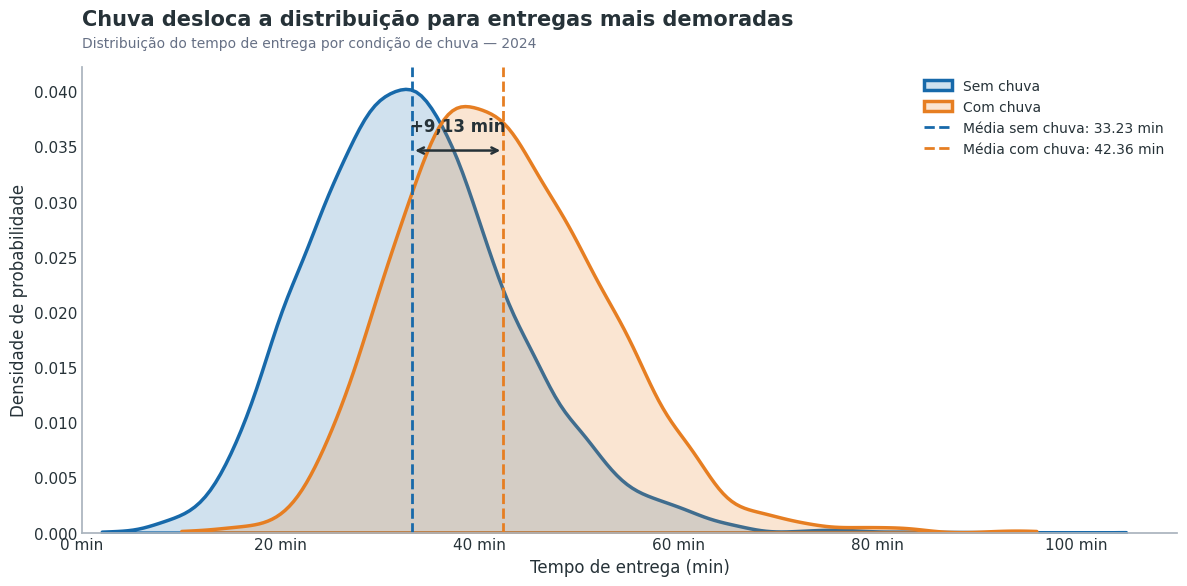

CHUVA E TEMPO DE ENTREGA
Entregas válidas sem chuva: 5667
Entregas válidas com chuva: 2358
Tempo médio sem chuva: 33.23 min
Tempo médio com chuva: 42.36 min
Diferença absoluta: +9.13 min
Aumento percentual: +27.48%
Mediana sem chuva: 33.00 min
Mediana com chuva: 42.00 min

Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

dados_chuva = df[
    df['tempo_entrega_min'].notna()
].copy()

# Garantir a identificação das condições
dados_chuva['condicao_chuva'] = dados_chuva['chuva'].map({
    True: 'Com chuva',
    False: 'Sem chuva'
})

# Compatibilidade caso a coluna contenha strings
if dados_chuva['condicao_chuva'].isna().any():
    dados_chuva['condicao_chuva'] = (
        dados_chuva['chuva']
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            'sim': 'Com chuva',
            'não': 'Sem chuva',
            'nao': 'Sem chuva',
            'true': 'Com chuva',
            'false': 'Sem chuva'
        })
    )

assert dados_chuva['condicao_chuva'].notna().all(), (
    "Existem valores de chuva não reconhecidos."
)

sem_chuva = dados_chuva.loc[
    dados_chuva['condicao_chuva'] == 'Sem chuva',
    'tempo_entrega_min'
]

com_chuva = dados_chuva.loc[
    dados_chuva['condicao_chuva'] == 'Com chuva',
    'tempo_entrega_min'
]

media_sem = sem_chuva.mean()
media_com = com_chuva.mean()

diferenca = media_com - media_sem
aumento_pct = diferenca / media_sem * 100

# ============================================================
# 2. CONSTRUIR AS CURVAS DE DENSIDADE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

sns.kdeplot(
    x=sem_chuva,
    color=CORES['sem_chuva'],
    fill=True,
    alpha=0.20,
    linewidth=2.5,
    bw_adjust=1.0,
    cut=0,
    label='Sem chuva',
    ax=ax
)

sns.kdeplot(
    x=com_chuva,
    color=CORES['com_chuva'],
    fill=True,
    alpha=0.20,
    linewidth=2.5,
    bw_adjust=1.0,
    cut=0,
    label='Com chuva',
    ax=ax
)

# ============================================================
# 3. MARCAR AS MÉDIAS
# ============================================================

ax.axvline(
    media_sem,
    color=CORES['sem_chuva'],
    linestyle='--',
    linewidth=2,
    label=f'Média sem chuva: {media_sem:.2f} min'
)

ax.axvline(
    media_com,
    color=CORES['com_chuva'],
    linestyle='--',
    linewidth=2,
    label=f'Média com chuva: {media_com:.2f} min'
)

# ============================================================
# 4. EVIDENCIAR O DESLOCAMENTO
# ============================================================

altura = ax.get_ylim()[1] * 0.82

ax.annotate(
    '',
    xy=(media_com, altura),
    xytext=(media_sem, altura),
    arrowprops=dict(
        arrowstyle='<->',
        color=CORES['texto'],
        linewidth=1.8
    )
)

ax.text(
    (media_sem + media_com) / 2,
    altura * 1.04,
    f'+{diferenca:.2f} min'.replace('.', ','),
    ha='center',
    va='bottom',
    fontsize=12,
    fontweight='bold',
    color=CORES['texto']
)

# ============================================================
# 5. TÍTULO-CONCLUSÃO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Chuva desloca a distribuição para entregas mais demoradas',
    'Distribuição do tempo de entrega por condição de chuva — 2024'
)

ax.set_xlabel('Tempo de entrega (min)')
ax.set_ylabel('Densidade de probabilidade')

ax.xaxis.set_major_formatter(fmt_minutos)

ax.set_xlim(left=0)

ax.legend(
    frameon=False,
    loc='upper right',
    fontsize=10
)

limpar_grafico(ax)

plt.tight_layout()
plt.show()

# ============================================================
# 6. RESUMO E VALIDAÇÃO
# ============================================================

print("CHUVA E TEMPO DE ENTREGA")

print(f"Entregas válidas sem chuva: {len(sem_chuva)}")
print(f"Entregas válidas com chuva: {len(com_chuva)}")

print(f"Tempo médio sem chuva: {media_sem:.2f} min")
print(f"Tempo médio com chuva: {media_com:.2f} min")

print(f"Diferença absoluta: +{diferenca:.2f} min")
print(f"Aumento percentual: +{aumento_pct:.2f}%")

print(f"Mediana sem chuva: {sem_chuva.median():.2f} min")
print(f"Mediana com chuva: {com_chuva.median():.2f} min")

assert len(sem_chuva) + len(com_chuva) == 8025
assert media_com > media_sem

print("\nValidação concluída!")



O gráfico de densidade (KDE) compara a distribuição do tempo de entrega em condições **com e sem chuva**, considerando 8.025 entregas com tempos válidos.

Foram analisadas **5.667 entregas sem chuva** e **2.358 entregas com chuva**.

O tempo médio de entrega foi de **33,23 minutos sem chuva** e **42,36 minutos com chuva**, representando um aumento de **9,13 minutos (+27,48%)** nas condições chuvosas.

As medianas também apresentam diferença expressiva: **33 minutos sem chuva** e **42 minutos com chuva**, indicando que o deslocamento não se limita à influência de valores extremos.

**Conclusão:** a chuva está associada a tempos de entrega significativamente maiores em termos descritivos. O deslocamento da distribuição para a direita evidencia maior concentração de entregas demoradas durante períodos chuvosos.

**Implicação operacional:** os resultados sugerem a necessidade de considerar as condições meteorológicas no planejamento logístico, no dimensionamento de entregadores e na estimativa dos prazos informados aos clientes.

**Observação metodológica:** a análise identifica uma associação entre chuva e tempo de entrega, sem estabelecer causalidade. A significância estatística da diferença não foi avaliada nesta etapa.

### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

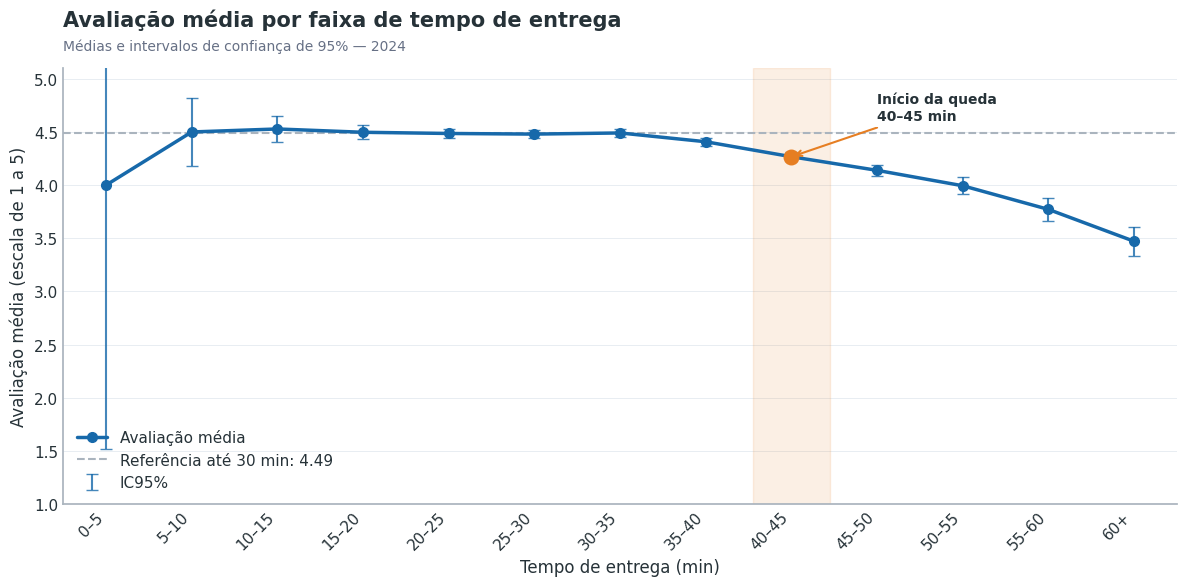

AVALIAÇÃO POR FAIXA DE TEMPO


,quantidade,media,ic_inferior,ic_superior
faixa_tempo,,,,
0–5,3,4.000,1.516,6.484
5–10,20,4.500,4.178,4.822
10–15,106,4.528,4.409,4.648
15–20,352,4.497,4.432,4.562
20–25,673,4.486,4.440,4.532
25–30,1023,4.480,4.443,4.517
30–35,1249,4.491,4.456,4.526
35–40,1154,4.408,4.370,4.446
40–45,857,4.267,4.223,4.312



Entregas com tempo e avaliação válidos: 6685
Avaliação de referência (até 30 min): 4.486
Início da queda pelo critério definido: 40–45 min
Total de avaliações agrupadas: 6685

Validação concluída!


In [ ]:
# Sua solução aqui

from scipy.stats import t

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

dados = df[
    ['tempo_entrega_min', 'avaliacao']
].dropna().copy()

# Faixas: (0,5], (5,10], ... (55,60], (60,+inf)
limites = list(range(0, 65, 5)) + [np.inf]

rotulos = [
    f'{i}–{i+5}'
    for i in range(0, 60, 5)
] + ['60+']

dados['faixa_tempo'] = pd.cut(
    dados['tempo_entrega_min'],
    bins=limites,
    labels=rotulos,
    right=True,
    include_lowest=True
)

# ============================================================
# 2. CALCULAR MÉDIA E IC95% POR FAIXA
# ============================================================

resumo = (
    dados.groupby('faixa_tempo', observed=True)['avaliacao']
    .agg(
        quantidade='count',
        media='mean',
        desvio='std'
    )
    .reindex(rotulos)
)

resumo['erro_padrao'] = (
    resumo['desvio'] / np.sqrt(resumo['quantidade'])
)

resumo['margem_ic95'] = (
    t.ppf(0.975, resumo['quantidade'] - 1)
    * resumo['erro_padrao']
)

resumo['ic_inferior'] = (
    resumo['media'] - resumo['margem_ic95']
)

resumo['ic_superior'] = (
    resumo['media'] + resumo['margem_ic95']
)

# ============================================================
# 3. IDENTIFICAR O INÍCIO DA QUEDA
# ============================================================

# Critério descritivo:
# primeira faixa cuja média fica pelo menos 0,10 ponto
# abaixo da média das entregas de até 30 minutos.

referencia = dados.loc[
    dados['tempo_entrega_min'] <= 30,
    'avaliacao'
].mean()

queda_minima = 0.10

candidatas = resumo.index[
    (resumo['media'] <= referencia - queda_minima)
    & (resumo['quantidade'] >= 30)
]

faixa_queda = candidatas[0] if len(candidatas) else None

# ============================================================
# 4. CONSTRUIR O GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(rotulos))

validos = resumo['media'].notna()

ax.plot(
    x[validos],
    resumo.loc[validos, 'media'],
    color=CORES['principal'],
    linewidth=2.5,
    marker='o',
    markersize=7,
    label='Avaliação média',
    zorder=3
)

# Intervalos de confiança
ic_validos = (
    validos
    & resumo['margem_ic95'].notna()
)

ax.errorbar(
    x[ic_validos],
    resumo.loc[ic_validos, 'media'],
    yerr=resumo.loc[ic_validos, 'margem_ic95'],
    fmt='none',
    ecolor=CORES['principal'],
    elinewidth=1.5,
    capsize=4,
    alpha=0.8,
    label='IC95%',
    zorder=2
)

# Linha de referência
ax.axhline(
    referencia,
    color=CORES['secundaria'],
    linestyle='--',
    linewidth=1.5,
    label=f'Referência até 30 min: {referencia:.2f}'
)

# ============================================================
# 5. DESTACAR O INÍCIO DA QUEDA
# ============================================================

if faixa_queda is not None:

    posicao = rotulos.index(faixa_queda)
    valor_queda = resumo.loc[faixa_queda, 'media']

    ax.axvspan(
        posicao - 0.45,
        posicao + 0.45,
        color=CORES['destaque'],
        alpha=0.12
    )

    ax.scatter(
        posicao,
        valor_queda,
        color=CORES['destaque'],
        s=110,
        zorder=5
    )

    ax.annotate(
        f'Início da queda\n{faixa_queda} min',
        xy=(posicao, valor_queda),
        xytext=(posicao + 1.0, min(4.95, valor_queda + 0.35)),
        fontsize=10,
        fontweight='bold',
        color=CORES['texto'],
        arrowprops=dict(
            arrowstyle='->',
            color=CORES['destaque'],
            linewidth=1.5
        ),
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.95,
            pad=3
        )
    )

# ============================================================
# 6. TÍTULO E FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Avaliação média por faixa de tempo de entrega',
    'Médias e intervalos de confiança de 95% — 2024'
)

ax.set_xlabel('Tempo de entrega (min)')
ax.set_ylabel('Avaliação média (escala de 1 a 5)')

ax.set_xticks(x)
ax.set_xticklabels(rotulos, rotation=45, ha='right')

ax.set_ylim(1, 5.1)
ax.set_xlim(-0.5, len(rotulos) - 0.5)

ax.legend(frameon=False, loc='lower left')

limpar_grafico(ax, grade=True)

plt.tight_layout()
plt.show()

# ============================================================
# 7. RESUMO E VALIDAÇÃO
# ============================================================

print("AVALIAÇÃO POR FAIXA DE TEMPO")

display(
    resumo[
        ['quantidade', 'media', 'ic_inferior', 'ic_superior']
    ].round(3)
)

print(f"\nEntregas com tempo e avaliação válidos: {len(dados)}")
print(f"Avaliação de referência (até 30 min): {referencia:.3f}")

if faixa_queda is not None:
    print(f"Início da queda pelo critério definido: {faixa_queda} min")
else:
    print("Nenhuma faixa atendeu ao critério de queda definido.")

print(f"Total de avaliações agrupadas: {resumo['quantidade'].sum()}")

assert resumo['quantidade'].sum() == len(dados)

print("\nValidação concluída!")


O gráfico apresenta a **avaliação média dos clientes por faixas de 5 minutos de tempo de entrega**, acompanhada de intervalos de confiança de 95%.

Foram analisados **6.685 pedidos com tempo de entrega e avaliação válidos**.

As avaliações permanecem relativamente elevadas até a faixa de **30–35 minutos**, que apresenta média de **4,491 pontos**.

A partir de **35–40 minutos**, observa-se o início de uma tendência de redução nas avaliações. Entretanto, a faixa de **40–45 minutos**, com média de **4,267 pontos**, é a primeira a atender ao critério quantitativo estabelecido: avaliação pelo menos 0,10 ponto inferior à média de referência das entregas de até 30 minutos (4,486), considerando no mínimo 30 avaliações por faixa.

A queda prossegue nas faixas seguintes, alcançando **3,994 pontos entre 50–55 minutos** e **3,472 pontos nas entregas superiores a 60 minutos**.

Os intervalos de confiança de 95% permitem avaliar a precisão das médias estimadas. Faixas com poucas observações apresentam maior incerteza, especialmente a de 0–5 minutos, com apenas três avaliações.

**Conclusão:** tempos de entrega mais elevados estão associados a avaliações progressivamente menores. A tendência de queda começa a aparecer após 35 minutos e torna-se mais evidente a partir de 40 minutos.

**Implicação operacional:** os resultados sugerem priorizar a redução de entregas superiores a 40 minutos, acompanhando esse indicador para preservar a satisfação dos clientes.

**Observação metodológica:** o critério utilizado para identificar o início da queda é descritivo. Os intervalos de confiança não demonstram causalidade nem substituem testes estatísticos específicos.

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

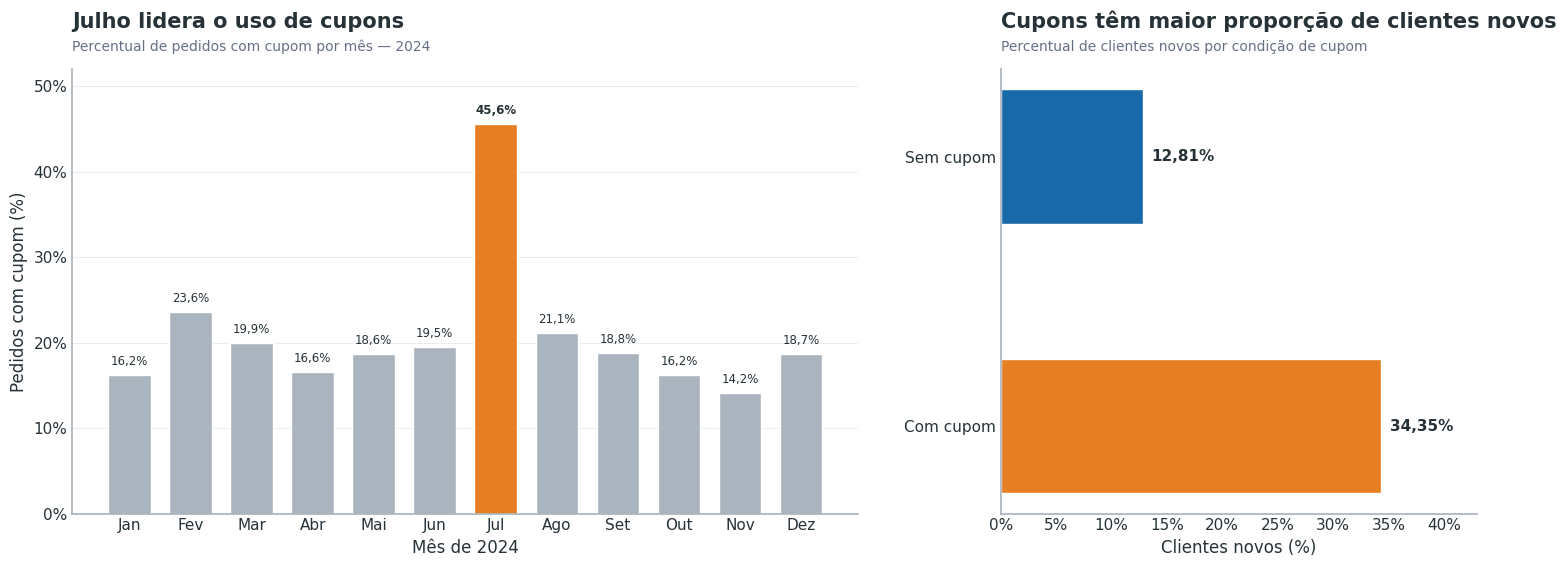

PAINEL A — TAXA MENSAL DE USO DE CUPOM


,Mês,Uso de cupom (%)
0,Jan,16.18
1,Fev,23.61
2,Mar,19.94
3,Abr,16.55
4,Mai,18.64
5,Jun,19.52
6,Jul,45.62
7,Ago,21.15
8,Set,18.83
9,Out,16.19



PAINEL B — CLIENTES NOVOS


,Condição,Clientes novos (%)
0,Sem cupom,12.81
1,Com cupom,34.35



Julho: 45.62% dos pedidos com cupom
Diferença na proporção de clientes novos: 21.54 pontos percentuais

Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

# Taxa mensal de utilização de cupons
taxa_mensal = (
    df.groupby('mes')['cupom']
    .mean()
    .mul(100)
    .reindex(range(1, 13))
)

meses = [
    'Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
    'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'
]

# Percentual de clientes novos por condição de cupom
taxa_novos = (
    df.groupby('cupom')['cliente_novo']
    .mean()
    .mul(100)
    .reindex([False, True])
)

# ============================================================
# 2. CRIAR FIGURA COM DOIS PAINÉIS
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(15, 5.8),
    gridspec_kw={'width_ratios': [1.65, 1]}
)

# ============================================================
# 3. PAINEL A — USO MENSAL DE CUPOM
# ============================================================

cores_meses = [
    CORES['destaque'] if mes == 7
    else CORES['secundaria']
    for mes in range(1, 13)
]

barras1 = ax1.bar(
    meses,
    taxa_mensal.values,
    color=cores_meses,
    width=0.7
)

for i, (barra, valor) in enumerate(
    zip(barras1, taxa_mensal.values)
):
    ax1.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.8,
        f'{valor:.1f}%'.replace('.', ','),
        ha='center',
        va='bottom',
        fontsize=8.5,
        fontweight='bold' if i == 6 else 'normal',
        color=CORES['texto']
    )

titulo_grafico(
    ax1,
    'Julho lidera o uso de cupons',
    'Percentual de pedidos com cupom por mês — 2024'
)

ax1.set_xlabel('Mês de 2024')
ax1.set_ylabel('Pedidos com cupom (%)')
ax1.set_ylim(0, max(52, taxa_mensal.max() + 6))
ax1.yaxis.set_major_formatter(fmt_percentual)

limpar_grafico(ax1, grade=True)

# ============================================================
# 4. PAINEL B — CLIENTES NOVOS COM E SEM CUPOM
# ============================================================

grupos = ['Sem cupom', 'Com cupom']
valores = taxa_novos.values

barras2 = ax2.barh(
    grupos,
    valores,
    color=[CORES['principal'], CORES['destaque']],
    height=0.5
)

for barra, valor in zip(barras2, valores):
    ax2.text(
        valor + 0.8,
        barra.get_y() + barra.get_height() / 2,
        f'{valor:.2f}%'.replace('.', ','),
        va='center',
        fontsize=11,
        fontweight='bold',
        color=CORES['texto']
    )

titulo_grafico(
    ax2,
    'Cupons têm maior proporção de clientes novos',
    'Percentual de clientes novos por condição de cupom'
)

ax2.set_xlabel('Clientes novos (%)')
ax2.set_ylabel('')
ax2.set_xlim(0, 43)
ax2.xaxis.set_major_formatter(fmt_percentual)

# Sem cupom acima, com cupom abaixo
ax2.invert_yaxis()

limpar_grafico(ax2, grade=False)

# ============================================================
# 5. AJUSTAR ESPAÇAMENTO
# ============================================================

plt.tight_layout(w_pad=3)
plt.show()

# ============================================================
# 6. RESUMO E VALIDAÇÃO
# ============================================================

print("PAINEL A — TAXA MENSAL DE USO DE CUPOM")

display(
    pd.DataFrame({
        'Mês': meses,
        'Uso de cupom (%)': taxa_mensal.values
    }).round(2)
)

print("\nPAINEL B — CLIENTES NOVOS")

display(
    pd.DataFrame({
        'Condição': grupos,
        'Clientes novos (%)': valores
    }).round(2)
)

diferenca_pp = taxa_novos.loc[True] - taxa_novos.loc[False]

print(
    f"\nJulho: {taxa_mensal.loc[7]:.2f}% dos pedidos com cupom"
)

print(
    f"Diferença na proporção de clientes novos: "
    f"{diferenca_pp:.2f} pontos percentuais"
)

assert taxa_mensal.notna().all()
assert taxa_novos.notna().all()
assert taxa_mensal.idxmax() == 7

print("\nValidação concluída!")


O gráfico apresenta dois painéis que permitem analisar a utilização de cupons promocionais e sua associação com a participação de clientes novos.

**Painel A — Utilização mensal de cupons**

O mês de **julho apresentou a maior taxa de utilização de cupons de 2024, com 45,62% dos pedidos**, destacando-se expressivamente dos demais meses.

Em junho, a taxa havia sido de **19,52%**, enquanto em agosto foi de **21,15%**. Esse comportamento evidencia uma concentração excepcional do uso de cupons em julho, período da campanha promocional.

**Painel B — Clientes novos com e sem cupom**

Entre os pedidos realizados **sem cupom, 12,81% foram de clientes novos**. Já entre os pedidos **com cupom, essa proporção alcançou 34,35%**.

A diferença foi de **21,54 pontos percentuais**, indicando uma associação positiva entre utilização de cupons e participação de clientes novos.

**Conclusão:** julho concentrou a maior intensidade de utilização de cupons do ano. Além disso, os pedidos com cupom apresentaram uma proporção de clientes novos aproximadamente **2,68 vezes maior** do que os pedidos sem cupom.

**Implicação para o negócio:** os resultados sugerem que os cupons podem ser relevantes nas estratégias de aquisição de clientes. Entretanto, é necessário avaliar custos promocionais, comportamento de recompra e rentabilidade para determinar sua efetividade comercial.

**Observação metodológica:** os resultados demonstram associações descritivas, não sendo possível afirmar que os cupons causaram diretamente o aumento da participação de clientes novos.

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

*Sua resposta aqui*

| Tarefa | Tipo de gráfico | Justificativa |
|---|---|---|
| **7.1** | Histograma | Permite visualizar a distribuição dos valores dos pedidos, identificando concentração, assimetria e valores extremos, diferentemente de um gráfico de barras categóricas. |
| **7.2** | Barras horizontais | Facilita a comparação e a ordenação da participação percentual das cidades, tornando as diferenças mais claras do que em um gráfico de pizza. |
| **7.3** | Boxplot | Permite comparar medianas, dispersão e amplitude dos valores dos pedidos entre tipos de cozinha, informações que um gráfico de médias não apresenta. |
| **7.4** | Série temporal com média móvel | Evidencia a evolução diária dos pedidos e a tendência suavizada ao longo do ano, preservando a sequência temporal que gráficos de barras agregadas não mostram. |
| **7.5** | Mapa de calor (heatmap) | Permite identificar simultaneamente os horários e dias da semana com maior concentração de pedidos, evitando a sobreposição de várias linhas. |
| **7.6** | Curvas de densidade (KDE) | Evidenciam o deslocamento e a sobreposição das distribuições dos tempos de entrega com e sem chuva, além da simples comparação entre médias. |
| **7.7** | Linha com intervalos de confiança | Mostra como a avaliação média varia entre faixas ordenadas de tempo, destacando a tendência de queda e a incerteza das estimativas. |
| **7.8** | Barras em dois painéis | Permitem comparar separadamente a evolução mensal do uso de cupons e a proporção de clientes novos por grupo, sem misturar escalas e categorias diferentes. |

**Conclusão:** a escolha de cada visualização considerou a natureza das variáveis, o objetivo analítico e a necessidade de comunicar os resultados com clareza, precisão e facilidade de interpretação.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

MATRIZ DE CORRELAÇÃO — PEARSON


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.704,0.578,-0.014,-0.228
tempo_entrega_min,0.704,1.000,0.418,-0.014,-0.287
taxa_entrega,0.578,0.418,1.000,0.015,-0.096
valor_pedido,-0.014,-0.014,0.015,1.000,-0.009
avaliacao,-0.228,-0.287,-0.096,-0.009,1.000



MATRIZ DE CORRELAÇÃO — SPEARMAN


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.000,0.653,0.789,-0.017,-0.168
tempo_entrega_min,0.653,1.000,0.522,-0.009,-0.244
taxa_entrega,0.789,0.522,1.000,0.015,-0.109
valor_pedido,-0.017,-0.009,0.015,1.000,0.005
avaliacao,-0.168,-0.244,-0.109,0.005,1.000


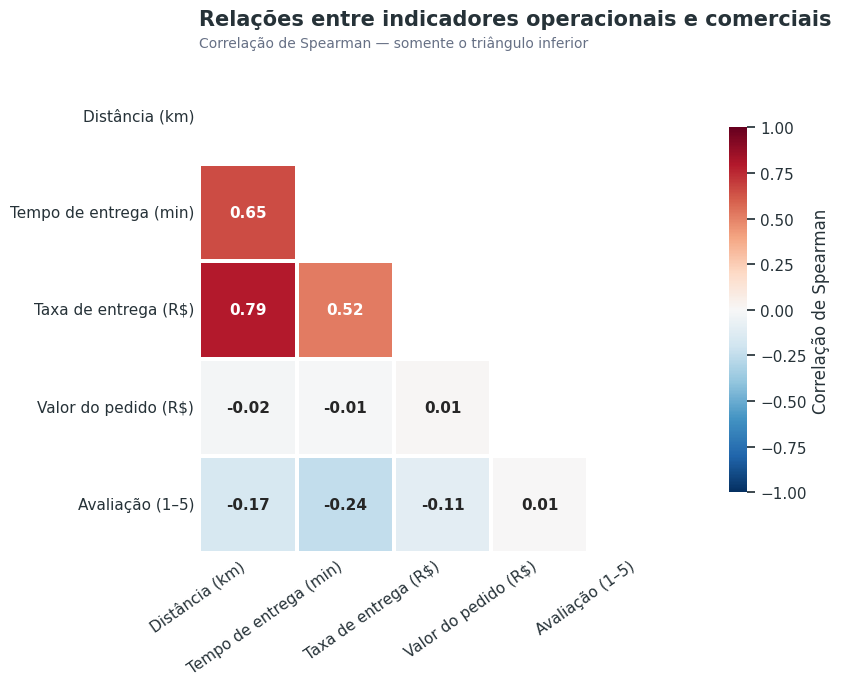


CORRELAÇÕES ORDENADAS POR INTENSIDADE


,Variável 1,Variável 2,Spearman
1,taxa_entrega,distancia_km,0.789
0,tempo_entrega_min,distancia_km,0.653
2,taxa_entrega,tempo_entrega_min,0.522
7,avaliacao,tempo_entrega_min,-0.244
6,avaliacao,distancia_km,-0.168
8,avaliacao,taxa_entrega,-0.109
3,valor_pedido,distancia_km,-0.017
5,valor_pedido,taxa_entrega,0.015
4,valor_pedido,tempo_entrega_min,-0.009
9,avaliacao,valor_pedido,0.005



Registros totais: 8058
Registros completos nas cinco variáveis: 6410

Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. SELECIONAR AS VARIÁVEIS
# ============================================================

variaveis = [
    'distancia_km',
    'tempo_entrega_min',
    'taxa_entrega',
    'valor_pedido',
    'avaliacao'
]

dados_corr = df[variaveis].copy()

# ============================================================
# 2. CALCULAR AS MATRIZES
# ============================================================

# Por padrão, o pandas utiliza os pares de valores válidos
# disponíveis para cada combinação de variáveis.

corr_pearson = dados_corr.corr(method='pearson')

corr_spearman = dados_corr.corr(method='spearman')

print("MATRIZ DE CORRELAÇÃO — PEARSON")
display(corr_pearson.round(3))

print("\nMATRIZ DE CORRELAÇÃO — SPEARMAN")
display(corr_spearman.round(3))

# ============================================================
# 3. CRIAR HEATMAP — SPEARMAN
# ============================================================

# Máscara para esconder diagonal e triângulo superior
mascara = np.triu(
    np.ones_like(corr_spearman, dtype=bool),
    k=0
)

# Nomes mais amigáveis
nomes = [
    'Distância (km)',
    'Tempo de entrega (min)',
    'Taxa de entrega (R$)',
    'Valor do pedido (R$)',
    'Avaliação (1–5)'
]

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    corr_spearman,
    mask=mascara,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1.5,
    linecolor='white',
    cbar_kws={
        'label': 'Correlação de Spearman',
        'shrink': 0.75
    },
    xticklabels=nomes,
    yticklabels=nomes,
    annot_kws={
        'fontsize': 11,
        'fontweight': 'bold'
    },
    ax=ax
)

titulo_grafico(
    ax,
    'Relações entre indicadores operacionais e comerciais',
    'Correlação de Spearman — somente o triângulo inferior'
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=35,
    ha='right'
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

ax.set_xlabel('')
ax.set_ylabel('')

ax.tick_params(axis='both', length=0)

plt.tight_layout()
plt.show()

# ============================================================
# 4. IDENTIFICAR AS CORRELAÇÕES MAIS FORTES
# ============================================================

# Extrair somente pares únicos, sem diagonal
triangulo_inferior = np.tril(
    np.ones(corr_spearman.shape, dtype=bool),
    k=-1
)

pares = (
    corr_spearman
    .where(triangulo_inferior)
    .stack()
    .reset_index()
)

pares.columns = [
    'Variável 1',
    'Variável 2',
    'Spearman'
]

pares['Força absoluta'] = pares['Spearman'].abs()

pares = pares.sort_values(
    'Força absoluta',
    ascending=False
)

print("\nCORRELAÇÕES ORDENADAS POR INTENSIDADE")

display(
    pares[
        ['Variável 1', 'Variável 2', 'Spearman']
    ].round(3)
)

# ============================================================
# 5. VALIDAÇÃO
# ============================================================

assert corr_pearson.shape == (5, 5)
assert corr_spearman.shape == (5, 5)

assert np.allclose(
    corr_pearson,
    corr_pearson.T,
    equal_nan=True
)

assert np.allclose(
    corr_spearman,
    corr_spearman.T,
    equal_nan=True
)

print("\nRegistros totais:", len(dados_corr))

print(
    "Registros completos nas cinco variáveis:",
    dados_corr.dropna().shape[0]
)

print("\nValidação concluída!")

*Sua resposta aqui*


Foram calculadas as matrizes de correlação de **Pearson** e **Spearman** entre distância, tempo de entrega, taxa de entrega, valor do pedido e avaliação dos clientes.

O heatmap da matriz de Spearman utiliza uma escala divergente centrada em zero e apresenta apenas o triângulo inferior, evitando a duplicação de informações.

**Principais resultados:**

1. **Distância × taxa de entrega:** Pearson = +0,578 e Spearman = +0,789. A correlação monotônica é mais forte que a linear, indicando que taxas de entrega tendem a aumentar com a distância, embora essa relação não seja necessariamente linear.

2. **Distância × tempo de entrega:** Pearson = +0,704 e Spearman = +0,653. Ambos os métodos indicam uma associação positiva expressiva, evidenciando que entregas mais distantes tendem a exigir mais tempo.

3. **Tempo de entrega × taxa de entrega:** Pearson = +0,418 e Spearman = +0,522. A associação positiva indica que entregas mais demoradas também tendem a apresentar taxas maiores.

4. **Tempo de entrega × avaliação:** Pearson = −0,287 e Spearman = −0,244. Ambos apontam uma associação negativa, indicando que avaliações menores tendem a acompanhar tempos de entrega mais elevados.

5. **Valor do pedido:** apresentou correlações próximas de zero com os demais indicadores, tanto em Pearson quanto em Spearman, sugerindo ausência de associações lineares ou monotônicas relevantes.

**Conclusão:** os indicadores operacionais de distância, tempo e taxa de entrega apresentam associações positivas consistentes. O tempo de entrega também se relaciona negativamente com a satisfação dos clientes. A diferença entre Pearson e Spearman é especialmente relevante na relação entre distância e taxa de entrega, sugerindo que a associação pode não seguir um padrão estritamente linear.

**Observações metodológicas:** as correlações foram calculadas com exclusão de valores ausentes por par de variáveis, preservando os 8.058 registros originais. Desses, 6.410 apresentam informações completas nas cinco variáveis simultaneamente. As correlações não demonstram causalidade, e as diferenças entre os métodos não comprovam, isoladamente, a existência de não linearidade ou o efeito de valores extremos.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

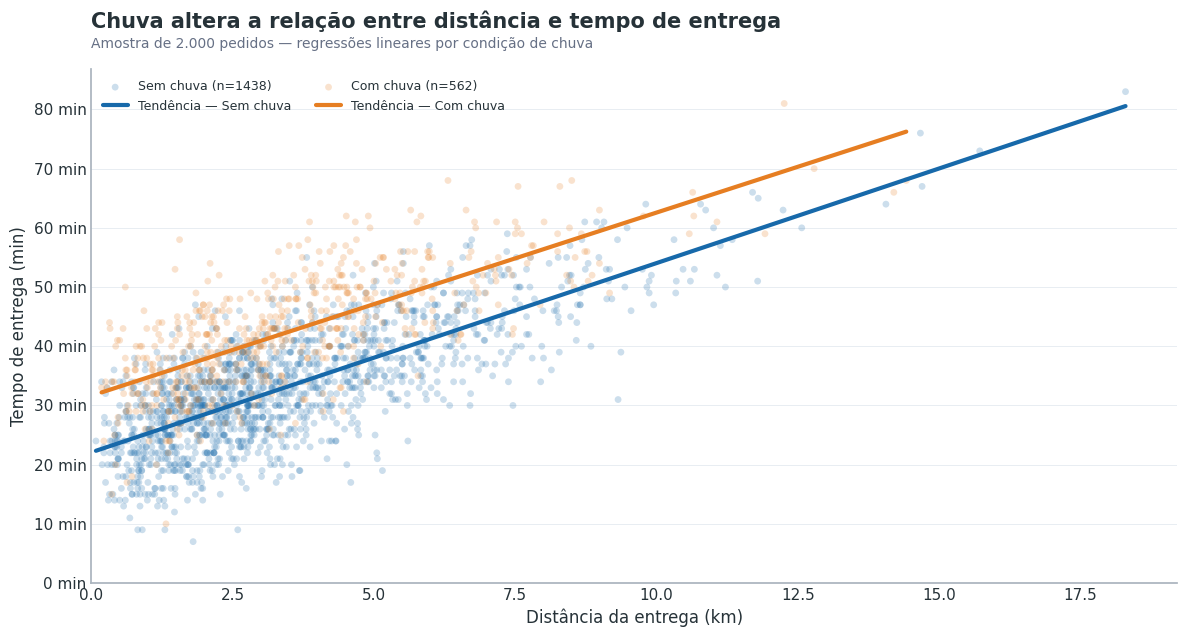

REGRESSÕES LINEARES POR CONDIÇÃO DE CHUVA


,Condição,Pedidos,Inclinação (min/km),Intercepto (min),Pearson,Tempo médio (min)
0,Sem chuva,1438,3.195,22.090,0.758,33.186
1,Com chuva,562,3.093,31.648,0.724,42.740



COMPARAÇÃO DAS RETAS
Diferença de inclinação: -0.102 min/km
Diferença de intercepto: +9.558 min

Distância de 2 km:
  Sem chuva: 28.48 min
  Com chuva: 37.83 min
  Diferença: +9.35 min

Distância de 5 km:
  Sem chuva: 38.07 min
  Com chuva: 47.11 min
  Diferença: +9.05 min

Distância de 8 km:
  Sem chuva: 47.65 min
  Com chuva: 56.39 min
  Diferença: +8.74 min

Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

dados = df[
    ['distancia_km', 'tempo_entrega_min', 'chuva']
].dropna().copy()

# Padronizar a condição de chuva
mapa_chuva = {
    True: 'Com chuva',
    False: 'Sem chuva',
    'Sim': 'Com chuva',
    'Não': 'Sem chuva',
    'sim': 'Com chuva',
    'não': 'Sem chuva',
    'True': 'Com chuva',
    'False': 'Sem chuva'
}

dados['condicao_chuva'] = dados['chuva'].map(mapa_chuva)

assert dados['condicao_chuva'].notna().all(), (
    'Existem valores de chuva não reconhecidos.'
)

# Amostra reprodutível de 2.000 pedidos
amostra = dados.sample(
    n=2000,
    random_state=42
)

# ============================================================
# 2. CRIAR GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6.5))

grupos = [
    ('Sem chuva', CORES['sem_chuva']),
    ('Com chuva', CORES['com_chuva'])
]

resultados = []

for nome, cor in grupos:

    grupo = amostra[
        amostra['condicao_chuva'] == nome
    ]

    # Pontos com transparência
    ax.scatter(
        grupo['distancia_km'],
        grupo['tempo_entrega_min'],
        color=cor,
        alpha=0.22,
        s=24,
        edgecolors='none',
        label=f'{nome} (n={len(grupo)})',
        zorder=2
    )

    # Ajuste da regressão linear
    inclinacao, intercepto = np.polyfit(
        grupo['distancia_km'],
        grupo['tempo_entrega_min'],
        deg=1
    )

    # Desenhar reta somente no intervalo observado
    x_reta = np.linspace(
        grupo['distancia_km'].min(),
        grupo['distancia_km'].max(),
        100
    )

    y_reta = intercepto + inclinacao * x_reta

    ax.plot(
        x_reta,
        y_reta,
        color=cor,
        linewidth=3,
        label=f'Tendência — {nome}',
        zorder=4
    )

    correlacao = grupo[
        ['distancia_km', 'tempo_entrega_min']
    ].corr(method='pearson').iloc[0, 1]

    resultados.append({
        'Condição': nome,
        'Pedidos': len(grupo),
        'Inclinação (min/km)': inclinacao,
        'Intercepto (min)': intercepto,
        'Pearson': correlacao,
        'Tempo médio (min)': grupo['tempo_entrega_min'].mean()
    })

# ============================================================
# 3. FORMATAR O GRÁFICO
# ============================================================

titulo_grafico(
    ax,
    'Chuva altera a relação entre distância e tempo de entrega',
    'Amostra de 2.000 pedidos — regressões lineares por condição de chuva'
)

ax.set_xlabel('Distância da entrega (km)')
ax.set_ylabel('Tempo de entrega (min)')

ax.yaxis.set_major_formatter(fmt_minutos)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.legend(
    frameon=False,
    loc='upper left',
    fontsize=9,
    ncol=2
)

limpar_grafico(ax, grade=True)

plt.tight_layout()
plt.show()

# ============================================================
# 4. RESULTADOS DAS RETAS
# ============================================================

resumo = pd.DataFrame(resultados)

print("REGRESSÕES LINEARES POR CONDIÇÃO DE CHUVA")

display(resumo.round(3))

sem = resumo.loc[
    resumo['Condição'] == 'Sem chuva'
].iloc[0]

com = resumo.loc[
    resumo['Condição'] == 'Com chuva'
].iloc[0]

diferenca_inclinacao = (
    com['Inclinação (min/km)']
    - sem['Inclinação (min/km)']
)

diferenca_intercepto = (
    com['Intercepto (min)']
    - sem['Intercepto (min)']
)

print("\nCOMPARAÇÃO DAS RETAS")

print(
    f"Diferença de inclinação: "
    f"{diferenca_inclinacao:+.3f} min/km"
)

print(
    f"Diferença de intercepto: "
    f"{diferenca_intercepto:+.3f} min"
)

# Comparar tempos previstos na mesma distância
for km in [2, 5, 8]:

    previsao_sem = (
        sem['Intercepto (min)']
        + sem['Inclinação (min/km)'] * km
    )

    previsao_com = (
        com['Intercepto (min)']
        + com['Inclinação (min/km)'] * km
    )

    print(
        f"\nDistância de {km} km:"
        f"\n  Sem chuva: {previsao_sem:.2f} min"
        f"\n  Com chuva: {previsao_com:.2f} min"
        f"\n  Diferença: {previsao_com - previsao_sem:+.2f} min"
    )

# ============================================================
# 5. VALIDAÇÃO
# ============================================================

assert len(amostra) == 2000
assert amostra['condicao_chuva'].nunique() == 2

print("\nValidação concluída!")


*Sua resposta aqui*


O gráfico de dispersão apresenta a relação entre distância e tempo de entrega, comparando **2.000 pedidos**, sendo 1.438 sem chuva e 562 com chuva.

Os resultados mostram que, quanto maior a distância, maior tende a ser o tempo de entrega. A cada quilômetro adicional, o tempo aumenta aproximadamente **3,20 minutos sem chuva** e **3,09 minutos com chuva**.

A chuva **desloca a reta de tendência para cima, mantendo praticamente a mesma inclinação**. Isso significa que, para uma mesma distância, as entregas com chuva demoram aproximadamente **9 minutos a mais**. Por exemplo, em uma entrega de 5 km, o tempo previsto passa de 38,07 minutos sem chuva para 47,11 minutos com chuva.

**Conclusão:** a distância influencia o tempo de entrega, mas as condições de chuva também estão associadas a atrasos. Esses resultados podem ajudar o aplicativo a melhorar suas previsões de entrega, especialmente em dias chuvosos.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

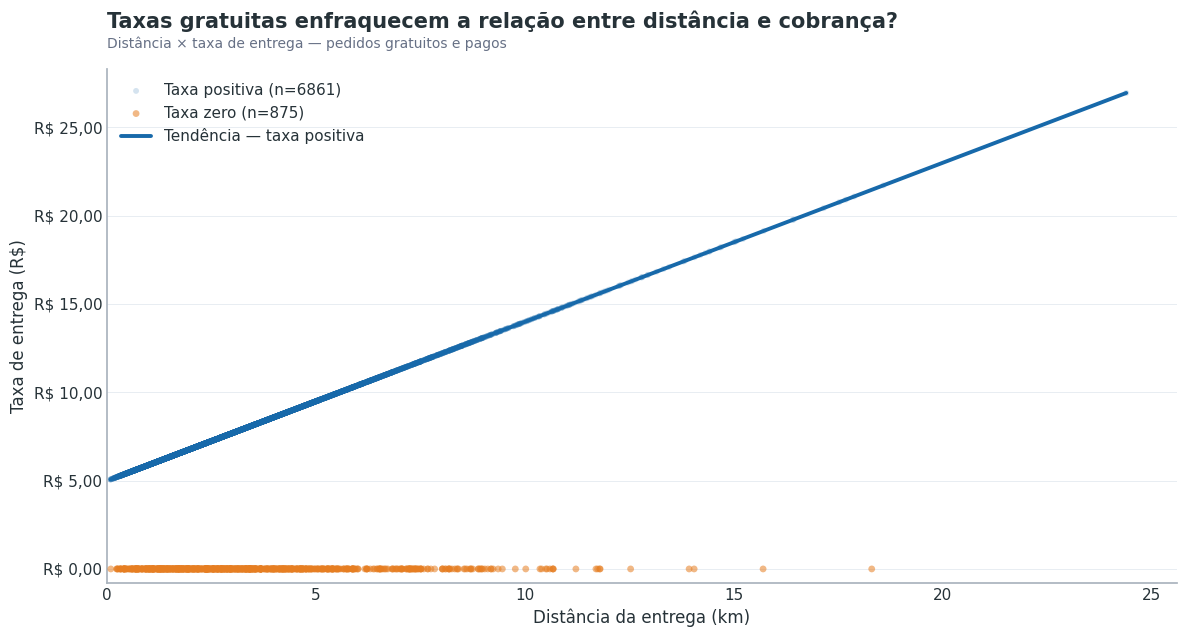

CORRELAÇÃO ENTRE DISTÂNCIA E TAXA DE ENTREGA


,Grupo,Quantidade,Pearson,Spearman
0,Todos os pedidos,7736,0.578,0.789
1,Taxa positiva,6861,1.000,1.000
2,Taxa zero,875,NaN,NaN



MODELO LINEAR — PEDIDOS COM TAXA POSITIVA
Taxa estimada = 0.900 × distância + 4.990

DISTÂNCIAS AUSENTES
Total de distâncias ausentes: 322

Distribuição por condição da taxa:


,Condição,Pedidos
0,Taxa zero,25
1,Taxa positiva,297



ESTATÍSTICAS DAS TAXAS COM DISTÂNCIA AUSENTE


,taxa_entrega
count,322.00
mean,7.73
std,3.29
min,0.00
25%,6.17
50%,7.78
75%,9.23
max,23.90



Validação concluída!


In [ ]:
# Sua solução aqui

# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

dados = df[
    ['distancia_km', 'taxa_entrega']
].dropna().copy()

dados['tipo_taxa'] = np.where(
    dados['taxa_entrega'] == 0,
    'Taxa zero',
    'Taxa positiva'
)

gratuitos = dados[dados['taxa_entrega'] == 0]
pagos = dados[dados['taxa_entrega'] > 0]

# ============================================================
# 2. CALCULAR CORRELAÇÕES
# ============================================================

pearson_geral = dados['distancia_km'].corr(
    dados['taxa_entrega'],
    method='pearson'
)

spearman_geral = dados['distancia_km'].corr(
    dados['taxa_entrega'],
    method='spearman'
)

pearson_pagos = pagos['distancia_km'].corr(
    pagos['taxa_entrega'],
    method='pearson'
)

spearman_pagos = pagos['distancia_km'].corr(
    pagos['taxa_entrega'],
    method='spearman'
)

# Não é possível calcular correlação no grupo de taxa zero,
# pois todos os valores de taxa_entrega são iguais a zero.

# ============================================================
# 3. GRÁFICO DE DISPERSÃO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6.5))

# Pedidos com taxa positiva
ax.scatter(
    pagos['distancia_km'],
    pagos['taxa_entrega'],
    color=CORES['principal'],
    alpha=0.18,
    s=18,
    edgecolors='none',
    label=f'Taxa positiva (n={len(pagos)})'
)

# Pedidos com taxa zero
ax.scatter(
    gratuitos['distancia_km'],
    gratuitos['taxa_entrega'],
    color=CORES['destaque'],
    alpha=0.55,
    s=24,
    edgecolors='none',
    label=f'Taxa zero (n={len(gratuitos)})',
    zorder=3
)

# Reta de tendência apenas para pedidos pagos
coef = np.polyfit(
    pagos['distancia_km'],
    pagos['taxa_entrega'],
    1
)

x_reta = np.linspace(
    pagos['distancia_km'].min(),
    pagos['distancia_km'].max(),
    200
)

y_reta = np.polyval(coef, x_reta)

ax.plot(
    x_reta,
    y_reta,
    color=CORES['principal'],
    linewidth=2.8,
    label='Tendência — taxa positiva'
)

# ============================================================
# 4. FORMATAÇÃO
# ============================================================

titulo_grafico(
    ax,
    'Taxas gratuitas enfraquecem a relação entre distância e cobrança?',
    'Distância × taxa de entrega — pedidos gratuitos e pagos'
)

ax.set_xlabel('Distância da entrega (km)')
ax.set_ylabel('Taxa de entrega (R$)')

ax.yaxis.set_major_formatter(fmt_reais)

ax.set_xlim(left=0)
ax.set_ylim(bottom=-0.8)

ax.legend(
    frameon=False,
    loc='upper left'
)

limpar_grafico(ax, grade=True)

plt.tight_layout()
plt.show()

# ============================================================
# 5. COMPARAR RESULTADOS
# ============================================================

print("CORRELAÇÃO ENTRE DISTÂNCIA E TAXA DE ENTREGA")

resumo = pd.DataFrame({
    'Grupo': [
        'Todos os pedidos',
        'Taxa positiva',
        'Taxa zero'
    ],
    'Quantidade': [
        len(dados),
        len(pagos),
        len(gratuitos)
    ],
    'Pearson': [
        pearson_geral,
        pearson_pagos,
        np.nan
    ],
    'Spearman': [
        spearman_geral,
        spearman_pagos,
        np.nan
    ]
})

display(resumo.round(3))

print("\nMODELO LINEAR — PEDIDOS COM TAXA POSITIVA")

print(f"Taxa estimada = {coef[0]:.3f} × distância + {coef[1]:.3f}")

# ============================================================
# 6. INVESTIGAR DISTÂNCIAS AUSENTES
# ============================================================

faltantes = df[df['distancia_km'].isna()].copy()

print("\nDISTÂNCIAS AUSENTES")

print(f"Total de distâncias ausentes: {len(faltantes)}")

print("\nDistribuição por condição da taxa:")

display(
    pd.DataFrame({
        'Condição': [
            'Taxa zero',
            'Taxa positiva'
        ],
        'Pedidos': [
            (faltantes['taxa_entrega'] == 0).sum(),
            (faltantes['taxa_entrega'] > 0).sum()
        ]
    })
)

print("\nESTATÍSTICAS DAS TAXAS COM DISTÂNCIA AUSENTE")

display(
    faltantes['taxa_entrega'].describe().round(2)
)

# ============================================================
# 7. VALIDAÇÃO
# ============================================================

assert len(dados) == len(pagos) + len(gratuitos)

assert len(faltantes) + len(dados) == len(df)

print("\nValidação concluída!")


*Sua resposta aqui*

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

*Sua resposta aqui*


A correlação de Pearson entre distância e taxa de entrega foi de **0,578** quando considerados todos os 7.736 pedidos com distância válida.

O gráfico revelou que os **875 pedidos com taxa zero** enfraquecem essa correlação, pois apresentam diferentes distâncias, mas nenhuma cobrança.

Ao considerar apenas os **6.861 pedidos com taxa positiva**, as correlações de Pearson e Spearman aumentaram para **1,000**, indicando uma relação praticamente perfeita entre distância e taxa cobrada.

A fórmula encontrada foi:

**Taxa de entrega ≈ 4,990 + 0,900 × distância (km)**

Isso indica que a cobrança segue aproximadamente uma taxa fixa de R\$ 4,99, acrescida de R\$ 0,90 por quilômetro.

**Tratamento das distâncias ausentes:** foram identificados 322 pedidos sem distância válida. Desses, **297 possuem taxa positiva** e poderiam ter suas distâncias estimadas pela fórmula inversa:

**Distância ≈ (Taxa de entrega − 4,990) / 0,900**

Os outros 25 pedidos possuem taxa zero e não podem ter suas distâncias recuperadas por essa relação.

**Conclusão:** a correlação inicialmente moderada ocorre principalmente pela presença de entregas gratuitas. Ao separar esses pedidos, identificamos uma relação praticamente perfeita entre distância e taxa de entrega, que pode ser utilizada para estimar parte das distâncias ausentes, após validar a precisão das estimativas.

**Observação:** nenhuma distância ausente foi preenchida nesta etapa. A correlação de 1,000 está arredondada e não garante ausência total de erros nas estimativas.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [ ]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.1 — CHUVA × TEMPO DE ENTREGA
# ============================================================

# 1. Preparar os dados
dados = df[
    ['chuva', 'tempo_entrega_min']
].dropna().copy()

# Padronizar chuva para booleano
mapa_chuva = {
    True: True,
    False: False,
    'Sim': True,
    'Não': False,
    'sim': True,
    'não': False,
    'true': True,
    'false': False
}

dados['chuva_bool'] = dados['chuva'].map(
    lambda x: mapa_chuva.get(x, mapa_chuva.get(str(x).strip().lower()))
)

assert dados['chuva_bool'].notna().all(), (
    'Existem valores de chuva não reconhecidos.'
)

sem_chuva = dados.loc[
    dados['chuva_bool'] == False,
    'tempo_entrega_min'
]

com_chuva = dados.loc[
    dados['chuva_bool'] == True,
    'tempo_entrega_min'
]

# 2. Estatísticas descritivas
media_sem = sem_chuva.mean()
media_com = com_chuva.mean()

diferenca_min = media_com - media_sem
diferenca_pct = diferenca_min / media_sem * 100

# 3. Teste t de Welch unilateral
teste = stats.ttest_ind(
    com_chuva,
    sem_chuva,
    equal_var=False,
    alternative='greater'
)

estatistica = teste.statistic
p_valor = teste.pvalue

# 4. Tamanho de efeito — d de Cohen
n_com = len(com_chuva)
n_sem = len(sem_chuva)

var_com = com_chuva.var(ddof=1)
var_sem = sem_chuva.var(ddof=1)

desvio_agrupado = np.sqrt(
    (
        (n_com - 1) * var_com
        + (n_sem - 1) * var_sem
    )
    / (n_com + n_sem - 2)
)

d_cohen = diferenca_min / desvio_agrupado

# 5. Decisão
decisao = (
    'Rejeitar H0'
    if p_valor < ALFA
    else 'Não rejeitar H0'
)

# 6. Exibir resultados
print("TAREFA 9.1 — CHUVA × TEMPO DE ENTREGA")
print("-" * 48)

print(f"Entregas válidas sem chuva: {n_sem}")
print(f"Entregas válidas com chuva: {n_com}")

print(f"\nMédia sem chuva: {media_sem:.2f} min")
print(f"Média com chuva: {media_com:.2f} min")

print(f"\nDiferença: {diferenca_min:+.2f} min")
print(f"Diferença percentual: {diferenca_pct:+.2f}%")

print(f"\nTeste: t de Welch (unilateral)")
print(f"Estatística t: {estatistica:.4f}")
print(f"p-valor: {p_valor:.6e}")
print(f"d de Cohen: {d_cohen:.4f}")

print(f"\nDecisão (alfa = {ALFA}): {decisao}")

# 7. Registrar no quadro geral
resultados.append({
    'hipotese': 'H1 — Chuva × tempo de entrega',
    'teste': 't de Welch unilateral',
    'estatistica': float(estatistica),
    'p_valor': float(p_valor),
    'efeito': (
        f'{diferenca_min:+.2f} min '
        f'({diferenca_pct:+.2f}%); '
        f'd de Cohen = {d_cohen:.3f}'
    ),
    'decisao': decisao
})

# 8. Validação
assert n_sem + n_com == 8025
assert len(resultados) >= 1

print("\nHipótese adicionada à lista resultados.")
print("Validação concluída!")


TAREFA 9.1 — CHUVA × TEMPO DE ENTREGA
------------------------------------------------
Entregas válidas sem chuva: 5667
Entregas válidas com chuva: 2358

Média sem chuva: 33.23 min
Média com chuva: 42.36 min

Diferença: +9.13 min
Diferença percentual: +27.48%

Teste: t de Welch (unilateral)
Estatística t: 36.1597
p-valor: 3.231236e-251
d de Cohen: 0.8870

Decisão (alfa = 0.05): Rejeitar H0

Hipótese adicionada à lista resultados.
Validação concluída!


*Sua resposta aqui*

**Hipóteses:**
- **H₀:** o tempo médio de entrega com chuva é igual ou menor que sem chuva.
- **H₁:** o tempo médio de entrega com chuva é maior que sem chuva.

**Teste utilizado:** t de Welch unilateral, adequado para comparar as médias de dois grupos independentes.

**Resultados:**
- Sem chuva: **33,23 minutos** (5.667 entregas).
- Com chuva: **42,36 minutos** (2.358 entregas).
- Estatística t: **36,1597**.
- p-valor: **3,23 × 10⁻²⁵¹** (menor que 0,05).
- Tamanho de efeito: **+9,13 minutos (+27,48%)**.
- d de Cohen: **0,887**, considerado um efeito grande.

**Decisão:** rejeitamos H₀ ao nível de significância de 5%. Há evidências estatísticas de que as entregas com chuva apresentam maior tempo médio.

**Conclusão de negócio:** em dias chuvosos, as entregas demoram, em média, **9,13 minutos a mais**. Esse aumento é relevante para o aplicativo e deve ser considerado nas previsões de entrega e no planejamento operacional.

*Observação:* o teste identifica uma diferença entre os grupos, mas não comprova, isoladamente, que a chuva seja a única causa do atraso.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.2 — CUPOM × TICKET
# ============================================================

# 1. Preparar os dados
dados = df[['cupom', 'valor_pedido']].dropna().copy()

# A coluna cupom já foi convertida para booleano
assert dados['cupom'].isin([True, False]).all(), (
    'A coluna cupom deve conter apenas True e False.'
)

com_cupom = dados.loc[
    dados['cupom'] == True, 'valor_pedido'
]

sem_cupom = dados.loc[
    dados['cupom'] == False, 'valor_pedido'
]

assert (dados['valor_pedido'] > 0).all()

# ============================================================
# 2. ESTATÍSTICAS DESCRITIVAS
# ============================================================

media_com = com_cupom.mean()
media_sem = sem_cupom.mean()

mediana_com = com_cupom.median()
mediana_sem = sem_cupom.median()

dif_media = media_com - media_sem
dif_mediana = mediana_com - mediana_sem

dif_media_pct = dif_media / media_sem * 100
dif_mediana_pct = dif_mediana / mediana_sem * 100

# ============================================================
# 3. TESTE T DE WELCH — VALORES BRUTOS
# ============================================================

teste_welch = stats.ttest_ind(
    com_cupom,
    sem_cupom,
    equal_var=False,
    alternative='two-sided'
)

# ============================================================
# 4. TESTE DE MANN-WHITNEY
# ============================================================

teste_mw = stats.mannwhitneyu(
    com_cupom,
    sem_cupom,
    alternative='two-sided'
)

# Tamanho de efeito: correlação bisserial de postos
n_com = len(com_cupom)
n_sem = len(sem_cupom)

efeito_postos = (
    2 * teste_mw.statistic / (n_com * n_sem) - 1
)

# ============================================================
# 5. WELCH COM TRANSFORMAÇÃO LOGARÍTMICA
# ============================================================

log_com = np.log1p(com_cupom)
log_sem = np.log1p(sem_cupom)

teste_log = stats.ttest_ind(
    log_com,
    log_sem,
    equal_var=False,
    alternative='two-sided'
)

# ============================================================
# 6. COMPARAR RESULTADOS
# ============================================================

print("TAREFA 9.2 — CUPOM × TICKET")
print("-" * 50)

print(f"Pedidos sem cupom: {n_sem}")
print(f"Pedidos com cupom: {n_com}")

print("\nVALORES MÉDIOS")
print(f"Sem cupom: R$ {media_sem:.2f}")
print(f"Com cupom: R$ {media_com:.2f}")
print(f"Diferença: R$ {dif_media:+.2f} ({dif_media_pct:+.2f}%)")

print("\nMEDIANAS")
print(f"Sem cupom: R$ {mediana_sem:.2f}")
print(f"Com cupom: R$ {mediana_com:.2f}")
print(
    f"Diferença: R$ {dif_mediana:+.2f} "
    f"({dif_mediana_pct:+.2f}%)"
)

print("\nTESTE T DE WELCH — VALOR BRUTO")
print(f"Estatística t: {teste_welch.statistic:.4f}")
print(f"p-valor: {teste_welch.pvalue:.6e}")

print("\nTESTE DE MANN-WHITNEY")
print(f"Estatística U: {teste_mw.statistic:.2f}")
print(f"p-valor: {teste_mw.pvalue:.6e}")
print(f"Efeito por postos: {efeito_postos:.4f}")

print("\nTESTE T DE WELCH — LOG1P")
print(f"Estatística t: {teste_log.statistic:.4f}")
print(f"p-valor: {teste_log.pvalue:.6e}")

# ============================================================
# 7. DECISÃO — TESTE PRINCIPAL
# ============================================================

# Mann-Whitney será o teste principal desta análise,
# com Welch bruto e log como verificações complementares.

decisao = (
    'Rejeitar H0'
    if teste_mw.pvalue < ALFA
    else 'Não rejeitar H0'
)

print(f"\nDECISÃO (alfa = {ALFA})")
print(f"Teste principal: Mann-Whitney")
print(f"Resultado: {decisao}")

# ============================================================
# 8. REGISTRAR NA LISTA DE RESULTADOS
# ============================================================

resultados.append({
    'hipotese': 'H2 — Cupom × ticket',
    'teste': 'Mann-Whitney bilateral',
    'estatistica': float(teste_mw.statistic),
    'p_valor': float(teste_mw.pvalue),
    'efeito': (
        f'Diferença de medianas: R$ {dif_mediana:+.2f} '
        f'({dif_mediana_pct:+.2f}%); '
        f'efeito por postos = {efeito_postos:.3f}'
    ),
    'decisao': decisao
})

# ============================================================
# 9. VALIDAÇÃO
# ============================================================

assert n_com + n_sem == len(dados)
assert len(dados) == 8058

print("\nHipótese adicionada à lista resultados.")
print("Validação concluída!")


TAREFA 9.2 — CUPOM × TICKET
--------------------------------------------------
Pedidos sem cupom: 6349
Pedidos com cupom: 1709

VALORES MÉDIOS
Sem cupom: R$ 72.61
Com cupom: R$ 67.64
Diferença: R$ -4.97 (-6.84%)

MEDIANAS
Sem cupom: R$ 62.82
Com cupom: R$ 57.22
Diferença: R$ -5.60 (-8.91%)

TESTE T DE WELCH — VALOR BRUTO
Estatística t: -2.8145
p-valor: 4.923803e-03

TESTE DE MANN-WHITNEY
Estatística U: 4777274.50
p-valor: 3.189118e-14
Efeito por postos: -0.1194

TESTE T DE WELCH — LOG1P
Estatística t: -7.2348
p-valor: 6.123500e-13

DECISÃO (alfa = 0.05)
Teste principal: Mann-Whitney
Resultado: Rejeitar H0

Hipótese adicionada à lista resultados.
Validação concluída!


*Sua resposta aqui*

**Hipóteses:**
- **H₀:** o valor médio dos pedidos é igual com e sem cupom.
- **H₁:** o valor médio dos pedidos é diferente entre os grupos.

**Testes utilizados:** Welch, Mann-Whitney e Welch com transformação logarítmica. O teste t sobre os valores brutos é menos confiável porque existem pedidos de valores muito elevados, que podem distorcer as médias. Por isso, utilizamos também testes menos sensíveis a esses valores extremos.

**Resultados:**
- Ticket médio sem cupom: **R\$ 72,61**.
- Ticket médio com cupom: **R\$ 67,64**.
- Diferença média: **−R\$ 4,97 (−6,84%)**.
- Diferença entre medianas: **−R\$ 5,60 (−8,91%)**.
- Welch: **t = −2,8145; p = 0,0049**.
- Mann-Whitney: **U = 4.777.274,50; p < 0,001**.
- Welch com log: **t = −7,2348; p < 0,001**.
- Tamanho de efeito por postos: **−0,1194**, considerado pequeno.

**Decisão:** rejeitamos H₀ ao nível de 5%. Os três testes apontam diferenças estatisticamente significativas entre os grupos.

**Conclusão de negócio:** os pedidos com cupom apresentam ticket médio aproximadamente **R\$ 4,97 menor**, uma redução de **6,84%**. Embora a diferença seja estatisticamente significativa, o efeito é pequeno e deve ser avaliado junto ao potencial dos cupons para atrair novos clientes e aumentar as vendas.

**Observação:** os resultados indicam associação entre o uso de cupom e o valor do pedido, mas não comprovam que o cupom seja a causa da redução.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.3 — TEMPO DE ENTREGA × AVALIAÇÃO
# ============================================================

# 1. Preparar os dados
dados = df[
    ['tempo_entrega_min', 'avaliacao']
].dropna().copy()

# Separar os grupos
ate_35 = dados.loc[
    dados['tempo_entrega_min'] <= 35,
    'avaliacao'
]

acima_35 = dados.loc[
    dados['tempo_entrega_min'] > 35,
    'avaliacao'
]

# ============================================================
# 2. CORRELAÇÃO DE SPEARMAN
# ============================================================

rho, p_spearman = stats.spearmanr(
    dados['tempo_entrega_min'],
    dados['avaliacao']
)

# ============================================================
# 3. TESTE DE MANN-WHITNEY
# ============================================================

teste_mw = stats.mannwhitneyu(
    ate_35,
    acima_35,
    alternative='two-sided'
)

# ============================================================
# 4. TAMANHO DE EFEITO
# ============================================================

n_ate = len(ate_35)
n_acima = len(acima_35)

media_ate = ate_35.mean()
media_acima = acima_35.mean()

mediana_ate = ate_35.median()
mediana_acima = acima_35.median()

dif_media = media_acima - media_ate

# Avaliações positivas: 4 ou 5 estrelas
positivas_ate = (ate_35 >= 4).mean() * 100
positivas_acima = (acima_35 >= 4).mean() * 100

dif_positivas = positivas_acima - positivas_ate

# Efeito por postos:
# positivo = avaliações tendem a ser maiores no grupo até 35 min
efeito_postos = (
    2 * teste_mw.statistic / (n_ate * n_acima) - 1
)

# ============================================================
# 5. DECISÕES
# ============================================================

decisao_spearman = (
    'Rejeitar H0'
    if p_spearman < ALFA
    else 'Não rejeitar H0'
)

decisao_mw = (
    'Rejeitar H0'
    if teste_mw.pvalue < ALFA
    else 'Não rejeitar H0'
)

# ============================================================
# 6. EXIBIR RESULTADOS
# ============================================================

print("TAREFA 9.3 — TEMPO DE ENTREGA × AVALIAÇÃO")
print("-" * 55)

print(f"Pedidos com tempo e avaliação válidos: {len(dados)}")

print("\nCORRELAÇÃO DE SPEARMAN")
print(f"Rho: {rho:.4f}")
print(f"p-valor: {p_spearman:.6e}")
print(f"Decisão: {decisao_spearman}")

print("\nCOMPARAÇÃO ENTRE GRUPOS")

resumo = pd.DataFrame({
    'Grupo': ['Até 35 min', 'Acima de 35 min'],
    'Quantidade': [n_ate, n_acima],
    'Média': [media_ate, media_acima],
    'Mediana': [mediana_ate, mediana_acima],
    'Avaliações 4–5 estrelas (%)': [
        positivas_ate,
        positivas_acima
    ]
})

display(resumo.round(2))

print(f"\nDiferença média (acima − até): {dif_media:+.3f} estrela(s)")
print(
    f"Diferença nas avaliações positivas: "
    f"{dif_positivas:+.2f} pontos percentuais"
)

print("\nTESTE DE MANN-WHITNEY")
print(f"Estatística U: {teste_mw.statistic:.2f}")
print(f"p-valor: {teste_mw.pvalue:.6e}")
print(f"Tamanho de efeito por postos: {efeito_postos:.4f}")
print(f"Decisão: {decisao_mw}")

# ============================================================
# 7. REGISTRAR NA LISTA DE RESULTADOS
# ============================================================

resultados.append({
    'hipotese': 'H3 — Tempo × avaliação',
    'teste': 'Spearman + Mann-Whitney',
    'estatistica': float(rho),
    'p_valor': float(p_spearman),
    'efeito': (
        f'rho = {rho:.3f}; '
        f'diferença média = {dif_media:+.3f} estrela(s); '
        f'avaliações positivas = {dif_positivas:+.2f} p.p.; '
        f'efeito por postos = {efeito_postos:.3f}'
    ),
    'decisao': decisao_spearman
})

# ============================================================
# 8. VALIDAÇÃO
# ============================================================

assert n_ate + n_acima == len(dados)
assert dados['avaliacao'].between(1, 5).all()

print("\nHipótese adicionada à lista resultados.")
print("Validação concluída!")

TAREFA 9.3 — TEMPO DE ENTREGA × AVALIAÇÃO
-------------------------------------------------------
Pedidos com tempo e avaliação válidos: 6685

CORRELAÇÃO DE SPEARMAN
Rho: -0.2444
p-valor: 1.550145e-91
Decisão: Rejeitar H0

COMPARAÇÃO ENTRE GRUPOS


,Grupo,Quantidade,Média,Mediana,Avaliações 4–5 estrelas (%)
0,Até 35 min,3426,4.49,5.0,93.49
1,Acima de 35 min,3259,4.20,4.0,84.57



Diferença média (acima − até): -0.285 estrela(s)
Diferença nas avaliações positivas: -8.93 pontos percentuais

TESTE DE MANN-WHITNEY
Estatística U: 6766415.50
p-valor: 1.263206e-61
Tamanho de efeito por postos: 0.2120
Decisão: Rejeitar H0

Hipótese adicionada à lista resultados.
Validação concluída!


*Sua resposta aqui*

**Hipóteses:**
- **H₀:** não existe associação entre tempo de entrega e avaliação, nem diferença entre os grupos.
- **H₁:** existe associação entre tempo de entrega e avaliação e/ou diferença entre os grupos.

**Testes utilizados:** correlação de Spearman, adequada para avaliações de 1 a 5 estrelas, e Mann-Whitney, para comparar os pedidos entregues até 35 minutos com os acima de 35 minutos.

**Resultados:**
- **Spearman:** ρ = −0,2444; p < 0,001, indicando associação negativa.
- **Até 35 minutos:** avaliação média de 4,49 estrelas e 93,49% de avaliações positivas.
- **Acima de 35 minutos:** avaliação média de 4,20 estrelas e 84,57% de avaliações positivas.
- **Diferença média:** −0,285 estrela.
- **Diferença nas avaliações positivas:** −8,93 pontos percentuais.
- **Mann-Whitney:** U = 6.766.415,50; p < 0,001.
- **Tamanho de efeito por postos:** 0,2120, indicando efeito pequeno.

**Decisão:** rejeitamos H₀ nos dois testes, ao nível de significância de 5%. Existe associação estatisticamente significativa entre maior tempo de entrega e avaliações menores, além de diferença entre os dois grupos.

**Conclusão de negócio:** pedidos entregues acima de 35 minutos apresentam uma redução de aproximadamente **9 pontos percentuais nas avaliações positivas**. Esse resultado reforça a importância de controlar os atrasos e melhorar a pontualidade para preservar a satisfação dos clientes.

**Observação:** os resultados mostram associação, mas não comprovam que o tempo de entrega seja a única causa das avaliações menores.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.4 — TIPO DE COZINHA × TICKET
# ============================================================

# 1. Preparar os dados
dados = df[
    ['tipo_cozinha', 'valor_pedido']
].dropna().copy()

# Separar os valores por tipo de cozinha
grupos = {
    cozinha: grupo['valor_pedido'].to_numpy()
    for cozinha, grupo in dados.groupby('tipo_cozinha')
}

valores_grupos = list(grupos.values())

n = len(dados)
k = len(grupos)

assert k > 2, "É necessário ter mais de dois grupos."

# ============================================================
# 2. ESTATÍSTICAS DESCRITIVAS
# ============================================================

resumo = (
    dados.groupby('tipo_cozinha')['valor_pedido']
    .agg(
        quantidade='count',
        media='mean',
        mediana='median',
        desvio_padrao='std'
    )
    .sort_values('mediana', ascending=False)
)

print("TAREFA 9.4 — TIPO DE COZINHA × TICKET")
print("-" * 55)

print(f"Total de pedidos: {n}")
print(f"Quantidade de tipos de cozinha: {k}")

print("\nRESUMO POR TIPO DE COZINHA")
display(resumo.round(2))

# ============================================================
# 3. TESTE DE KRUSKAL-WALLIS
# ============================================================

teste_kw = stats.kruskal(*valores_grupos)

# Tamanho de efeito: epsilon quadrado
epsilon2 = max(
    0,
    (teste_kw.statistic - k + 1) / (n - k)
)

# ============================================================
# 4. ANOVA DE UMA VIA
# ============================================================

teste_anova = stats.f_oneway(*valores_grupos)

# ============================================================
# 5. TAMANHO DE EFEITO DA ANOVA — ETA QUADRADO
# ============================================================

media_geral = dados['valor_pedido'].mean()

# Variação explicada pelas diferenças entre grupos
sq_entre = sum(
    len(valores) * (valores.mean() - media_geral) ** 2
    for valores in valores_grupos
)

# Variação total dos valores dos pedidos
sq_total = (
    (dados['valor_pedido'] - media_geral) ** 2
).sum()

eta2 = sq_entre / sq_total

# ============================================================
# 6. DIFERENÇA EM REAIS ENTRE AS MEDIANAS
# ============================================================

maior_mediana = resumo['mediana'].iloc[0]
menor_mediana = resumo['mediana'].iloc[-1]

cozinha_maior = resumo.index[0]
cozinha_menor = resumo.index[-1]

diferenca_reais = maior_mediana - menor_mediana

# ============================================================
# 7. DECISÃO
# ============================================================

decisao_kw = (
    'Rejeitar H0'
    if teste_kw.pvalue < ALFA
    else 'Não rejeitar H0'
)

decisao_anova = (
    'Rejeitar H0'
    if teste_anova.pvalue < ALFA
    else 'Não rejeitar H0'
)

# ============================================================
# 8. EXIBIR RESULTADOS
# ============================================================

print("\nTESTE DE KRUSKAL-WALLIS")
print(f"Estatística H: {teste_kw.statistic:.4f}")
print(f"p-valor: {teste_kw.pvalue:.6e}")
print(f"Epsilon quadrado: {epsilon2:.4f}")
print(f"Decisão: {decisao_kw}")

print("\nANOVA DE UMA VIA")
print(f"Estatística F: {teste_anova.statistic:.4f}")
print(f"p-valor: {teste_anova.pvalue:.6e}")
print(f"Eta quadrado (η²): {eta2:.4f}")
print(f"Decisão: {decisao_anova}")

print("\nDIFERENÇA ENTRE MEDIANAS")
print(f"Maior mediana: {cozinha_maior} — R$ {maior_mediana:.2f}")
print(f"Menor mediana: {cozinha_menor} — R$ {menor_mediana:.2f}")
print(f"Diferença: R$ {diferenca_reais:.2f}")

print(
    f"\nPercentual da variação associado ao tipo de cozinha "
    f"(η²): {eta2 * 100:.2f}%"
)

# ============================================================
# 9. REGISTRAR NA LISTA DE RESULTADOS
# ============================================================

resultados.append({
    'hipotese': 'H4 — Tipo de cozinha × ticket',
    'teste': 'Kruskal-Wallis + ANOVA',
    'estatistica': float(teste_kw.statistic),
    'p_valor': float(teste_kw.pvalue),
    'efeito': (
        f'epsilon² = {epsilon2:.3f}; '
        f'eta² = {eta2:.3f}; '
        f'diferença entre medianas = R$ {diferenca_reais:.2f}'
    ),
    'decisao': decisao_kw
})

# ============================================================
# 10. VALIDAÇÃO
# ============================================================

assert sum(len(g) for g in valores_grupos) == len(dados)
assert 0 <= eta2 <= 1

print("\nHipótese adicionada à lista resultados.")
print("Validação concluída!")


TAREFA 9.4 — TIPO DE COZINHA × TICKET
-------------------------------------------------------
Total de pedidos: 8058
Quantidade de tipos de cozinha: 6

RESUMO POR TIPO DE COZINHA


,quantidade,media,mediana,desvio_padrao
tipo_cozinha,,,,
Japonesa,1116,120.37,107.97,92.68
Pizza,1786,82.79,74.31,73.38
Hambúrguer,1921,67.65,61.67,40.13
Saudável,860,58.77,53.74,31.78
Brasileira,1561,51.17,47.82,27.55
Doces,814,41.79,38.42,24.99



TESTE DE KRUSKAL-WALLIS
Estatística H: 3272.5818
p-valor: 0.000000e+00
Epsilon quadrado: 0.4058
Decisão: Rejeitar H0

ANOVA DE UMA VIA
Estatística F: 286.8198
p-valor: 2.935781e-283
Eta quadrado (η²): 0.1512
Decisão: Rejeitar H0

DIFERENÇA ENTRE MEDIANAS
Maior mediana: Japonesa — R$ 107.97
Menor mediana: Doces — R$ 38.42
Diferença: R$ 69.55

Percentual da variação associado ao tipo de cozinha (η²): 15.12%

Hipótese adicionada à lista resultados.
Validação concluída!


*Sua resposta aqui*

**Hipóteses:**
- **H₀:** os valores dos pedidos não diferem entre os tipos de cozinha.
- **H₁:** pelo menos um tipo de cozinha apresenta valores diferentes.

**Testes utilizados:** Kruskal-Wallis, adequado para comparar mais de dois grupos com valores extremos, e ANOVA, para comparar os tickets médios.

**Resultados:**
- **Kruskal-Wallis:** H = 3.272,5818; p < 0,001.
- **Tamanho de efeito (ε²):** 0,4058, indicando diferença expressiva entre os grupos.
- **ANOVA:** F = 286,8198; p < 0,001.
- **Eta quadrado (η²):** 0,1512, indicando que aproximadamente **15,12% da variação dos valores dos pedidos** está associada ao tipo de cozinha.
- **Maior ticket mediano:** Japonesa — R\$ 107,97.
- **Menor ticket mediano:** Doces — R\$ 38,42.
- **Diferença entre medianas:** **R\$ 69,55**.

**Decisão:** rejeitamos H₀ ao nível de significância de 5% nos dois testes. Existem diferenças estatisticamente significativas entre os tipos de cozinha.

**Conclusão de negócio:** o tipo de cozinha está fortemente associado ao valor dos pedidos. A culinária japonesa apresenta o maior ticket mediano, enquanto a categoria Doces possui o menor. Essas diferenças são relevantes para estratégias de preços, promoções e segmentação de clientes.

**Observação:** os testes indicam que existem diferenças entre os grupos, mas não identificam individualmente todos os pares de cozinhas que apresentam diferenças significativas.

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [ ]:
# Sua solução aqui

from scipy.stats import chi2_contingency

# ============================================================
# TAREFA 9.5 — TESTES DE INDEPENDÊNCIA
# ============================================================

def teste_independencia(dados, coluna1, coluna2, titulo):

    # Tabela de frequências observadas
    tabela = pd.crosstab(
        dados[coluna1],
        dados[coluna2]
    )

    # Teste qui-quadrado de Pearson
    # Sem correção de Yates para manter o mesmo
    # procedimento nos dois testes
    chi2, p_valor, graus_liberdade, esperadas = (
        chi2_contingency(
            tabela,
            correction=False
        )
    )

    # Frequências esperadas
    tabela_esperadas = pd.DataFrame(
        esperadas,
        index=tabela.index,
        columns=tabela.columns
    )

    # V de Cramér
    n = tabela.to_numpy().sum()
    linhas, colunas = tabela.shape

    v_cramer = np.sqrt(
        chi2 / (n * min(linhas - 1, colunas - 1))
    )

    # Verificação das frequências esperadas
    qtd_abaixo_5 = (esperadas < 5).sum()
    menor_esperada = esperadas.min()

    # Decisão
    decisao = (
        'Rejeitar H0'
        if p_valor < ALFA
        else 'Não rejeitar H0'
    )

    print(f"\n{titulo}")
    print("=" * 60)

    print("\nFREQUÊNCIAS OBSERVADAS")
    display(tabela)

    print("\nFREQUÊNCIAS ESPERADAS")
    display(tabela_esperadas.round(2))

    print("\nRESULTADOS DO TESTE")
    print(f"Total de pedidos: {n}")
    print(f"Qui-quadrado: {chi2:.4f}")
    print(f"Graus de liberdade: {graus_liberdade}")
    print(f"p-valor: {p_valor:.6e}")
    print(f"V de Cramér: {v_cramer:.4f}")

    print("\nVERIFICAÇÃO DAS FREQUÊNCIAS ESPERADAS")
    print(f"Menor frequência esperada: {menor_esperada:.2f}")
    print(f"Células com frequência esperada < 5: {qtd_abaixo_5}")

    print(f"\nDecisão (alfa = {ALFA}): {decisao}")

    return {
        'chi2': chi2,
        'p_valor': p_valor,
        'graus_liberdade': graus_liberdade,
        'v_cramer': v_cramer,
        'decisao': decisao,
        'observadas': tabela,
        'esperadas': tabela_esperadas
    }


# ============================================================
# 1. H5 — FORMA DE PAGAMENTO × CIDADE
# ============================================================

dados_pagamento = df[
    ['cidade', 'forma_pagamento']
].dropna().copy()

h5 = teste_independencia(
    dados_pagamento,
    'cidade',
    'forma_pagamento',
    'H5 — FORMA DE PAGAMENTO × CIDADE'
)

# Percentuais por cidade
print("\nPERCENTUAL DAS FORMAS DE PAGAMENTO POR CIDADE")

percentuais_cidade = pd.crosstab(
    dados_pagamento['cidade'],
    dados_pagamento['forma_pagamento'],
    normalize='index'
) * 100

display(percentuais_cidade.round(2))


# ============================================================
# 2. CONTRASTE — CUPOM × CLIENTE NOVO
# ============================================================

dados_cupom = df[
    ['cupom', 'cliente_novo']
].dropna().copy()

# Padronizar para booleanos, caso necessário
mapa_bool = {
    True: True,
    False: False,
    'Sim': True,
    'Não': False,
    'sim': True,
    'não': False
}

for coluna in ['cupom', 'cliente_novo']:
    dados_cupom[coluna] = dados_cupom[coluna].map(
        lambda x: mapa_bool.get(
            x,
            mapa_bool.get(str(x).strip().lower())
        )
    )

assert dados_cupom.notna().all().all(), (
    'Existem valores não reconhecidos em cupom ou cliente_novo.'
)

contraste = teste_independencia(
    dados_cupom,
    'cupom',
    'cliente_novo',
    'CONTRASTE — CUPOM × CLIENTE NOVO'
)

# Percentual de clientes novos em cada grupo
print("\nPERCENTUAL DE CLIENTES NOVOS POR USO DE CUPOM")

taxa_novos = (
    dados_cupom.groupby('cupom')['cliente_novo']
    .mean() * 100
)

display(
    taxa_novos.rename(
        'Clientes novos (%)'
    ).round(2).to_frame()
)

diferenca_pp = taxa_novos.loc[True] - taxa_novos.loc[False]

print(
    f"\nDiferença na proporção de clientes novos: "
    f"{diferenca_pp:+.2f} pontos percentuais"
)


# ============================================================
# 3. REGISTRAR OS RESULTADOS
# ============================================================

resultados.append({
    'hipotese': 'H5 — Forma de pagamento × cidade',
    'teste': 'Qui-quadrado de independência',
    'estatistica': float(h5['chi2']),
    'p_valor': float(h5['p_valor']),
    'efeito': (
        f"V de Cramér = {h5['v_cramer']:.4f}"
    ),
    'decisao': h5['decisao']
})

resultados.append({
    'hipotese': 'Contraste — Cupom × cliente novo',
    'teste': 'Qui-quadrado de independência',
    'estatistica': float(contraste['chi2']),
    'p_valor': float(contraste['p_valor']),
    'efeito': (
        f"V de Cramér = {contraste['v_cramer']:.4f}; "
        f"diferença = {diferenca_pp:+.2f} p.p."
    ),
    'decisao': contraste['decisao']
})

# ============================================================
# 4. VALIDAÇÃO
# ============================================================

assert h5['observadas'].to_numpy().sum() == len(dados_pagamento)
assert contraste['observadas'].to_numpy().sum() == len(dados_cupom)

assert 0 <= h5['v_cramer'] <= 1
assert 0 <= contraste['v_cramer'] <= 1

print("\nDois testes adicionados à lista resultados.")
print("Validação concluída!")



H5 — FORMA DE PAGAMENTO × CIDADE

FREQUÊNCIAS OBSERVADAS


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,755,112,532,233
Rio de Janeiro,1078,163,785,345
São Paulo,1809,286,1316,644



FREQUÊNCIAS ESPERADAS


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.62,113.62,533.27,247.49
Rio de Janeiro,1071.63,165.07,774.74,359.56
São Paulo,1832.75,282.31,1325.00,614.94



RESULTADOS DO TESTE
Total de pedidos: 8058
Qui-quadrado: 3.8641
Graus de liberdade: 6
p-valor: 6.950622e-01
V de Cramér: 0.0155

VERIFICAÇÃO DAS FREQUÊNCIAS ESPERADAS
Menor frequência esperada: 113.62
Células com frequência esperada < 5: 0

Decisão (alfa = 0.05): Não rejeitar H0

PERCENTUAL DAS FORMAS DE PAGAMENTO POR CIDADE


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26,6.86,32.60,14.28
Rio de Janeiro,45.47,6.87,33.11,14.55
São Paulo,44.61,7.05,32.45,15.88


... (3 outputs left out)

cliente_novo,False,True
cupom,,
False,5245.92,1103.08
True,1412.08,296.92



RESULTADOS DO TESTE
Total de pedidos: 8058
Qui-quadrado: 435.3026
Graus de liberdade: 1
p-valor: 1.139732e-96
V de Cramér: 0.2324

VERIFICAÇÃO DAS FREQUÊNCIAS ESPERADAS
Menor frequência esperada: 296.92
Células com frequência esperada < 5: 0

Decisão (alfa = 0.05): Rejeitar H0

PERCENTUAL DE CLIENTES NOVOS POR USO DE CUPOM


,Clientes novos (%)
cupom,
False,12.81
True,34.35



Diferença na proporção de clientes novos: +21.54 pontos percentuais

Dois testes adicionados à lista resultados.
Validação concluída!


*Sua resposta aqui*


**Hipóteses:**
- **H₀:** a forma de pagamento e a cidade são independentes.
- **H₁:** existe associação entre a forma de pagamento e a cidade.

**Teste utilizado:** qui-quadrado de independência, com cálculo do V de Cramér para medir a intensidade da associação.

**Resultados:**
- Qui-quadrado: **χ² = 3,8641**.
- Graus de liberdade: **6**.
- p-valor: **0,6951**.
- V de Cramér: **0,0155**, indicando associação praticamente inexistente.
- Todas as frequências esperadas foram superiores a 5, atendendo ao critério de aplicação do teste.

**Decisão:** não rejeitamos H₀ ao nível de 5%. Não encontramos evidências estatísticas de associação entre cidade e forma de pagamento.

**Conclusão de negócio:** as preferências de pagamento são muito semelhantes em Belo Horizonte, Rio de Janeiro e São Paulo. Portanto, os dados não indicam necessidade de estratégias de pagamento diferentes para cada cidade.

---

### Teste de contraste — Cupom × cliente novo

**Hipóteses:**
- **H₀:** o uso de cupom e a condição de cliente novo são independentes.
- **H₁:** existe associação entre o uso de cupom e a condição de cliente novo.

**Resultados:**
- Qui-quadrado: **χ² = 435,3026**.
- Graus de liberdade: **1**.
- p-valor: **menor que 0,001**.
- V de Cramér: **0,2324**, indicando associação de intensidade moderada.
- Clientes novos sem cupom: **12,81%**.
- Clientes novos com cupom: **34,35%**.
- Diferença: **+21,54 pontos percentuais**.
- Todas as frequências esperadas foram superiores a 5.

**Decisão:** rejeitamos H₀ ao nível de 5%. Existe associação estatisticamente significativa entre o uso de cupom e a condição de cliente novo.

**Conclusão de negócio:** enquanto as formas de pagamento apresentam comportamento semelhante entre as cidades, os cupons estão associados a uma participação muito maior de clientes novos. Isso sugere que os cupons podem ser úteis em estratégias de aquisição de clientes.

**Observação:** a associação não comprova que os cupons sejam responsáveis pela entrada de novos clientes. Para avaliar seu impacto causal, seria necessário um estudo específico, como um experimento A/B.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.6 — H6: TEMPO DE ENTREGA ENTRE AS CIDADES
# Teste de Kruskal-Wallis
# ============================================================

from scipy.stats import kruskal


# 1. PREPARAÇÃO DOS DADOS
cidades_h6 = ['São Paulo', 'Rio de Janeiro', 'Belo Horizonte']

dados_h6 = df[
    ['cidade', 'tempo_entrega_min']
].dropna().copy()

dados_h6 = dados_h6[
    dados_h6['cidade'].isin(cidades_h6)
    & (dados_h6['tempo_entrega_min'] > 0)
]

print("TAREFA 9.6 — TEMPO DE ENTREGA ENTRE AS CIDADES")
print("-" * 60)
print(f"Pedidos válidos: {len(dados_h6)}")

# 2. ESTATÍSTICA DESCRITIVA
resumo_h6 = (
    dados_h6.groupby('cidade')['tempo_entrega_min']
    .agg(
        pedidos='count',
        media='mean',
        mediana='median',
        desvio_padrao='std'
    )
    .reindex(cidades_h6)
    .round(2)
)

print("\nRESUMO POR CIDADE")
display(resumo_h6)

# 3. TESTE DE KRUSKAL-WALLIS
grupos_h6 = [
    dados_h6.loc[
        dados_h6['cidade'] == cidade,
        'tempo_entrega_min'
    ].to_numpy()
    for cidade in cidades_h6
]

assert all(len(grupo) > 0 for grupo in grupos_h6), (
    "Uma das cidades não possui dados válidos."
)

estatistica_h6, p_valor_h6 = kruskal(*grupos_h6)

print("\nTESTE DE KRUSKAL-WALLIS")
print(f"Estatística H: {estatistica_h6:.4f}")
print(f"p-valor: {p_valor_h6:.6e}")

# 4. DECISÃO ESTATÍSTICA
ALFA = 0.05

decisao_h6 = (
    'Rejeitar H0'
    if p_valor_h6 < ALFA
    else 'Não rejeitar H0'
)

print("\nDECISÃO — H6")
print(f"Nível de significância: {ALFA}")
print(f"Decisão: {decisao_h6}")

if p_valor_h6 < ALFA:
    print(
        "Conclusão: existe diferença estatisticamente "
        "significativa entre pelo menos duas cidades."
    )
    print(
        "Será necessária uma comparação pós-teste "
        "para identificar quais cidades diferem."
    )
else:
    print(
        "Conclusão: não foram encontradas evidências "
        "estatísticas suficientes de diferença entre "
        "as distribuições dos tempos de entrega."
    )

# 5. RELEVÂNCIA PRÁTICA
amplitude_medias_h6 = (
    resumo_h6['media'].max() - resumo_h6['media'].min()
)

print("\nRELEVÂNCIA PRÁTICA")
print(
    f"Diferença entre a maior e a menor média: "
    f"{amplitude_medias_h6:.2f} minutos"
)

# 6. REGISTRO DOS RESULTADOS
# Remove eventual registro anterior da H6 para evitar duplicidade
resultados = [
    item for item in resultados
    if not str(item.get('hipotese', '')).startswith('H6')
]

resultados.append({
    'hipotese': 'H6 — Cidade × tempo de entrega',
    'teste': 'Kruskal-Wallis',
    'estatistica': float(estatistica_h6),
    'p_valor': float(p_valor_h6),
    'efeito': (
        f'Diferença entre médias extremas = '
        f'{amplitude_medias_h6:.2f} min'
    ),
    'decisao': decisao_h6
})

# 7. VALIDAÇÃO
assert len(dados_h6) > 0
assert np.isfinite(estatistica_h6)
assert np.isfinite(p_valor_h6)

print("\nHipótese H6 adicionada à lista resultados.")
print("Validação concluída!")



TAREFA 9.6 — TEMPO DE ENTREGA ENTRE AS CIDADES
------------------------------------------------------------
Pedidos válidos: 8025

RESUMO POR CIDADE


,pedidos,media,mediana,desvio_padrao
cidade,,,,
São Paulo,4039,35.86,35.0,11.25
Rio de Janeiro,2361,35.71,35.0,10.90
Belo Horizonte,1625,36.34,36.0,11.01



TESTE DE KRUSKAL-WALLIS
Estatística H: 3.3808
p-valor: 1.844430e-01

DECISÃO — H6
Nível de significância: 0.05
Decisão: Não rejeitar H0
Conclusão: não foram encontradas evidências estatísticas suficientes de diferença entre as distribuições dos tempos de entrega.

RELEVÂNCIA PRÁTICA
Diferença entre a maior e a menor média: 0.63 minutos

Hipótese H6 adicionada à lista resultados.
Validação concluída!


*Sua resposta aqui*


A hipótese H6 investigou se existem diferenças nos tempos de entrega entre São Paulo, Rio de Janeiro e Belo Horizonte, utilizando o teste não paramétrico de Kruskal-Wallis, com nível de significância de 5%.

Foram analisados 8.025 pedidos válidos. Os tempos médios de entrega foram de 35,86 minutos em São Paulo, 35,71 minutos no Rio de Janeiro e 36,34 minutos em Belo Horizonte.

O teste apresentou estatística H = 3,3808 e p-valor = 0,1844. Como p > 0,05, não rejeitamos a hipótese nula (H0).

Portanto, não foram encontradas evidências estatísticas suficientes para afirmar que as distribuições dos tempos de entrega diferem entre as três cidades.

Do ponto de vista operacional, a diferença entre a maior e a menor média foi de apenas 0,63 minuto, indicando tempos médios bastante próximos.

**Conclusão de negócio:** Os resultados não indicam diferenças relevantes nos tempos médios de entrega entre as cidades analisadas. Assim, fatores como chuva, distância percorrida e condições operacionais podem ser mais úteis para orientar melhorias logísticas.

**Limitação:** A comparação foi realizada sem controlar variáveis como chuva, distância e tipo de cozinha. Portanto, não permite concluir que as cidades tenham desempenho logístico equivalente em todas as condições.

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [ ]:
# Remover registros duplicados, mantendo a última versão
resultados = (
    pd.DataFrame(resultados)
    .drop_duplicates(subset=['hipotese'], keep='last')
    .to_dict('records')
)

# Conferir quantidade
print(f"Total de testes: {len(resultados)}")

assert len(resultados) == 7, "Verifique os registros duplicados."

print("Duplicidades removidas com sucesso!")

Total de testes: 7
Duplicidades removidas com sucesso!


In [ ]:
# Sua solução aqui

# ============================================================
# TAREFA 9.7 — TABELA-RESUMO DAS HIPÓTESES
# ============================================================

# 1. Converter a lista de resultados em DataFrame
resumo_hipoteses = pd.DataFrame(resultados).copy()

# 2. Função para formatar o p-valor
def formatar_p_valor(p):
    if pd.isna(p):
        return "Não disponível"
    elif p < 0.001:
        return "< 0,001"
    else:
        return f"{p:.4f}".replace(".", ",")

# 3. Organizar e renomear as colunas
tabela_readme = resumo_hipoteses[
    ['hipotese', 'teste', 'estatistica', 'p_valor',
     'efeito', 'decisao']
].copy()

tabela_readme['estatistica'] = (
    tabela_readme['estatistica']
    .map(lambda x: f"{x:.4f}".replace(".", ","))
)

tabela_readme['p_valor'] = (
    tabela_readme['p_valor']
    .map(formatar_p_valor)
)

tabela_readme['decisao'] = (
    tabela_readme['decisao']
    .replace({
        'Rejeitar H0': 'Rejeitar H₀',
        'Não rejeitar H0': 'Não rejeitar H₀'
    })
)

tabela_readme = tabela_readme.rename(columns={
    'hipotese': 'Hipótese',
    'teste': 'Teste estatístico',
    'estatistica': 'Estatística',
    'p_valor': 'p-valor',
    'efeito': 'Tamanho de efeito',
    'decisao': 'Decisão (5%)'
})

# 4. Exibir tabela organizada
print("TAREFA 9.7 — RESUMO DOS TESTES DE HIPÓTESES")
print("-" * 60)

display(tabela_readme)

# ============================================================
# 5. GERAR TABELA MARKDOWN PARA O README
# ============================================================

# Padronizar números decimais no tamanho de efeito
import re

def padronizar_decimais(texto):
    return re.sub(
        r'(?<!\d)(-?\d+)\.(\d+)',
        r'\1,\2',
        str(texto)
    )

tabela_readme['Tamanho de efeito'] = (
    tabela_readme['Tamanho de efeito']
    .apply(padronizar_decimais)
)
markdown_readme = tabela_readme.to_markdown(index=False)

print("\nTABELA MARKDOWN PARA O README.md")
print("-" * 60)
print(markdown_readme)

# ============================================================
# 6. SALVAR O ARQUIVO MARKDOWN
# ============================================================

with open(
    'tabela_hipoteses_readme.md',
    'w',
    encoding='utf-8'
) as arquivo:
    arquivo.write("## Resultados dos testes de hipóteses\n\n")
    arquivo.write(markdown_readme)
    arquivo.write(
        "\n\n**Critério:** nível de significância de 5%. "
        "A rejeição de H₀ indica evidência estatística, "
        "não necessariamente causalidade.\n"
    )

# ============================================================
# 7. VALIDAÇÃO
# ============================================================

assert len(tabela_readme) == len(resultados)
assert tabela_readme['p-valor'].notna().all()
assert tabela_readme['Decisão (5%)'].notna().all()

print("\nArquivo 'tabela_hipoteses_readme.md' criado.")
print(f"Total de testes registrados: {len(tabela_readme)}")
print("Validação concluída!")


TAREFA 9.7 — RESUMO DOS TESTES DE HIPÓTESES
------------------------------------------------------------


,Hipótese,Teste estatístico,Estatística,p-valor,Tamanho de efeito,Decisão (5%)
0,H1 — Chuva × tempo de entrega,t de Welch unilateral,"36,1597","< 0,001",+9.13 min (+27.48%); d de Cohen = 0.887,Rejeitar H₀
1,H2 — Cupom × ticket,Mann-Whitney bilateral,"4777274,5000","< 0,001",Diferença de medianas: R$ -5.60 (-8.91%); efei...,Rejeitar H₀
2,H3 — Tempo × avaliação,Spearman + Mann-Whitney,"-0,2444","< 0,001",rho = -0.244; diferença média = -0.285 estrela...,Rejeitar H₀
3,H4 — Tipo de cozinha × ticket,Kruskal-Wallis + ANOVA,"3272,5818","< 0,001",epsilon² = 0.406; eta² = 0.151; diferença entr...,Rejeitar H₀
4,H5 — Forma de pagamento × cidade,Qui-quadrado de independência,"3,8641","0,6951",V de Cramér = 0.0155,Não rejeitar H₀
5,Contraste — Cupom × cliente novo,Qui-quadrado de independência,"435,3026","< 0,001",V de Cramér = 0.2324; diferença = +21.54 p.p.,Rejeitar H₀
6,H6 — Cidade × tempo de entrega,Kruskal-Wallis,"3,3808","0,1844",Diferença entre médias extremas = 0.63 min,Não rejeitar H₀



TABELA MARKDOWN PARA O README.md
------------------------------------------------------------
| Hipótese                         | Teste estatístico             | Estatística   | p-valor   | Tamanho de efeito                                                                                               | Decisão (5%)    |
|:---------------------------------|:------------------------------|:--------------|:----------|:----------------------------------------------------------------------------------------------------------------|:----------------|
| H1 — Chuva × tempo de entrega    | t de Welch unilateral         | 36,1597       | < 0,001   | +9,13 min (+27,48%); d de Cohen = 0,887                                                                         | Rejeitar H₀     |
| H2 — Cupom × ticket              | Mann-Whitney bilateral        | 4777274,5000  | < 0,001   | Diferença de medianas: R$ -5,60 (-8,91%); efeito por postos = -0,119                                            | Rejeita

---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

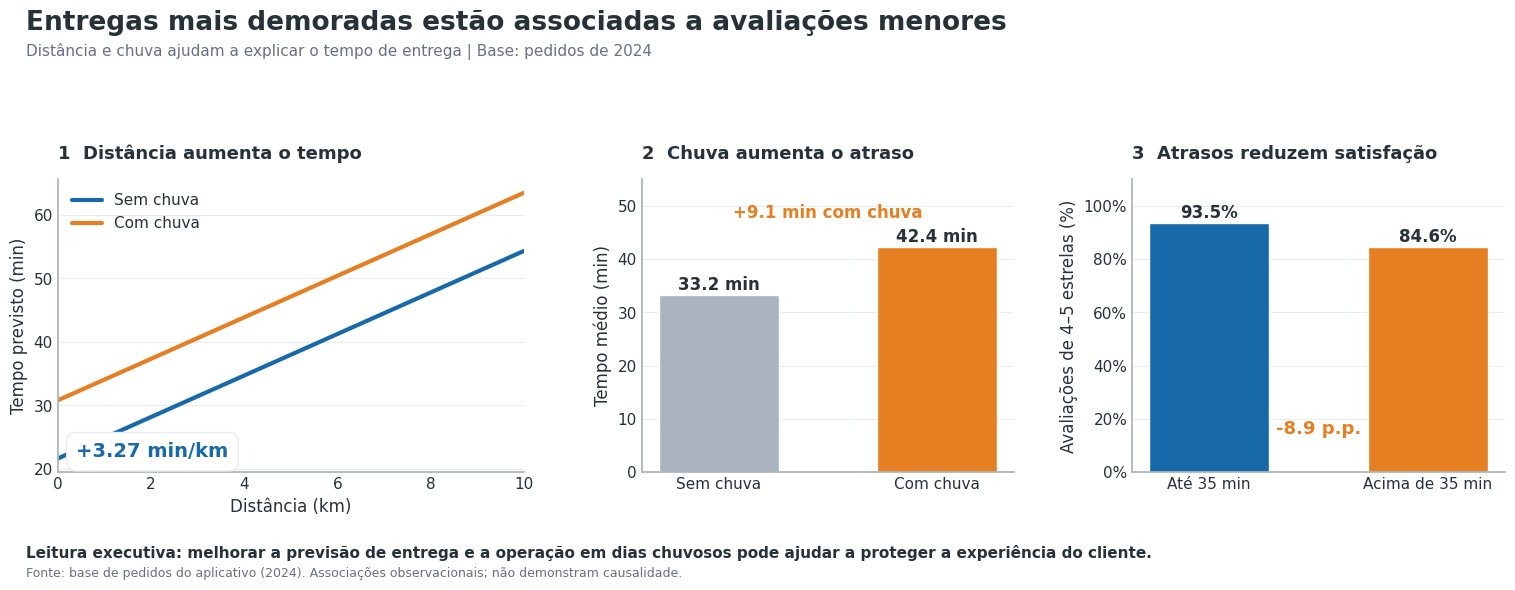

Figura salva em: saidas/figura_principal.png
Resolução: 200 dpi
Tarefa 10.1 concluída!


In [ ]:
# Sua solução aqui

import os

# ============================================================
# TAREFA 10.1 — FIGURA PRINCIPAL PARA A DIRETORIA
# ============================================================

os.makedirs('saidas', exist_ok=True)

AZUL = '#1769AA'
LARANJA = '#E67E22'
CINZA = '#AAB4BE'
TEXTO = '#263238'
GRADE = '#E8EDF2'

# ------------------------------------------------------------
# 1. PREPARAÇÃO DOS DADOS
# ------------------------------------------------------------

# Tempo de entrega por condição climática
dados_chuva = df[
    ['chuva', 'tempo_entrega_min']
].dropna().copy()

mapa_chuva = {
    True: 1, False: 0,
    1: 1, 0: 0,
    'Sim': 1, 'Não': 0,
    'sim': 1, 'não': 0
}

dados_chuva['chuva_bin'] = dados_chuva['chuva'].map(mapa_chuva)

assert dados_chuva['chuva_bin'].notna().all()

medias_chuva = (
    dados_chuva.groupby('chuva_bin')['tempo_entrega_min']
    .mean()
)

# Avaliações positivas por faixa de tempo
dados_avaliacao = df[
    ['tempo_entrega_min', 'avaliacao']
].dropna().copy()

dados_avaliacao['faixa'] = np.where(
    dados_avaliacao['tempo_entrega_min'] <= 35,
    'Até 35 min',
    'Acima de 35 min'
)

positivas = (
    dados_avaliacao
    .assign(positiva=dados_avaliacao['avaliacao'] >= 4)
    .groupby('faixa')['positiva']
    .mean() * 100
)

# Regressão múltipla: distância e chuva
import statsmodels.formula.api as smf

dados_modelo = df[
    ['distancia_km', 'tempo_entrega_min', 'chuva']
].dropna().copy()

dados_modelo['chuva_bin'] = (
    dados_modelo['chuva'].map(mapa_chuva)
)

assert dados_modelo['chuva_bin'].notna().all()

modelo = smf.ols(
    'tempo_entrega_min ~ distancia_km + chuva_bin',
    data=dados_modelo
).fit(cov_type='HC3')

# ------------------------------------------------------------
# 2. CRIAÇÃO DA FIGURA
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5.8),
    gridspec_kw={'width_ratios': [1.25, 1, 1]}
)

fig.patch.set_facecolor('white')

fig.suptitle(
    'Entregas mais demoradas estão associadas a avaliações menores',
    fontsize=19,
    fontweight='bold',
    color=TEXTO,
    x=0.055,
    ha='left',
    y=0.99
)

fig.text(
    0.055, 0.91,
    'Distância e chuva ajudam a explicar o tempo de entrega | '
    'Base: pedidos de 2024',
    fontsize=11,
    color='#667085'
)

# ------------------------------------------------------------
# PAINEL 1 — DISTÂNCIA E TEMPO
# ------------------------------------------------------------

ax = axes[0]

distancias = np.linspace(0, 10, 100)

for chuva_valor, cor, legenda in [
    (0, AZUL, 'Sem chuva'),
    (1, LARANJA, 'Com chuva')
]:
    previsoes = modelo.predict(pd.DataFrame({
        'distancia_km': distancias,
        'chuva_bin': chuva_valor
    }))

    ax.plot(
        distancias,
        previsoes,
        color=cor,
        linewidth=3,
        label=legenda
    )

coef_distancia = modelo.params['distancia_km']

ax.set_title(
    '1  Distância aumenta o tempo',
    loc='left',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.set_xlabel('Distância (km)')
ax.set_ylabel('Tempo previsto (min)')
ax.set_xlim(0, 10)
ax.legend(frameon=False, loc='upper left')

ax.text(
    0.04, 0.05,
    f'+{coef_distancia:.2f} min/km',
    transform=ax.transAxes,
    fontsize=14,
    fontweight='bold',
    color=AZUL,
    bbox=dict(
        facecolor='white',
        edgecolor=GRADE,
        boxstyle='round,pad=0.5'
    )
)

# ------------------------------------------------------------
# PAINEL 2 — CHUVA
# ------------------------------------------------------------

ax = axes[1]

valores_chuva = [
    medias_chuva.loc[0],
    medias_chuva.loc[1]
]

barras = ax.bar(
    ['Sem chuva', 'Com chuva'],
    valores_chuva,
    color=[CINZA, LARANJA],
    width=0.55
)

ax.set_title(
    '2  Chuva aumenta o atraso',
    loc='left',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.set_ylabel('Tempo médio (min)')
ax.set_ylim(0, 55)

for barra, valor in zip(barras, valores_chuva):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1,
        f'{valor:.1f} min',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

diferenca_chuva = valores_chuva[1] - valores_chuva[0]

ax.text(
    0.5, 0.87,
    f'+{diferenca_chuva:.1f} min com chuva',
    transform=ax.transAxes,
    ha='center',
    fontsize=12,
    fontweight='bold',
    color=LARANJA
)

# ------------------------------------------------------------
# PAINEL 3 — AVALIAÇÕES POSITIVAS
# ------------------------------------------------------------

ax = axes[2]

valores_avaliacao = [
    positivas.loc['Até 35 min'],
    positivas.loc['Acima de 35 min']
]

barras = ax.bar(
    ['Até 35 min', 'Acima de 35 min'],
    valores_avaliacao,
    color=[AZUL, LARANJA],
    width=0.55
)

ax.set_title(
    '3  Atrasos reduzem satisfação',
    loc='left',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.set_ylabel('Avaliações de 4–5 estrelas (%)')
ax.set_ylim(0, 110)

ax.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)

for barra, valor in zip(barras, valores_avaliacao):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 2,
        f'{valor:.1f}%',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

diferenca_avaliacao = (
    valores_avaliacao[1] - valores_avaliacao[0]
)

ax.text(
    0.5, 0.13,
    f'{diferenca_avaliacao:.1f} p.p.',
    transform=ax.transAxes,
    ha='center',
    fontsize=13,
    fontweight='bold',
    color=LARANJA
)

# ------------------------------------------------------------
# 3. ACABAMENTO
# ------------------------------------------------------------

for ax in axes:
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=0)

fig.text(
    0.055, 0.045,
    'Leitura executiva: melhorar a previsão de entrega e '
    'a operação em dias chuvosos pode ajudar a proteger '
    'a experiência do cliente.',
    fontsize=11,
    color=TEXTO,
    fontweight='bold'
)

fig.text(
    0.055, 0.012,
    'Fonte: base de pedidos do aplicativo (2024). '
    'Associações observacionais; não demonstram causalidade.',
    fontsize=9,
    color='#667085'
)

plt.tight_layout(
    rect=[0.035, 0.09, 0.99, 0.86],
    w_pad=3
)

# ------------------------------------------------------------
# 4. SALVAR FIGURA
# ------------------------------------------------------------

caminho = 'saidas/figura_principal.png'

fig.savefig(
    caminho,
    dpi=200,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print(f'Figura salva em: {caminho}')
print('Resolução: 200 dpi')
print('Tarefa 10.1 concluída!')


In [ ]:
from google.colab import files
files.download('saidas/figura_principal.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

1. **Impacto da chuva:** Entregas com chuva apresentam tempo médio **9,13 minutos maior (+27,48%)** do que entregas sem chuva (Tarefa 9.1 — teste t de Welch), indicando a necessidade de planejamento logístico específico para condições climáticas adversas.

2. **Influência da distância:** Cada quilômetro adicional está associado a aproximadamente **3,27 minutos a mais** no tempo previsto de entrega, mantendo constante a condição de chuva (Tarefa 10.1 — análise complementar por regressão múltipla), reforçando a importância de estimativas de prazo baseadas na distância e nas condições operacionais.

3. **Tempo de entrega e satisfação:** A proporção de avaliações positivas diminui de **93,49% para 84,57%** quando comparamos entregas de até 35 minutos com entregas acima desse limite (Tarefa 9.3 — correlação de Spearman e análise complementar), mostrando a relevância da pontualidade para a experiência do cliente.

4. **Cupons e aquisição:** Clientes novos representam **34,35% dos pedidos com cupom**, contra **12,81% dos pedidos sem cupom**, uma diferença de **21,54 pontos percentuais** (Tarefa 9.5 — contraste complementar pelo teste qui-quadrado), sugerindo oportunidade de utilizar promoções de forma segmentada, com acompanhamento da rentabilidade.

5. **Diferenças entre cozinhas:** O ticket mediano da culinária japonesa é de **R$ 107,97**, comparado a **R$ 38,42** para doces, uma diferença de **R$ 69,55** (Tarefa 9.4 — Kruskal-Wallis e ANOVA complementar), evidenciando oportunidades para estratégias comerciais específicas por categoria.

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

*Sua resposta aqui*



**1. Aprimorar a eficiência logística:** Implementar previsões de entrega ajustadas pela distância e pelas condições climáticas, com reforço operacional em dias chuvosos. A recomendação decorre dos achados 1 e 2, que identificaram aumento médio de **9,13 minutos com chuva** e acréscimo estimado de **3,27 minutos por quilômetro**, mantendo constante a condição de chuva.

**KPI:** Tempo médio de entrega em dias chuvosos, tendo como referência inicial **42,36 minutos**. O objetivo é reduzir gradualmente esse indicador.

**2. Melhorar a experiência do cliente:** Monitorar entregas acima de 35 minutos, adotando comunicação proativa com os clientes e medidas operacionais para reduzir atrasos. A recomendação está vinculada ao achado 3, que identificou redução de **93,49% para 84,57%** na proporção de avaliações positivas entre as duas faixas de tempo.

**KPI:** Percentual de avaliações positivas nas entregas acima de 35 minutos, com referência inicial de **84,57%**. O objetivo é aumentar esse percentual.

**3. Otimizar investimentos promocionais:** Testar campanhas segmentadas de cupons para novos clientes, considerando o perfil de consumo e o tipo de cozinha. A recomendação está associada aos achados 4 e 5, que identificaram diferenças na participação de clientes novos e nos valores dos pedidos entre categorias.

**KPI:** Percentual de clientes novos entre os pedidos com cupom, com referência inicial de **34,35%**. Como indicador complementar, acompanhar futuramente o **custo de aquisição por cliente (CAC)**, mediante disponibilização dos custos das campanhas.

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

1. **Ausência de causalidade:** Os testes estatísticos realizados identificam associações entre variáveis, mas não comprovam relações de causa e efeito. Portanto, não é possível afirmar, por exemplo, que a utilização de cupons provoca diretamente a aquisição de novos clientes.

2. **Qualidade e completude dos dados:** A presença de valores ausentes e registros inconsistentes, especialmente nas variáveis `avaliacao`, `distancia_km` e `tempo_entrega_min`, pode afetar a precisão das estimativas e introduzir vieses nos resultados. Embora tenham sido aplicados procedimentos de limpeza e tratamento dos dados, essas limitações devem ser consideradas na interpretação das análises.

3. **Limitação temporal e geográfica:** A base de dados contempla **8.058 pedidos registrados em 2024**, nas cidades de São Paulo, Rio de Janeiro e Belo Horizonte. Dessa forma, os resultados refletem o conjunto analisado e não podem ser automaticamente generalizados para outros períodos ou regiões do Brasil.

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [ ]:
# Sua solução aqui
# ============================================================
# TAREFA 11.1 — BASE LIMPA E DICIONÁRIO DE DADOS
# ============================================================

# 1. Criar pasta de saída
os.makedirs('saidas', exist_ok=True)

# 2. Criar cópia da base tratada
base_limpa = df.copy()

# 3. Remover somente colunas auxiliares de análise
# Preservar as variáveis originais e as derivadas úteis:
# data, mes, hora e dia_semana.

colunas_auxiliares = [
    'avaliacao_ausente',
    'outlier_valor_pedido',
    'outlier_taxa_entrega',
    'outlier_distancia_km',
    'outlier_tempo_entrega_min',
    'chuva_bin',
    'faixa',
    'positiva',
    'tempo_invalido',
    'distancia_invalida',
    'outlier_iqr_global',
    'outlier_iqr_cozinha',
    'outlier_z_valor',
    'mediana_cozinha',
    'razao_valor',
    'pedido_grande'
]

base_limpa = base_limpa.drop(
    columns=colunas_auxiliares,
    errors='ignore'
)

# Remover outras colunas temporárias apenas se
# tiverem sido identificadas como auxiliares.

# 4. Salvar a base limpa em CSV
caminho_base = 'saidas/delivery_pedidos_limpo.csv'

base_limpa.to_csv(
    caminho_base,
    index=False,
    encoding='utf-8-sig'
)

# 5. Gerar automaticamente o dicionário de dados
registros_dicionario = []

for coluna in base_limpa.columns:

    serie = base_limpa[coluna]

    # Primeiro valor não nulo como exemplo
    valores_validos = serie.dropna()

    exemplo = (
        str(valores_validos.iloc[0])
        if not valores_validos.empty
        else 'Sem valor disponível'
    )

    registros_dicionario.append({
        'coluna': coluna,
        'tipo': str(serie.dtype),
        'percentual_faltantes': round(
            serie.isna().mean() * 100, 2
        ),
        'exemplo_valor': exemplo
    })

dicionario_dados = pd.DataFrame(registros_dicionario)

# 6. Salvar dicionário em CSV
caminho_dicionario = 'saidas/dicionario_dados.csv'

dicionario_dados.to_csv(
    caminho_dicionario,
    index=False,
    encoding='utf-8-sig'
)

# 7. Exibir resultados
print('TAREFA 11.1 — PUBLICAÇÃO')
print('-' * 60)

print(f'Base limpa salva em: {caminho_base}')
print(f'Dicionário salvo em: {caminho_dicionario}')

print(f'\nQuantidade de pedidos: {len(base_limpa):,}')
print(f'Quantidade de colunas: {base_limpa.shape[1]}')

print('\nDICIONÁRIO DE DADOS')
display(dicionario_dados)

# 8. Validações
assert len(base_limpa) == len(df), (
    'A quantidade de pedidos foi alterada.'
)

assert base_limpa.columns.is_unique, (
    'Existem nomes de colunas duplicados.'
)

assert os.path.exists(caminho_base)
assert os.path.exists(caminho_dicionario)

print('\nValidação concluída!')


TAREFA 11.1 — PUBLICAÇÃO
------------------------------------------------------------
Base limpa salva em: saidas/delivery_pedidos_limpo.csv
Dicionário salvo em: saidas/dicionario_dados.csv

Quantidade de pedidos: 8,058
Quantidade de colunas: 20

DICIONÁRIO DE DADOS


,coluna,tipo,percentual_faltantes,exemplo_valor
0,pedido_id,int64,0.00,500000
1,data_hora,datetime64[ns],0.00,2024-01-01 11:21:00
2,cidade,object,0.00,São Paulo
3,bairro,object,0.00,Tatuapé
4,restaurante_id,object,0.00,R912
5,tipo_cozinha,object,0.00,Hambúrguer
6,plataforma,object,0.00,Android
7,forma_pagamento,object,0.00,Pix
8,cupom,bool,0.00,False
9,cliente_novo,bool,0.00,False



Validação concluída!


In [ ]:
# Para baixar os arquivos;
from google.colab import files

files.download('saidas/delivery_pedidos_limpo.csv')
files.download('saidas/dicionario_dados.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*
## Principais achados

![Figura principal — Distância, chuva e satisfação dos clientes](saidas/figura_principal.png)

*Figura principal: relação entre distância, condições climáticas, tempo de entrega e avaliações positivas, com base nos pedidos analisados em 2024.*

1. **A chuva está associada a um aumento de 27,48% no tempo médio de entrega.** As entregas realizadas com chuva demoram, em média, **9,13 minutos a mais** do que aquelas realizadas sem chuva (Tarefa 9.1 — teste t de Welch; p < 0,001). **Importância:** reforça a necessidade de planejamento logístico e ajuste das previsões de entrega em dias chuvosos.

2. **Cada quilômetro adicional está associado a 3,27 minutos a mais no tempo previsto de entrega.** A regressão múltipla, mantendo constante a condição de chuva, apresentou **R² = 0,637** (análise complementar apresentada na Tarefa 10.1; p < 0,001 para o coeficiente de distância). **Importância:** contribui para aprimorar as estimativas de prazo e o planejamento das rotas.

3. **Entregas acima de 35 minutos apresentam 8,93 pontos percentuais a menos de avaliações positivas.** O percentual de avaliações de 4 ou 5 estrelas passa de **93,49% para 84,57%** (Tarefa 9.3 — correlação de Spearman e análise complementar; p < 0,001 para a correlação). **Importância:** evidencia a relevância de monitorar a pontualidade como indicador associado à satisfação do cliente.

4. **Clientes novos representam 34,35% dos pedidos com cupom, contra 12,81% dos pedidos sem cupom.** A diferença é de **21,54 pontos percentuais** (Tarefa 9.5 — contraste complementar pelo teste qui-quadrado; p < 0,001). **Importância:** sugere oportunidades para campanhas promocionais segmentadas, desde que acompanhadas dos custos e resultados de aquisição.

5. **O ticket mediano apresenta diferença de R$ 69,55 entre as categorias japonesa e doces.** A culinária japonesa apresenta mediana de **R$ 107,97**, enquanto doces registra **R$ 38,42** (Tarefa 9.4 — teste de Kruskal-Wallis e ANOVA complementar; p < 0,001 para Kruskal-Wallis). **Importância:** evidencia oportunidades de estratégias comerciais diferenciadas por tipo de cozinha.

**Síntese executiva:** A principal prioridade operacional é aumentar a previsibilidade das entregas, especialmente em dias chuvosos e trajetos longos. Comercialmente, os resultados apoiam a avaliação de campanhas segmentadas por perfil de cliente e categoria de cozinha. As relações identificadas são estatísticas e não comprovam causalidade.

In [68]:


from pathlib import Path

arquivos = [
    "README.md",
    "saidas/figura_principal.png",
    "saidas/delivery_pedidos_limpo.csv",
    "saidas/dicionario_dados.csv"
]

for arquivo in arquivos:
    caminho = Path(arquivo)
    print(f"{'OK' if caminho.is_file() else 'NÃO ENCONTRADO'} — {arquivo}")


OK — README.md
OK — saidas/figura_principal.png
OK — saidas/delivery_pedidos_limpo.csv
OK — saidas/dicionario_dados.csv


### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [x] Repositório Git criado e repositório público.
- [x] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [x] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [x] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [x] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |